# Using time series analysis for sales and demand forecasting

The work outlined here has been originally submitted as a project for the CAM PACE DS P1 26 Programme.

## **Business context**

The Nielsen BookScan service is the world’s largest continuous book sales tracking service in the world, operating in the UK, Ireland, Australia, New Zealand, India, South Africa, Italy, Spain, Mexico, Brazil, Poland, and Colombia. Nielsen BookScan collects transactional data at the point of sale, directly from tills and dispatch systems of all major book retailers. This ensures detailed and highly accurate sales information on which books are selling and at what price, giving clients the most up-to-date and relevant data. The Nielsen BookScan Total Consumer Market (TCM) data covers approximately 90% of all retail print book purchases in the UK. The remaining sites are specialised, such as gift shops, specialist booksellers, and tourist information centres.


Nielsen BookScan can be used to:

* Monitor titles and authors against the competition and overall market.
* Analyse pricing and discounting by format or category.
* Gauge the success of marketing campaigns and promotions.
* See which categories are growing and declining.
* Learn what works in a given market and how that might differ from other countries.

Nielsen BookScan sales data can be analysed by various criteria, including category, publisher, and format,
allowing users to see which genres are selling in which format. Users can track market trends to see which titles are driving the results, and patterns can easily be interpreted. In addition, the actual selling price is included. This inclusion makes it easier to identify trends for the level of discounting (e.g. by title, author, genre, format, region, and publisher) when analysing book sales.

<br>

## **Project context**

Nielsen is seeking to invest in developing a new service aimed at small to medium-sized independent publishers. This service is aimed at supporting publishers in using historical sales data to make data-driven decisions about their future investment in new publications. Their publisher customers are interested in being able to make more accurate predictions of the overall sales profile post-publication for better stock control and initial investment, but they are also interested in understanding the useful economic life span that a title may have.

Some titles experience fluctuations in sales due to various factors, such as increased media attention or cultural relevance (e.g. the recent resurgence of interest in George Orwell’s 1984). However, certain books endure over time and are often studied in academic settings for their deeper significance.

For this project, Nielsen has provided us with two data sets. The objective is to identify sales patterns that demonstrate seasonal trends or any other traits, providing insights to inform reordering, restocking, and reprinting decisions for various books (by their International Standard Book Number, or ISBN).



In this Notebook, we will:
- Import both datasets, resample weekly sales data to ensure missing weeks are filled with zeros, and convert ISBNs to strings and dates to datetime objects.
- Filter out ISBNs with sales data beyond 2024-07-01, display these ISBNs, and plot their sales patterns for further analysis.
- Investigate the general sales patterns across different time periods (1-12 years vs. 12-24 years) and analyse possible reasons for any noticeable changes.
- Focus on two specific books, The Alchemist and The Very Hungry Caterpillar, for deeper analysis. Filter their data from 2012 onwards for further forecasting.
- Perform time series decomposition, ACF/PACF analysis, and stationarity checks for both books. Use Auto ARIMA to identify the best model and forecast the final 32 weeks of data.
- Prepare the data for machine learning models, create an XGBoost pipeline, tune parameters using grid search, and forecast the final 32 weeks for both books.
- Build and tune an LSTM model using KerasTuner, forecast the final 32 weeks of data, and evaluate the performance using MAE and MAPE.
- Apply both sequential and parallel hybrid models combining SARIMA and LSTM, tune the models, and evaluate their performance using various metrics.
- Aggregate weekly data to monthly data, train XGBoost and SARIMA models to forecast eight months, and compare results with weekly predictions.




## 1.Import packages and data:

### 1.1 Load the appropriate libraries and models.

In [ ]:
# Clear any stuck builds and force-install 3.12 compatible versions
!pip install "numpy>=2.1.0,<2.3" "pmdarima>=2.1.0" "sktime>=0.33.0" --upgrade

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 130.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 688.9/688.9 kB 42.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.2/8.2 MB 94.9 MB/s  0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.1.3
    Uninstalling numpy-2.1.3:
      Successfully uninstalled numpy-2.1.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [pmdarima]


In [ ]:
!pip install keras_tuner --upgrade

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [keras_tuner]


In [ ]:
# Environment and System
import os
import sys

In [ ]:
# Common Libraries
import joblib
from google.colab import files
from google.colab import drive
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.pyplot import cm
import seaborn as sns
import statsmodels.api as sm
import statsmodels.tsa.api as tsa
import pmdarima as pm
import tensorflow as tf
import random
# Classic Timeseries Libraries
import sktime
from sktime.forecasting.arima import AutoARIMA
from datetime import datetime, timedelta
from matplotlib import rc
import statsmodels.graphics.api as smgraphics
from statsmodels.tsa.stattools import adfuller as adf
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import kpss
from pandas.plotting import register_matplotlib_converters
register_matplotlib_converters()
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from pmdarima.arima import auto_arima
from statsmodels.tsa.stattools import acf
from sklearn.metrics import mean_squared_error
from sktime.forecasting.compose import (TransformedTargetForecaster, make_reduction)
from sktime.transformations.adapt import TabularToSeriesAdaptor
from sklearn.preprocessing import PowerTransformer
from sktime.forecasting.model_selection import (ExpandingWindowSplitter, ForecastingGridSearchCV, ForecastingOptunaSearchCV)
from sktime.performance_metrics.forecasting import MeanAbsolutePercentageError
from sktime.forecasting.model_evaluation import evaluate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer


from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_absolute_percentage_error

from sklearn.model_selection import TimeSeriesSplit

plt.rcParams["figure.figsize"] = (10, 5)

# Libraries relevant to ML and DL models
from sktime.forecasting.trend import PolynomialTrendForecaster
from sktime.transformations.detrend import Deseasonalizer, Detrender
from xgboost import XGBRegressor
# from hyperopt import STATUS_OK, Trials, fmin, hp, tpe
from keras.models import Sequential
from keras.layers import Dense, LSTM, Dropout,RepeatVector, TimeDistributed
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping
from sklearn.preprocessing import MinMaxScaler
from keras_tuner.tuners import RandomSearch
from keras_tuner.engine.hyperparameters import HyperParameters


from keras import backend as K

import torch

import warnings
# Suppress all warnings.
warnings.filterwarnings("ignore")

print(" All libraries imported successfully!")


 All libraries imported successfully!


In [ ]:
# Function to control stochastic behaviour when model tuning
def set_random_seed(seed_val):
   # Set the `PYTHONHASHSEED` environment variable at a fixed value
    os.environ['PYTHONHASHSEED']=str(seed_val)
    # Set the `python` built-in pseudo-random generator at a fixed value
    np.random.seed(seed_val)
    # Set the `numpy` pseudo-random generator at a fixed value
    random.seed(seed_val)
    # Set the `tensorflow` pseudo-random generator at a fixed value
    tf.random.set_seed(seed_val)


In [ ]:
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [ ]:
set_random_seed(42)

In [ ]:
torch.cuda.empty_cache()

### 1.2 Import the data set with the provided URL:

In [ ]:
# Construct direct download links from shared drive
url_main="https://drive.usercontent.google.com/download?id="

# UK Weekly Trended Timeline from 200101_202429
fileID_UKWeekly = "redacted"
# Skip authourisation for large data files
no_auth="&authuser=0&confirm=t&uuid=&at="
url_UKWeekly = url_main + fileID_UKWeekly + no_auth

# ISBN List
fileID_ISBN="redacted"
url_ISBN = url_main + fileID_ISBN


In [ ]:
data_dictionary_ISBN=pd.read_excel(url_ISBN, engine="openpyxl", sheet_name=None)

In [ ]:
print(data_dictionary_ISBN.keys())

dict_keys(['F - Adult Fiction', 'S Adult Non-Fiction Specialist', 'T Adult Non-Fiction Trade', "Y Children's, YA & Educational"])


In [ ]:
data_dictionary_UK = pd.read_excel(url_UKWeekly, engine="openpyxl", sheet_name=None)

In [ ]:
print(data_dictionary_UK.keys())

dict_keys(['F Adult Fiction', 'S Adult Non-Fiction Specialist', 'T Adult Non-Fiction Trade', "Y Children's, YA & Educational"])


Ensure to read the data from all four tabs:

In [ ]:
# Combine all sheets in data_dictionary_UK  into a single DataFrame with an extra column to identify the sheet
df_UK_weekly = pd.concat(
    [df.assign(Category=sheet_name) for sheet_name, df in data_dictionary_UK.items()],
    ignore_index=True
)


In [ ]:
# Quick check
df_UK_weekly.head()


,ISBN,Title,Author,Interval,End Date,Volume,Value,ASP,RRP,Binding,Imprint,Publisher Group,Product Class,Category
0,9780002261821,One For My Baby,"Parsons, Tony",200513,2005-04-02,1,15.99,15.99,15.99,Hardback,HarperCollins Publishers,HarperCollins Grp,F1.1 General & Literary Fiction,F Adult Fiction
1,9780002261821,One For My Baby,"Parsons, Tony",200503,2005-01-22,1,15.99,15.99,15.99,Hardback,HarperCollins Publishers,HarperCollins Grp,F1.1 General & Literary Fiction,F Adult Fiction
2,9780002261821,One For My Baby,"Parsons, Tony",200422,2004-05-29,1,11.19,11.19,15.99,Hardback,HarperCollins Publishers,HarperCollins Grp,F1.1 General & Literary Fiction,F Adult Fiction
3,9780002261821,One For My Baby,"Parsons, Tony",200415,2004-04-10,2,27.18,13.59,15.99,Hardback,HarperCollins Publishers,HarperCollins Grp,F1.1 General & Literary Fiction,F Adult Fiction
4,9780002261821,One For My Baby,"Parsons, Tony",200404,2004-01-24,2,22.48,11.24,15.99,Hardback,HarperCollins Publishers,HarperCollins Grp,F1.1 General & Literary Fiction,F Adult Fiction


In [ ]:
df_UK_weekly.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 227224 entries, 0 to 227223
Data columns (total 14 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   ISBN             227224 non-null  int64         
 1   Title            227224 non-null  object        
 2   Author           212345 non-null  object        
 3   Interval         227224 non-null  int64         
 4   End Date         227224 non-null  datetime64[ns]
 5   Volume           227224 non-null  int64         
 6   Value            227224 non-null  float64       
 7   ASP              226881 non-null  float64       
 8   RRP              221262 non-null  float64       
 9   Binding          227224 non-null  object        
 10  Imprint          227224 non-null  object        
 11  Publisher Group  227224 non-null  object        
 12  Product Class    227224 non-null  object        
 13  Category         227224 non-null  object        
dtypes: datetime64[ns](1)

**FIRST IMPRESSIONS ON THE UK WEEKLY DATASET**
* Each book is identified by the features 'ISBN' and 'Title'
* The publishing information of each title/book is stored under features 'Author','Binding', 'Imprint', 'Publisher Group' and the theme is given by 'Product Class' as well as the added column 'Category'.
* The pricing is governed by the 'Value', 'ASP' and 'RRP' features where ASP refers to the Average Selling price and RRP refers to the Recommended Retail Price.
* The features directly relaying time stamps are 'Interval' which is stored as a 64-bit integer and 'End Date' which is provided as a 64-bit integer data type with nanosecond precision. Note the 'Interval' feature

* Finally, the feature 'Volume' refers to the number of copies sold and serves as the target variable - the current study focuses on the sales patterns of various titles and not the revenue in isolation.
* The input features 'Value', 'ASP' and 'RRP' as well as the target feature 'Volume' are numerical variables while the features holding the publishing information and/or serving as an identifier are categorical variables stored as strings. The only exception is the 'ISBN' which is stored as a 64-bit integer.
* Based on the non-null count, there are some missing entries in the 'Author','ASP' and 'RRP' columns.


In [ ]:
# Combine all sheets in data_dictionary_ISBN  into a single DataFrame with an extra column to identify the sheet
df_ISBN = pd.concat(
    [df.assign(Category=sheet_name) for sheet_name, df in data_dictionary_ISBN.items()],
    ignore_index=True
)

In [ ]:
# Quick check
df_ISBN.head()

,ISBN,Title,Author,Imprint,Publisher Group,RRP,Binding,Publication Date,Product Class,Country of Publication,Category
0,9780330375252,Bridget Jones's Diary (Film Tie-in),"Fielding, Helen",Picador,Pan Macmillan Grp,8.99,Paperback,2001-03-23,F1.1 General & Literary Fiction,United Kingdom,F - Adult Fiction
1,9780140276336,White Teeth,"Smith, Zadie",Penguin Books Ltd,Penguin Grp,9.99,Paperback,2001-01-25,F1.1 General & Literary Fiction,United Kingdom,F - Adult Fiction
2,9780006512134,Man and Boy,"Parsons, Tony",HarperCollins Publishers,HarperCollins Grp,8.99,Paperback,2000-03-06,F1.1 General & Literary Fiction,United Kingdom,F - Adult Fiction
3,9780099280255,"Brethren,The","Grisham, John",Arrow Books,Random House Grp,6.99,Paperback,2000-12-27,"F2.1 Crime, Thriller & Adventure",United Kingdom,F - Adult Fiction
4,9780552998727,Marrying The Mistress:an irresistible and grip...,"Trollope, Joanna",Black Swan,Transworld Grp,10.99,Paperback,2001-02-01,F1.1 General & Literary Fiction,United Kingdom,F - Adult Fiction


In [ ]:
# Information on data types
df_ISBN.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   ISBN                    500 non-null    int64         
 1   Title                   500 non-null    object        
 2   Author                  426 non-null    object        
 3   Imprint                 500 non-null    object        
 4   Publisher Group         500 non-null    object        
 5   RRP                     473 non-null    float64       
 6   Binding                 500 non-null    object        
 7   Publication Date        500 non-null    datetime64[ns]
 8   Product Class           500 non-null    object        
 9   Country of Publication  500 non-null    object        
 10  Category                500 non-null    object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(8)
memory usage: 43.1+ KB


In [ ]:
df_ISBN.nunique()

,0
ISBN,500
Title,483
Author,304
Imprint,155
Publisher Group,58
RRP,69
Binding,2
Publication Date,297
Product Class,101
Country of Publication,3


**THE ISBN DATASET**

* This dataset focuses mainly on publishing information per unique title along with the retail price represented by the RRP feature.

* Again, each book is identified by the unique features 'ISBN' and 'Title' whereas the publishing information is given by 'Author','Imprint','Publisher Group','Binding', 'Country of Publication' and 'Publication Date' which informs of a time frame for the current analysis and is provided as type 'datetime64[ns]'.

* As before, the theme is given by 'Product Class' as well as the added column 'Category'.

* It can be seen from the non-null count that the 'Author' and 'RRP' features has some missing values.
* The unique value counts per feature suggests some titles may have multiple ISBNs (likely two ISBNs for the same title) - it is the natural expectation that every title would have a unique ISBN identifier.



## 2.Conducting initial data investigation:

### 2.1 Convert the ISBNs to a string value.


In [ ]:
# Replace spaces with underscores across all column names for ease of processing
df_UK_weekly.columns = df_UK_weekly.columns.str.replace(' ', '_')
df_ISBN.columns = df_ISBN.columns.str.replace(' ', '_')


Since Pandas lacks a variable-length string type, strings are presented as type object as is the case for the 'ISBN' column in the ISBN dataframe. In contrast, the ISBN identifier is stored as an integer in the UK Weekly dataframe. In both cases, it makes more sense to store a feature acting as an identifer in the string format, such that an accidental weight is not assigned based on the ISBN value, during modelling of the dataset.

In [ ]:
# Convert ISBN to string in both dataframes
df_UK_weekly['ISBN'] = df_UK_weekly['ISBN'].astype(str)
df_ISBN['ISBN']=df_ISBN['ISBN'].astype(str)

Next, let's set index to the date and time to follow the data structure more clearly:

In [ ]:
# Ensure 'End_Date' is datetime and set as index
df_UK_weekly['End_Date'] = pd.to_datetime(df_UK_weekly['End_Date'])

In [ ]:
# Set 'End_Date' as the index
df_UK_weekly.set_index('End_Date', inplace=True)

In [ ]:
# Quick Check
df_UK_weekly.head()

,ISBN,Title,Author,Interval,Volume,Value,ASP,RRP,Binding,Imprint,Publisher_Group,Product_Class,Category
End_Date,,,,,,,,,,,,,
2005-04-02,9780002261821,One For My Baby,"Parsons, Tony",200513,1,15.99,15.99,15.99,Hardback,HarperCollins Publishers,HarperCollins Grp,F1.1 General & Literary Fiction,F Adult Fiction
2005-01-22,9780002261821,One For My Baby,"Parsons, Tony",200503,1,15.99,15.99,15.99,Hardback,HarperCollins Publishers,HarperCollins Grp,F1.1 General & Literary Fiction,F Adult Fiction
2004-05-29,9780002261821,One For My Baby,"Parsons, Tony",200422,1,11.19,11.19,15.99,Hardback,HarperCollins Publishers,HarperCollins Grp,F1.1 General & Literary Fiction,F Adult Fiction
2004-04-10,9780002261821,One For My Baby,"Parsons, Tony",200415,2,27.18,13.59,15.99,Hardback,HarperCollins Publishers,HarperCollins Grp,F1.1 General & Literary Fiction,F Adult Fiction
2004-01-24,9780002261821,One For My Baby,"Parsons, Tony",200404,2,22.48,11.24,15.99,Hardback,HarperCollins Publishers,HarperCollins Grp,F1.1 General & Literary Fiction,F Adult Fiction


Currently the dataframe is not sorted by the date but by the original order of the ISBN code.

In [ ]:
# Sort the dataframe chronologically by the End_Date index
df_UK_weekly.sort_index(inplace=True)

In [ ]:
# Check to ensure it is sorted:
display(df_UK_weekly)

,ISBN,Title,Author,Interval,Volume,Value,ASP,RRP,Binding,Imprint,Publisher_Group,Product_Class,Category
End_Date,,,,,,,,,,,,,
2001-01-06,9781841461502,KS2 English Study Book - Ages 7-11,CGP Books,200101,700,2370.97,3.3871,6.50,Paperback,Coordination Group Publications Ltd (CGP),Coordination Group Publications,Y5.1 School Textbooks & Study Guides: Literatu...,"Y Children's, YA & Educational"
2001-01-06,9780130125071,Java How to Program,"Deitel, Harvey M. & Deitel, Paul J.",200101,72,2267.40,31.4917,38.09,Hardback,Prentice-Hall,Pearson Education: Prof Grp,S10.2 Computing: Professional & Programming,S Adult Non-Fiction Specialist
2001-01-06,9780563384311,Delia's How To Cook: Book Two,"Smith, Delia",200101,1878,21032.36,11.1993,20.00,Hardback,BBC Books (Random House),Random House Grp,T16.0 Food & Drink: General,T Adult Non-Fiction Trade
2001-01-06,9780340704622,Business Studies,"Marcouse, Ian & Martin, Barry & Surridge, Malc...",200101,90,1698.07,18.8674,NaN,Paperback,Hodder & Stoughton Ltd,Hodder & Stoughton Grp,"S4.0T Business, Accounting & Vocational: Textb...",S Adult Non-Fiction Specialist
2001-01-06,9781841462301,KS3 Science Revision Guide – Higher (includes ...,CGP Books,200101,463,1618.41,3.4955,6.50,Hardback,Coordination Group Publications Ltd (CGP),Coordination Group Publications,"Y5.3 School Textbooks & Study Guides: Maths, S...","Y Children's, YA & Educational"
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-07-20,9780099771517,Memoirs of a Geisha,"Golden, Arthur",202429,43,409.64,9.5265,9.99,Paperback,Vintage,Random House Grp,F1.1 General & Literary Fiction,F Adult Fiction
2024-07-20,9780241003008,"Very Hungry Caterpillar, The","Carle, Eric",202429,2574,11507.46,4.4707,7.99,Hardback,Puffin Books,Penguin Grp,Y1.3 Picture Books,"Y Children's, YA & Educational"
2024-07-20,9780006647553,Mog’s Bad Thing,"Kerr, Judith",202429,11,86.89,7.8991,7.99,Paperback,HarperCollins Publishers,HarperCollins Grp,Y1.3 Picture Books,"Y Children's, YA & Educational"


As pointed earlier, there are some titles with missing author and price information.

In [ ]:
# Check for missing value counts first
df_UK_weekly.isna().sum()

,0
ISBN,0
Title,0
Author,14879
Interval,0
Volume,0
Value,0
ASP,343
RRP,5962
Binding,0
Imprint,0


### 2.2 Resample the data and fill in missing values with 0, such that even weeks with 0 sales is represented : The data provided is weekly data, meaning if no sales happened in a particular week, there will be no data representation for that week. This means that the data is not at fixed intervals.


It can be seen that resampling by week has introduced previously non-recorded weeks wherein no sales data was reported for a given ISBN/title:

In [ ]:
# Group each title by 'ISBN' and sum the sale values over a week
df_UK_weekly_imputed = df_UK_weekly.groupby('ISBN').resample('W').sum().fillna(0)

In [ ]:
# Check again
df_UK_weekly_imputed

ISBN                        Title  \
ISBN          End_Date                                                 
9780001713031 2001-01-07  9780001713031          Cat in the Hat, The   
              2001-01-14  9780001713031          Cat in the Hat, The   
              2001-01-21  9780001713031          Cat in the Hat, The   
              2001-01-28  9780001713031          Cat in the Hat, The   
              2001-02-04  9780001713031          Cat in the Hat, The   
...                                 ...                          ...   
9781903840122 2008-11-23              0                            0   
              2008-11-30              0                            0   
              2008-12-07  9781903840122  Wicked Book of Txt Tlk, The   
              2008-12-14  9781903840122  Wicked Book of Txt Tlk, The   
              2008-12-21  9781903840122  Wicked Book of Txt Tlk, The   

                              Author  Interval  Volume    Value     ASP   RRP  \
ISBN          End_Date                                                          
9780001713031 2001-01-07  Seuss, Dr.    200101     522  2544.07  4.8737  4.99   
              2001-01-14  Seuss, Dr.    200102     379  1842.21  4.8607  4.99   
              2001-01-21  Seuss, Dr.    200103     393  1921.19  4.8885  4.99   
              2001-01-28  Seuss, Dr.    200104     369  1785.31  4.8382  4.99   
              2001-02-04  Seuss, Dr.    200105     423  2060.07  4.8701  4.99   
...                              ...       ...     ...      ...     ...   ...   
9781903840122 2008-11-23           0         0       0     0.00  0.0000  0.00   
              2008-11-30           0         0       0     0.00  0.0000  0.00   
              2008-12-07           0    200849       1     0.40  0.4000  1.99   
              2008-12-14           0    200850       4     1.60  0.4000  1.99   
              2008-12-21           0    200851       2     2.38  1.1900  1.99   

                            Binding       Imprint     Publisher_Group  \
ISBN          End_Date                                                  
9780001713031 2001-01-07  Paperback       Collins   HarperCollins Grp   
              2001-01-14  Paperback       Collins   HarperCollins Grp   
              2001-01-21  Paperback       Collins   HarperCollins Grp   
              2001-01-28  Paperback       Collins   HarperCollins Grp   
              2001-02-04  Paperback       Collins   HarperCollins Grp   
...                             ...           ...                 ...   
9781903840122 2008-11-23          0             0                   0   
              2008-11-30          0             0                   0   
              2008-12-07  Paperback  Buster Books  Michael O'Mara Grp   
              2008-12-14  Paperback  Buster Books  Michael O'Mara Grp   
              2008-12-21  Paperback  Buster Books  Michael O'Mara Grp   

                                                       Product_Class  \
ISBN          End_Date                                                 
9780001713031 2001-01-07              Y4.2 Reference & Home Learning   
              2001-01-14              Y4.2 Reference & Home Learning   
              2001-01-21              Y4.2 Reference & Home Learning   
              2001-01-28              Y4.2 Reference & Home Learning   
              2001-02-04              Y4.2 Reference & Home Learning   
...                                                              ...   
9781903840122 2008-11-23                                           0   
              2008-11-30                                           0   
              2008-12-07  Y4.1 Children's General Interest & Leisure   
              2008-12-14  Y4.1 Children's General Interest & Leisure   
              2008-12-21  Y4.1 Children's General Interest & Leisure   

                                                Category  
ISBN          End_Date                                    
9780001713031 2001-01-07  Y Children's,

Note that when the date is set as the index, the ISBN will be falsely recorded as 0 for rows belonging to previously non-recorded weeks and the full row will remain filled with zeros. Since we only need the ISBN and the volume for the analysis, the zero-valued ISBNs are filled by their index.

In [ ]:
# To fill zero ISBNS
df_UK_weekly_imputed['ISBN']=df_UK_weekly_imputed.index.get_level_values('ISBN')

In [ ]:
df_UK_weekly_imputed

ISBN                        Title  \
ISBN          End_Date                                                 
9780001713031 2001-01-07  9780001713031          Cat in the Hat, The   
              2001-01-14  9780001713031          Cat in the Hat, The   
              2001-01-21  9780001713031          Cat in the Hat, The   
              2001-01-28  9780001713031          Cat in the Hat, The   
              2001-02-04  9780001713031          Cat in the Hat, The   
...                                 ...                          ...   
9781903840122 2008-11-23  9781903840122                            0   
              2008-11-30  9781903840122                            0   
              2008-12-07  9781903840122  Wicked Book of Txt Tlk, The   
              2008-12-14  9781903840122  Wicked Book of Txt Tlk, The   
              2008-12-21  9781903840122  Wicked Book of Txt Tlk, The   

                              Author  Interval  Volume    Value     ASP   RRP  \
ISBN          End_Date                                                          
9780001713031 2001-01-07  Seuss, Dr.    200101     522  2544.07  4.8737  4.99   
              2001-01-14  Seuss, Dr.    200102     379  1842.21  4.8607  4.99   
              2001-01-21  Seuss, Dr.    200103     393  1921.19  4.8885  4.99   
              2001-01-28  Seuss, Dr.    200104     369  1785.31  4.8382  4.99   
              2001-02-04  Seuss, Dr.    200105     423  2060.07  4.8701  4.99   
...                              ...       ...     ...      ...     ...   ...   
9781903840122 2008-11-23           0         0       0     0.00  0.0000  0.00   
              2008-11-30           0         0       0     0.00  0.0000  0.00   
              2008-12-07           0    200849       1     0.40  0.4000  1.99   
              2008-12-14           0    200850       4     1.60  0.4000  1.99   
              2008-12-21           0    200851       2     2.38  1.1900  1.99   

                            Binding       Imprint     Publisher_Group  \
ISBN          End_Date                                                  
9780001713031 2001-01-07  Paperback       Collins   HarperCollins Grp   
              2001-01-14  Paperback       Collins   HarperCollins Grp   
              2001-01-21  Paperback       Collins   HarperCollins Grp   
              2001-01-28  Paperback       Collins   HarperCollins Grp   
              2001-02-04  Paperback       Collins   HarperCollins Grp   
...                             ...           ...                 ...   
9781903840122 2008-11-23          0             0                   0   
              2008-11-30          0             0                   0   
              2008-12-07  Paperback  Buster Books  Michael O'Mara Grp   
              2008-12-14  Paperback  Buster Books  Michael O'Mara Grp   
              2008-12-21  Paperback  Buster Books  Michael O'Mara Grp   

                                                       Product_Class  \
ISBN          End_Date                                                 
9780001713031 2001-01-07              Y4.2 Reference & Home Learning   
              2001-01-14              Y4.2 Reference & Home Learning   
              2001-01-21              Y4.2 Reference & Home Learning   
              2001-01-28              Y4.2 Reference & Home Learning   
              2001-02-04              Y4.2 Reference & Home Learning   
...                                                              ...   
9781903840122 2008-11-23                                           0   
              2008-11-30                                           0   
              2008-12-07  Y4.1 Children's General Interest & Leisure   
              2008-12-14  Y4.1 Children's General Interest & Leisure   
              2008-12-21  Y4.1 Children's General Interest & Leisure   

                                                Category  
ISBN          End_Date                                    
9780001713031 2001-01-07  Y Children's,

### 2.3 Convert date to datetime object. (Setting the date as the index has several advantages for time series handling.)

In [ ]:
# Remove duplicate index level by droping 'ISBN' as the index
df_UK_weekly_imputed.index = df_UK_weekly_imputed.index.droplevel(0)
# Reset index
df_UK_weekly_imputed = df_UK_weekly_imputed.reset_index()

In [ ]:
# Quick Check
df_UK_weekly_imputed

,End_Date,ISBN,Title,Author,Interval,Volume,Value,ASP,RRP,Binding,Imprint,Publisher_Group,Product_Class,Category
0,2001-01-07,9780001713031,"Cat in the Hat, The","Seuss, Dr.",200101,522,2544.07,4.8737,4.99,Paperback,Collins,HarperCollins Grp,Y4.2 Reference & Home Learning,"Y Children's, YA & Educational"
1,2001-01-14,9780001713031,"Cat in the Hat, The","Seuss, Dr.",200102,379,1842.21,4.8607,4.99,Paperback,Collins,HarperCollins Grp,Y4.2 Reference & Home Learning,"Y Children's, YA & Educational"
2,2001-01-21,9780001713031,"Cat in the Hat, The","Seuss, Dr.",200103,393,1921.19,4.8885,4.99,Paperback,Collins,HarperCollins Grp,Y4.2 Reference & Home Learning,"Y Children's, YA & Educational"
3,2001-01-28,9780001713031,"Cat in the Hat, The","Seuss, Dr.",200104,369,1785.31,4.8382,4.99,Paperback,Collins,HarperCollins Grp,Y4.2 Reference & Home Learning,"Y Children's, YA & Educational"
4,2001-02-04,9780001713031,"Cat in the Hat, The","Seuss, Dr.",200105,423,2060.07,4.8701,4.99,Paperback,Collins,HarperCollins Grp,Y4.2 Reference & Home Learning,"Y Children's, YA & Educational"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
382866,2008-11-23,9781903840122,0,0,0,0,0.00,0.0000,0.00,0,0,0,0,0
382867,2008-11-30,9781903840122,0,0,0,0,0.00,0.0000,0.00,0,0,0,0,0
382868,2008-12-07,9781903840122,"Wicked Book of Txt Tlk, The",0,200849,1,0.40,0.4000,1.99,Paperback,Buster Books,Michael O'Mara Grp,Y4.1 Children's General Interest & Leisure,"Y Children's, YA & Educational"
382869,2008-12-14,9781903840122,"Wicked Book of Txt Tlk, The",0,200850,4,1.60,0.4000,1.99,Paperback,Buster Books,Michael O'Mara Grp,Y4.1 Children's General Interest & Leisure,"Y Children's, YA & Educational"


In [ ]:
# Check for null value counts again
df_UK_weekly_imputed.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 382871 entries, 0 to 382870
Data columns (total 14 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   End_Date         382871 non-null  datetime64[ns]
 1   ISBN             382871 non-null  object        
 2   Title            382871 non-null  object        
 3   Author           382871 non-null  object        
 4   Interval         382871 non-null  int64         
 5   Volume           382871 non-null  int64         
 6   Value            382871 non-null  float64       
 7   ASP              382871 non-null  float64       
 8   RRP              382871 non-null  float64       
 9   Binding          382871 non-null  object        
 10  Imprint          382871 non-null  object        
 11  Publisher_Group  382871 non-null  object        
 12  Product_Class    382871 non-null  object        
 13  Category         382871 non-null  object        
dtypes: datetime64[ns](1)

In [ ]:
# Set End_Date as index
df_UK_weekly_imputed.set_index('End_Date', inplace=True)

# Sort the dataframe chronologically
df_UK_weekly_imputed.sort_index(inplace=True)

In [ ]:
# Final check
df_UK_weekly_imputed

,ISBN,Title,Author,Interval,Volume,Value,ASP,RRP,Binding,Imprint,Publisher_Group,Product_Class,Category
End_Date,,,,,,,,,,,,,
2001-01-07,9780001713031,"Cat in the Hat, The","Seuss, Dr.",200101,522,2544.07,4.8737,4.99,Paperback,Collins,HarperCollins Grp,Y4.2 Reference & Home Learning,"Y Children's, YA & Educational"
2001-01-07,9780003224764,Psychology for AS-level,"Cardwell, Mike & Clark, Liz & Meldrum, Claire",200101,40,482.56,12.0640,12.99,Paperback,Collins Educational,HarperCollins Grp,S2.2T Psychology: Textbooks & Study Guides,S Adult Non-Fiction Specialist
2001-01-07,9780718144395,"Return of the Naked Chef, The","Oliver, Jamie",200101,5742,83782.37,14.5911,20.00,Hardback,Michael Joseph,Penguin Grp,T16.0 Food & Drink: General,T Adult Non-Fiction Trade
2001-01-07,9780552998727,Marrying the Mistress,"Trollope, Joanna",200101,573,4005.18,6.9898,10.99,Paperback,Black Swan,Transworld Grp,F1.1 General & Literary Fiction,F Adult Fiction
2001-01-07,9780115519772,Highway Code,0,200101,6185,9168.94,1.4824,1.49,Paperback,Stationery Office Books,The Stationery Office Grp,T12.2 Driving & The Highway Code,T Adult Non-Fiction Trade
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-07-21,9780744523232,We're Going on a Bear Hunt,"Rosen, Michael",202429,1556,6546.74,4.2074,7.99,Paperback,Walker Books Ltd,Walker Grp,Y1.3 Picture Books,"Y Children's, YA & Educational"
2024-07-21,9780552145060,Journey,"Steel, Danielle",202429,2,18.38,9.1900,9.99,Paperback,Corgi Books,Transworld Grp,F1.1 General & Literary Fiction,F Adult Fiction
2024-07-21,9780006647553,Mog’s Bad Thing,"Kerr, Judith",202429,11,86.89,7.8991,7.99,Paperback,HarperCollins Publishers,HarperCollins Grp,Y1.3 Picture Books,"Y Children's, YA & Educational"


### 2.4 Filter out the ISBNs (from all four tabs) wherein sales data exists beyond 2024-07-01.

Show all the ISBNs that satisfy this criterion. Capture this in your report.

In [ ]:
# Filter df_UK_weekly for records with sales data beyond 2024-07-01
df_UK_weekly_filtered = df_UK_weekly_imputed[df_UK_weekly_imputed.index > '2024-07-01']

In [ ]:
df_UK_weekly_filtered.shape

(168, 13)

In [ ]:
# Extract the list of unique ISBNs that satisfy the criterion
ISBN_filtered=df_UK_weekly_filtered['ISBN'].unique()

In [ ]:
# Pring the list
print('ISBNs wherein sales data exists beyond 2024-07-01')
print('=' * 70)
print(ISBN_filtered, '\n')
print(f'That is {len(ISBN_filtered)} unique ISBN codes.')

ISBNs wherein sales data exists beyond 2024-07-01
['9780099244721' '9780340786055' '9780140276336' '9780099422587'
 '9780719559792' '9781841461502' '9780006514213' '9780261103252'
 '9780140275421' '9780349113609' '9780722532935' '9780099286387'
 '9780752844299' '9780340766057' '9780552998482' '9780552998444'
 '9780552997348' '9780349112763' '9780552145954' '9780552145053'
 '9781841462509' '9780552997034' '9780593048153' '9780091867775'
 '9780099285823' '9780440864554' '9780552998000' '9781841150437'
 '9780552998727' '9780140285215' '9780330355667' '9780006647553'
 '9780006514091' '9780099771517' '9780749397548' '9781841460307'
 '9780140259506' '9780140276619' '9780224060875' '9780552145060'
 '9780140294231' '9780007101887' '9780241003008' '9780747268161'
 '9780340696767' '9780749395698' '9780099428558' '9780744523232'
 '9780006531203' '9781841462400' '9781841462301' '9780091816971'
 '9780140281293' '9780006550433' '9780752846576' '9780006512134'
 '9781841460406' '9780440864141' '978014

### 2.5 Plot the data of all the ISBNs from the previous step by placing them in a loop.


In [ ]:
# Create a plot grid
num_plots = len(ISBN_filtered)
# Calculate number of rows needed
rows = (num_plots // 6) + 1
# 8 plots per row
cols = 6

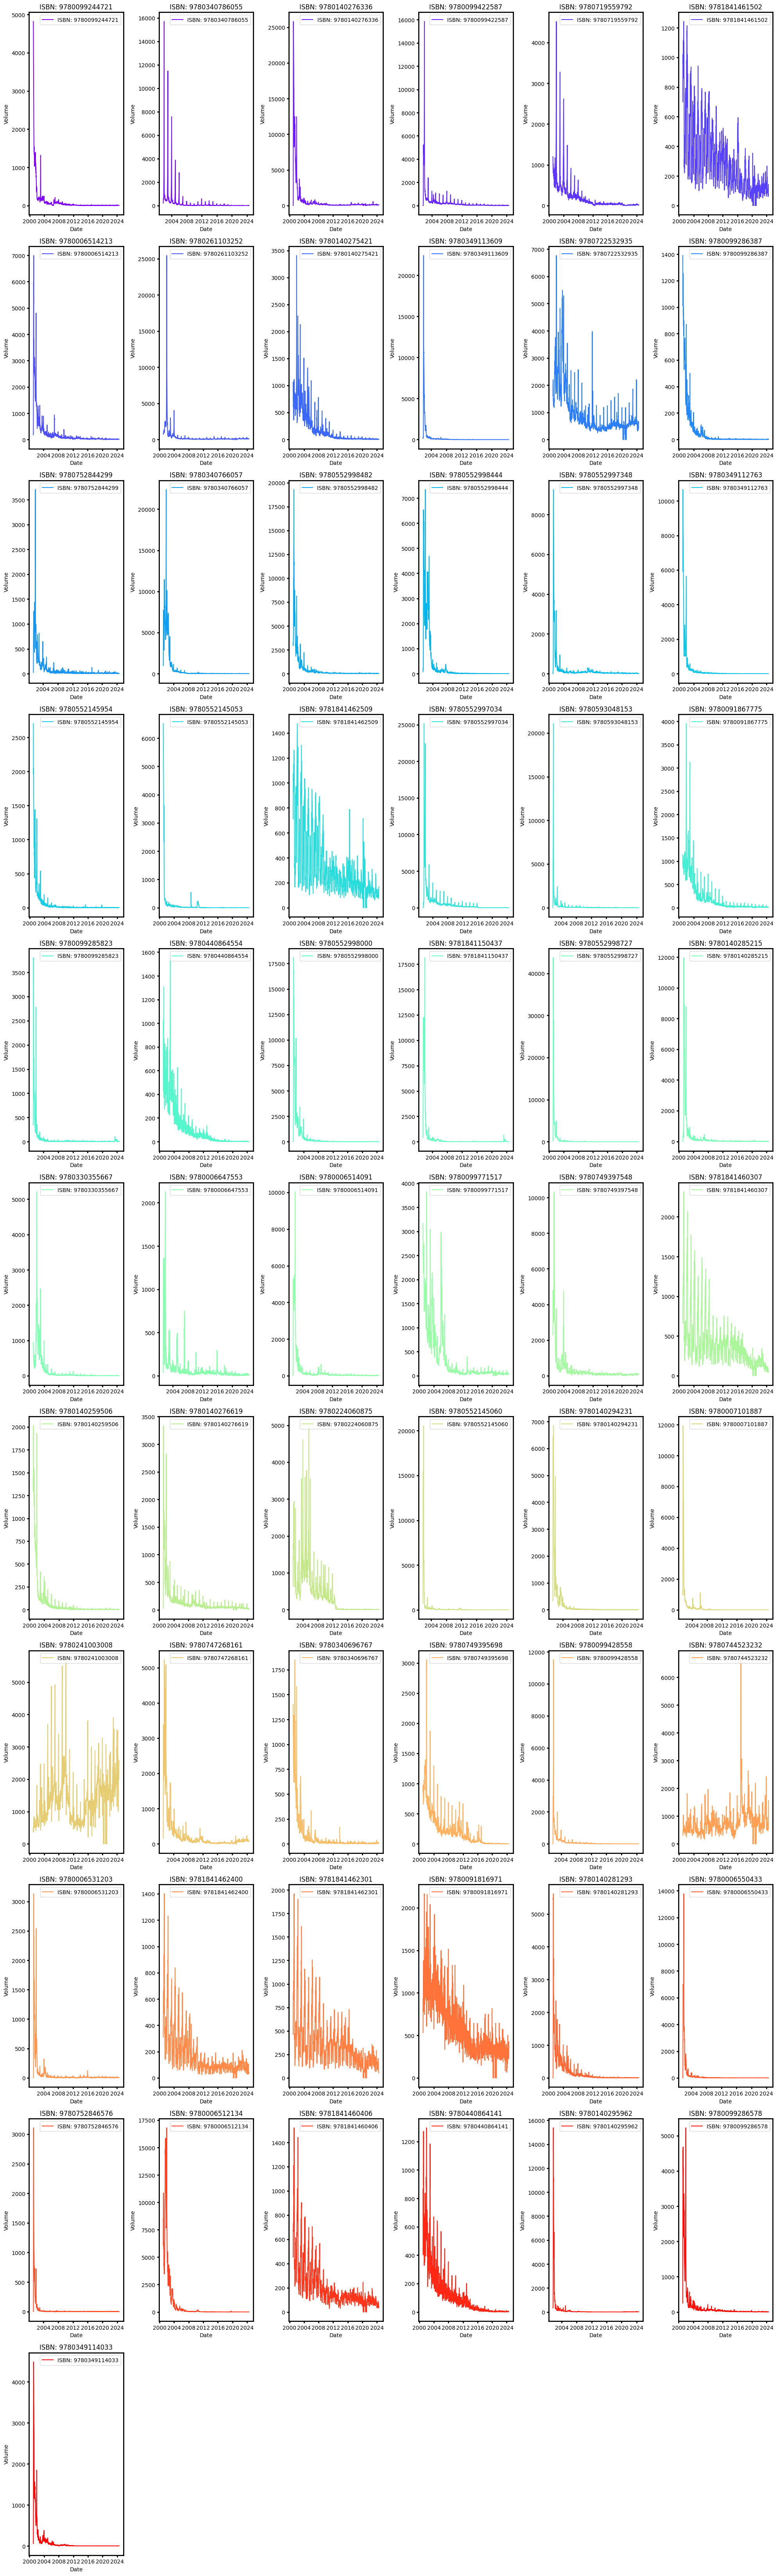

In [ ]:
# Create the figure and axes for subplots
fig, axes = plt.subplots(rows, cols, figsize=(20, 6 * rows))

# Flatten the axes array for easy indexing
axes = axes.flatten()
# Choose a colour palette
colors = iter(cm.rainbow(np.linspace(0, 1, len(ISBN_filtered))))

# Loop through each ISBN and plot the data from the original df_UK_weekly dataframe
for idx, isbn in enumerate(ISBN_filtered):
    # Filter the original df_UK_weekly to get data for the current ISBN
    df_UK_weekly_isbn = df_UK_weekly_imputed[df_UK_weekly_imputed['ISBN'] == isbn]

    # Plot the data
    axes[idx].plot(df_UK_weekly_isbn.index, df_UK_weekly_isbn['Volume'], color= next(colors), label=f'ISBN: {isbn}')
    axes[idx].set_title(f'ISBN: {isbn}')
    axes[idx].set_xlabel('Date')
    axes[idx].set_ylabel('Volume')
    axes[idx].legend()

# Remove unused subplots if there are any
for idx in range(num_plots, len(axes)):
    fig.delaxes(axes[idx])

for i in range(len(ISBN_filtered)+1):
 axes[i].tick_params(width=2)
 for axs in ['top','bottom','left','right']:
    axes[i].spines[axs].set_linewidth(2)

# Adjust layout for better spacing
plt.tight_layout()

# plt.savefig('rainbowplots.svg')

### 2.6 Investigate these plots to understand the general sales patterns, and comment on the general patterns visible in the data. Do the patterns drastically change for the period 1–12 years vs the period 12–24 years? Explain why or why not with possible reasons.

* Almost every title experiences a sharp rise starting from 2001 which is when Nielsen BookScan starts tracking consumer point-of-sale data for the book/publishing sector, followed by some oscillations in sales volume and finally, a continuous decline with the overall trend resembling an exponential decay.

* The only exceptions are the books with ISBNs '9780241003008' and '9780744523232' which present with a more flat trend yet high variance.

* Considering the plots cover a relatively long range of 23 years with large variance, it is difficult to infer a seasonal pattern especially considering the large fluctuations which typically occur within the first 4-8 years.

* That said, some titles such as that corresponding to ISBN '9780552997034' and '9780140276619' *appear to present* with some seasonality with peaks occurring over a given cycle. Yet in both cases, the sales curve eventually dampens.

* To understand the sales patterns of the 61 titles represented in the plots, the following discussion will focus on the general trends dictating consumer habits and avoid speculating on the potential reasons behind the popularity of a particular title or genre.

* For instance, it is important to note the year 2008 coincides with the Great Recession and the year 2007 marks the release of the first Kindle e-reader.

* It is also well known that the technological advancements such as widespread use of smart phones and the availability of faster broadband started influencing consumer behaviour which would mean a massive rise for the e-commerce sector and instability for the high-street retailers starting from 2000s and continuing through to 2010s.

* The publishing sector was one of the first affected considering the ever-expanding popularity and market share of Amazon and e-bay, the first most notable e-commerce platforms in the world. Note that Amazon was established as an online bookstore in 1994.

* In that vein, consumers no longer have to purchase books in print be it online or in store, and have other options including various e-book and audio-book platforms.

* This period of constant change is reflected in the book sales data where the massive fluctuations start to dampen typically within the 2004-2008 window.

* Thus, for most book titles the period covering the 12-24 years appear more stable conpared to the period 1-12 years.

* However, while the 1-12 years include the Great Recession, the 12-24 years include the Covid-19 pandemic which are both world-changing events.


### 2.7 Select two books from the list (The Alchemist and The Very Hungry Caterpillar) for further analysis. Focus on the period >2012-01-01. Filter the sales data for both these books to retain the date range >2012-01-01, until the final datapoint.

In [ ]:
# Extract the unique ISBN codes for the two books
alchemist_isbns = df_ISBN[df_ISBN['Title'].str.contains('alchemist', case=False, na=False)]['ISBN'].astype(str).unique()
caterpillar_isbns = df_ISBN[df_ISBN['Title'].str.contains('caterpillar', case=False, na=False)]['ISBN'].astype(str).unique()

In [ ]:
print("The Alchemist ISBNs:")
print(alchemist_isbns, '\n')

print("The Very Hungry Caterpillar ISBNs:")
print(caterpillar_isbns)


The Alchemist ISBNs:
['9780722532935'] 

The Very Hungry Caterpillar ISBNs:
['9780241003008' '9780140500875']


In [ ]:
# Apply the date filter to df_UK_weekly
df_UK_weekly_post2012 = df_UK_weekly_imputed[df_UK_weekly_imputed.index > '2012-01-01']

In [ ]:
# For The Very Hungry Caterpillar ISBNs
for isbn in caterpillar_isbns:
    volume_caterpillar = df_UK_weekly_post2012[df_UK_weekly_post2012['ISBN'] == isbn]['Volume'].sum()
    print(f"Volume for ISBN {isbn} (The Very Hungry Caterpillar) after 2012-01-01: {volume_caterpillar}")

# For The Alchemist ISBNs
for isbn in alchemist_isbns:
    volume_alchemist = df_UK_weekly_post2012[df_UK_weekly_post2012['ISBN'] == isbn]['Volume'].sum()
    print(f"Volume for ISBN {isbn} (The Alchemist) after 2012-01-01: {volume_alchemist}")

Volume for ISBN 9780241003008 (The Very Hungry Caterpillar) after 2012-01-01: 883534
Volume for ISBN 9780140500875 (The Very Hungry Caterpillar) after 2012-01-01: 2
Volume for ISBN 9780722532935 (The Alchemist) after 2012-01-01: 345907


Considering the second ISBN for 'The Very Hungry Caterpillar' has a sales volume of only 2, it can be disregarded. Thus, the remainder of the analysis will focus on the ISBNs '9780241003008' and '9780722532935'.

In [ ]:
# Directly filter df_UK_weekly_post2012 for the two ISBNs
df_UK_weekly_post2012 = df_UK_weekly_post2012[df_UK_weekly_post2012['ISBN'].isin(['9780241003008', '9780722532935'])]


In [ ]:
# Check the filtered dataframe
display(df_UK_weekly_post2012)

,ISBN,Title,Author,Interval,Volume,Value,ASP,RRP,Binding,Imprint,Publisher_Group,Product_Class,Category
End_Date,,,,,,,,,,,,,
2012-01-08,9780241003008,"Very Hungry Caterpillar, The","Carle, Eric",201201,512,2522.13,4.9260,7.99,Hardback,Puffin Books,Penguin Grp,Y1.3 Picture Books,"Y Children's, YA & Educational"
2012-01-08,9780722532935,"Alchemist, The","Coelho, Paulo",201201,518,3601.76,6.9532,9.99,Paperback,Thorsons,HarperCollins Grp,F1.1 General & Literary Fiction,F Adult Fiction
2012-01-15,9780241003008,"Very Hungry Caterpillar, The","Carle, Eric",201202,519,2473.31,4.7655,7.99,Hardback,Puffin Books,Penguin Grp,Y1.3 Picture Books,"Y Children's, YA & Educational"
2012-01-15,9780722532935,"Alchemist, The","Coelho, Paulo",201202,533,3610.12,6.7732,9.99,Paperback,Thorsons,HarperCollins Grp,F1.1 General & Literary Fiction,F Adult Fiction
2012-01-22,9780722532935,"Alchemist, The","Coelho, Paulo",201203,475,3105.62,6.5381,9.99,Paperback,Thorsons,HarperCollins Grp,F1.1 General & Literary Fiction,F Adult Fiction
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-07-07,9780241003008,"Very Hungry Caterpillar, The","Carle, Eric",202427,2448,10974.10,4.4829,7.99,Hardback,Puffin Books,Penguin Grp,Y1.3 Picture Books,"Y Children's, YA & Educational"
2024-07-14,9780241003008,"Very Hungry Caterpillar, The","Carle, Eric",202428,2482,11441.03,4.6096,7.99,Hardback,Puffin Books,Penguin Grp,Y1.3 Picture Books,"Y Children's, YA & Educational"
2024-07-14,9780722532935,"Alchemist, The","Coelho, Paulo",202428,510,4638.63,9.0954,9.99,Paperback,Thorsons,HarperCollins Grp,F1.1 General & Literary Fiction,F Adult Fiction


In [ ]:
# Recall that the 0-valued ISBNs were imputed with the index
df_UK_weekly_post2012[df_UK_weekly_post2012['Title']==0]

,ISBN,Title,Author,Interval,Volume,Value,ASP,RRP,Binding,Imprint,Publisher_Group,Product_Class,Category
End_Date,,,,,,,,,,,,,
2020-03-29,9780241003008,0,0,0,0,0.0,0.0,0.0,0,0,0,0,0
2020-03-29,9780722532935,0,0,0,0,0.0,0.0,0.0,0,0,0,0,0
2020-04-05,9780241003008,0,0,0,0,0.0,0.0,0.0,0,0,0,0,0
2020-04-05,9780722532935,0,0,0,0,0.0,0.0,0.0,0,0,0,0,0
2020-04-12,9780722532935,0,0,0,0,0.0,0.0,0.0,0,0,0,0,0
2020-04-12,9780241003008,0,0,0,0,0.0,0.0,0.0,0,0,0,0,0
2020-04-19,9780241003008,0,0,0,0,0.0,0.0,0.0,0,0,0,0,0
2020-04-19,9780722532935,0,0,0,0,0.0,0.0,0.0,0,0,0,0,0
2020-04-26,9780241003008,0,0,0,0,0.0,0.0,0.0,0,0,0,0,0


Looking at the dates coinciding with the previously unsampled weeks, it can be seen that there is a large overlap with the nation-wide shutdowns during the Covid-19 pandemic. Notably, the list lacks time frame between 2020-06-14 and 2020-11-15 which is when the original lock-down rules were relaxed and the retailers were allowed to operate within safety measures.

It can also be seen that the titles need string formatting :

In [ ]:
df_UK_weekly_post2012['Title'].unique()

array(['Very Hungry Caterpillar, The', 'Alchemist, The', 0], dtype=object)

In [ ]:
# Formnat the titles to read 'The Alchemist' and 'The Very Hungry Caterpillar'
df_UK_weekly_post2012['Title'] = df_UK_weekly_post2012['Title'].str.replace(r'^(.*), The$', r'The \1', regex=True)

In [ ]:
df_UK_weekly_post2012['Title'].loc[(df_UK_weekly_post2012['Author']==0) & (df_UK_weekly_post2012['ISBN']=='9780241003008')]='The Very Hungry Caterpillar'
df_UK_weekly_post2012['Title'].loc[(df_UK_weekly_post2012['Author']==0) & (df_UK_weekly_post2012['ISBN']=='9780722532935')]='The Alchemist'

In [ ]:
(df_UK_weekly_post2012[df_UK_weekly_post2012['Author']==0]).sample(10)

,ISBN,Title,Author,Interval,Volume,Value,ASP,RRP,Binding,Imprint,Publisher_Group,Product_Class,Category
End_Date,,,,,,,,,,,,,
2020-05-31,9780241003008,The Very Hungry Caterpillar,0,0,0,0.0,0.0,0.0,0,0,0,0,0
2021-02-28,9780241003008,The Very Hungry Caterpillar,0,0,0,0.0,0.0,0.0,0,0,0,0,0
2021-02-28,9780722532935,The Alchemist,0,0,0,0.0,0.0,0.0,0,0,0,0,0
2020-05-10,9780241003008,The Very Hungry Caterpillar,0,0,0,0.0,0.0,0.0,0,0,0,0,0
2021-02-14,9780722532935,The Alchemist,0,0,0,0.0,0.0,0.0,0,0,0,0,0
2020-04-12,9780241003008,The Very Hungry Caterpillar,0,0,0,0.0,0.0,0.0,0,0,0,0,0
2020-05-24,9780241003008,The Very Hungry Caterpillar,0,0,0,0.0,0.0,0.0,0,0,0,0,0
2021-03-14,9780722532935,The Alchemist,0,0,0,0.0,0.0,0.0,0,0,0,0,0
2020-04-05,9780722532935,The Alchemist,0,0,0,0.0,0.0,0.0,0,0,0,0,0


In [ ]:
df_UK_weekly_post2012['Title'].unique()

array(['The Very Hungry Caterpillar', 'The Alchemist'], dtype=object)

The Very Hungry Caterpillar


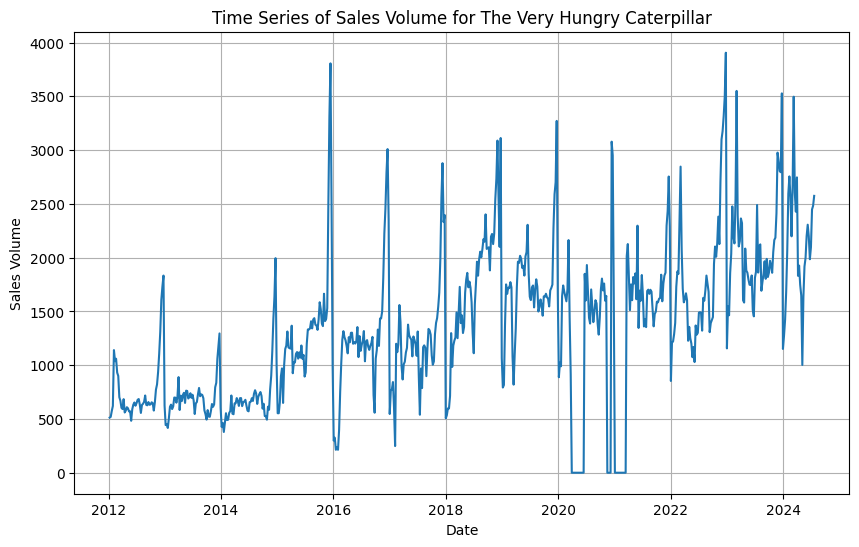

The Alchemist


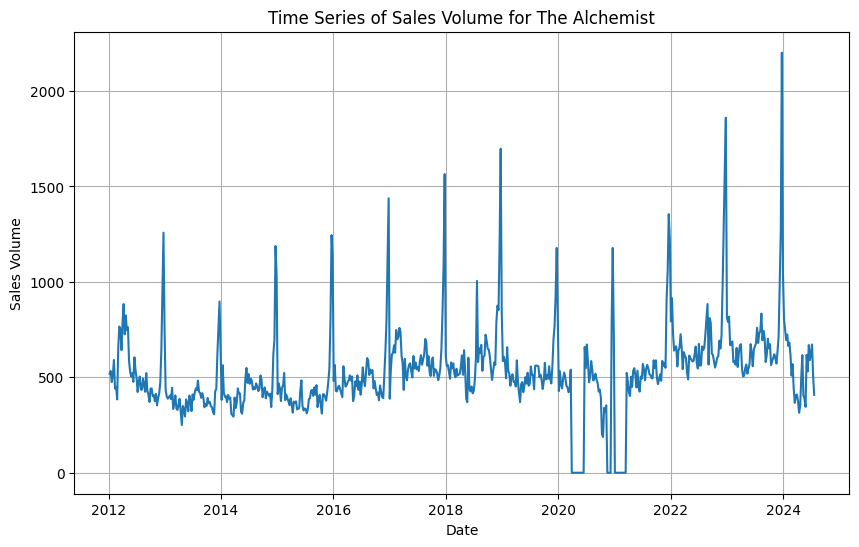

In [ ]:
# List of ISBNs to plot
isbns_to_plot = ['9780241003008', '9780722532935']

# Loop through the ISBNs and plot
for isbn in isbns_to_plot:
    # Filter the df_UK_weekly_post2012 by the ISBN
    book_data = df_UK_weekly_post2012[df_UK_weekly_post2012['ISBN'] == isbn]

    # Get the unique title(s) for the ISBN
    title = book_data['Title'].unique()[0]
    print(title)

    # Plot the Volume over Time
    plt.figure(figsize=(10, 6))
    plt.plot(book_data.index, book_data['Volume'], label=f'Sales Volume - {title}')
    plt.title(f'Time Series of Sales Volume for {title}')
    plt.xlabel('Date')
    plt.ylabel('Sales Volume')
    plt.grid(True)
    #plt.legend()
    plt.savefig(f'original_ts_{title}.svg')
    plt.show()

**The Very Hungry Caterpillar Visual Inspection**

* The timeseries obtained for 'The Very Hungry Caterpillar' sales volume is indicative of a trend where compared to the window 2012-2014, the sales volume is broadly speaking increasing but by differing amounts and at times following a saturation (for example during the 2016-2018) or dips (e.g. in the 2020-2022 period). These observations are all indicative of a non-linear trend.

* The appearance of large narrow peaks at the end of each year following some flat-topped broader peak is indicative of a seasonal component.

* Also, notable is the changing variance.

**The Alchemist Visual Inspection**

* In contrast to 'The Very Hungry Caterpillar', the base of the timeseries obtained for 'The Alchemist' sales volume presents with a more flat level. However, when the increasing amplitude of the peaks are taken into account there is a trend where the sales volume is increasing, albeit not linearly.

* Once again the presence of sharp, narrow peaks near the end of at the beginning of each year, following a much shallower less prominent peak form is indicative of seasonality. Note the seasonal pattern is disrupted duing the 2020-2021 perid due to the pandemic.

* Again the variance is non-constant.



In [ ]:
missing_weeks_per_title= len(df_UK_weekly_post2012[(df_UK_weekly_post2012['Author']==0) & (df_UK_weekly_post2012['Volume']==0)])*0.5
print('Missing weeks per title:', missing_weeks_per_title)

Missing weeks per title: 27.0


By including the weeks wherein there were no records due to the Covid-19 lockdowns in the UK, an evenly fixed interval sampling is achieved, meaning equally spaced time units -weekly intervals. While an evenly sampled grid is a requirement for FFT, it is also assumed by the classical approaches.


At the same time, the fixed sampling approach used results in imputation by zeros where the 27 weeks missing which constitutes roughly 4.3% of the training set are reintroduced with a zero sales volume.

This has two immediate consequences:

* Discontinuities are introduced to the sales volume represented by the 'Volume' feature which will negatively influence the latter analyses both by classical and ML techniques.

* A small-scale zero-inflation is imposed in the sense that the records with zero sales volume stem **not** from a lack of purchases but an inability to make purchases due to government imposed regulations during Covid shut downs.

The latter argument means usual interpolation techniques such as a smooth spline function, using the average or forward filling cannot be meaningfully applied due to the length of the period affected by the pandemic (27 weeks plus the recovery period). A K-Nearest Neighbors (KNN) approach may be considered due its ability to capture wider gaps but the approach is better suited to stationary data.

In the current scenario, any imputation method that relies on direct filling would run the risk of ignoring the persistent effects of the pandemic which could be acting as a unit root event.

Given the missing weeks constitues 4.3% of the training data, dropping these data points could be considered. However, doing so would again mean disregarding the after-math effects, i.e. the gradual increase in sales records after the easing of lock-downs, which still deviate from the norm but are non-zero. For the data hungry ML methods, dropping further datapoints is also non-ideal.

So at this stage, the zero-valued datapoints will be maintained to observe and understand the effects on the analysis techniques.

## 3.Classical techniques:


### 3.1 Perform decomposition on the data for both books. Determine what type of decomposition is suitable for each book, and comment on the components' characteristics.

In [ ]:
# Let's simplify the datasets
book_data_caterpillar=df_UK_weekly_post2012[df_UK_weekly_post2012['Title']=='The Very Hungry Caterpillar']
book_data_alchemist=df_UK_weekly_post2012[df_UK_weekly_post2012['Title']=='The Alchemist']


In [ ]:
# Drop columns other then those relating to sales volume
drop_columns=book_data_caterpillar.columns.difference(['Volume'])

In [ ]:
# The Very Hungry Caterpillar timeseries data
book_data_caterpillar=book_data_caterpillar.drop(drop_columns.tolist(), axis=1)

In [ ]:
# The Alchemist timeseries data
book_data_alchemist=book_data_alchemist.drop(drop_columns.tolist(), axis=1)

Note that upon imputing the previously non-recorded weeks with '0' sales volume, we cannot perform multiplicative seasonal decomposition as it will cause a 'division by zero' error.

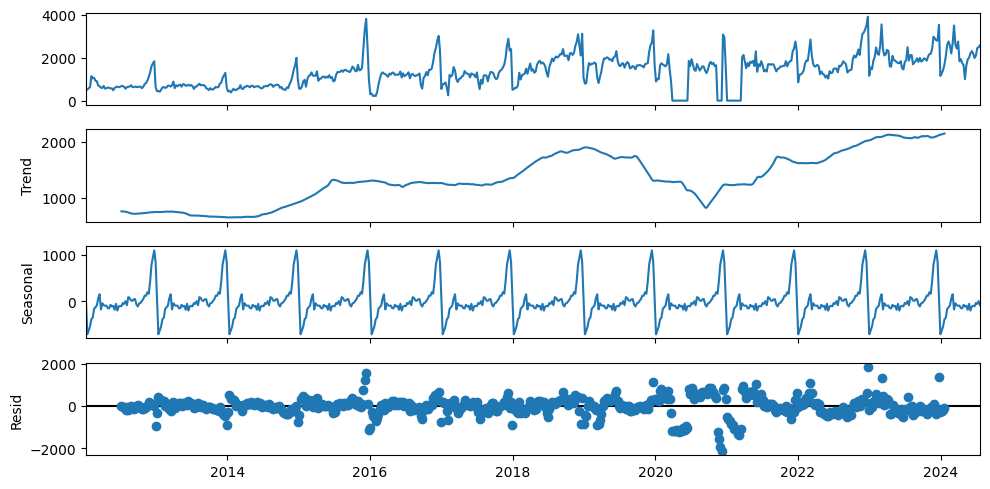

In [ ]:
# Decomposing 'The Very Hungry Caterpillar' timeseries
decomposition_caterpillar_additive = sm.tsa.seasonal_decompose(book_data_caterpillar, model='additive')
fig = decomposition_caterpillar_additive.plot()
plt.savefig('decomp_caterpillar.svg')
plt.show()

**The Very Hungry Caterpillar Timeseries Discussion**

* The raw timeseries data presents with 3 gaps in the 2020-2022 window which stem from the zero-sales data spanning over a total of 27 weeks that are interrupted by relaxation of the lockdown rules.

* The trend component is consistent with the raw timeseries where three windows of increase in sales volume can be discerned based on the increase in peak amplitudes.

* The trend also captures the dips created by the zero-sales data which in the 2020-2022 window are represented as part of the flat lines following the second trend peak and preceding the third trend peak.

* The seasonality component indicates a cycle of 12 months where the resulting pattern is consistent with the pattern of (nearly flat initial level + sharp peak + sharp drop off) seen in the raw data except (upon removing the trend) it captures the initial rise resulting in a (steep rise + level off + sharp peak + sharp drop off) pattern.

* The residuals oscillate about zero and become increasingly negative around the Covid period (the 27 weeks in the 2020-2022 window). The variance appears non-constant which indicates non-stationarity. Thus, this should be tested using a histogram plot to infer the nature of distribution.

In [ ]:
# There are some NaN values in the resulting residuals
# This may be due to the scaling
decomposition_caterpillar_additive.resid.isna().sum()

np.int64(52)

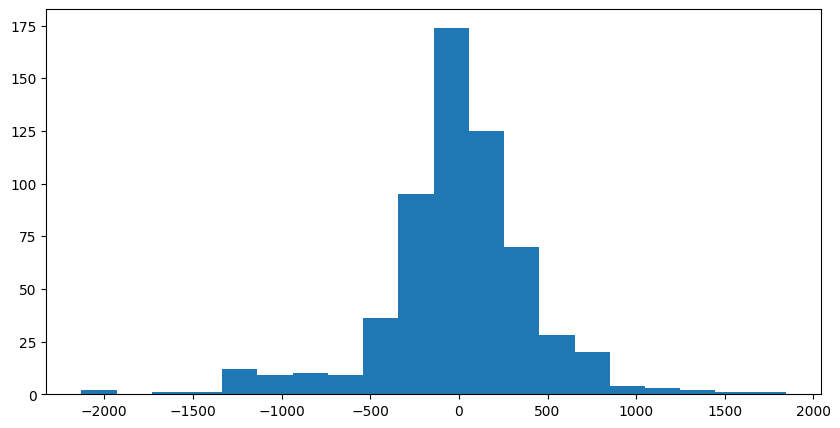

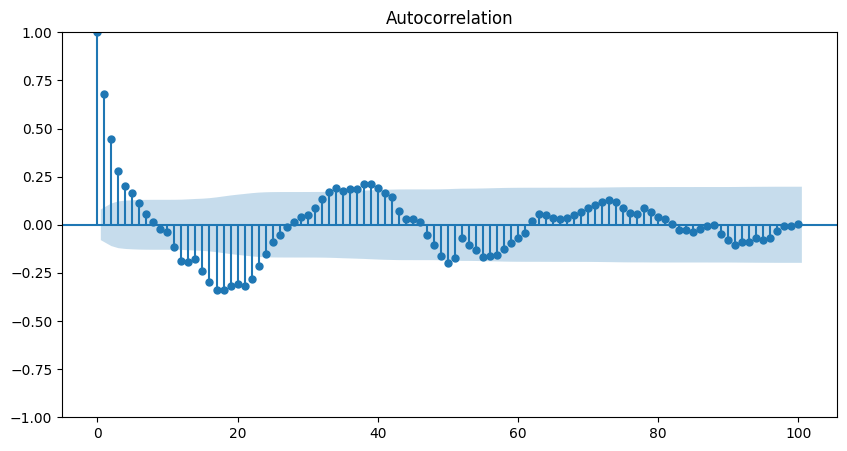

In [ ]:
# Plot the histogram of the residuals.
plt.hist(decomposition_caterpillar_additive.resid.dropna(), bins=20)
plt.savefig('residuals_caterpilar.svg')
# Plot the ACF of the residuals.
smgraphics.tsa.plot_acf(decomposition_caterpillar_additive.resid.dropna(),lags=100);
plt.savefig('residuals_acf_caterpillar.svg')


**The Very Hungry Caterpillar Residuals Discussion:**

* If we ignore the heavy tails the histogram plot shows a nearly normal distribution with a mean around 0 which could be indicative of white noise. Note the standard deviaton is ~500 which is large.

* While the residuals following a nearly normal distribution implies an element of randomness, the autocorrelation plot conveys a different story where several lags remain outside of the insignificance region. The overall ACF pattern can be described as a non-harmonic damped oscillator which could be indicative of an initially persistent periodic trend that is decaying over time.

* Combining the two observations, it can be argued that the residuals are non-stationary and that there is some remaining structure that needs to be captured.

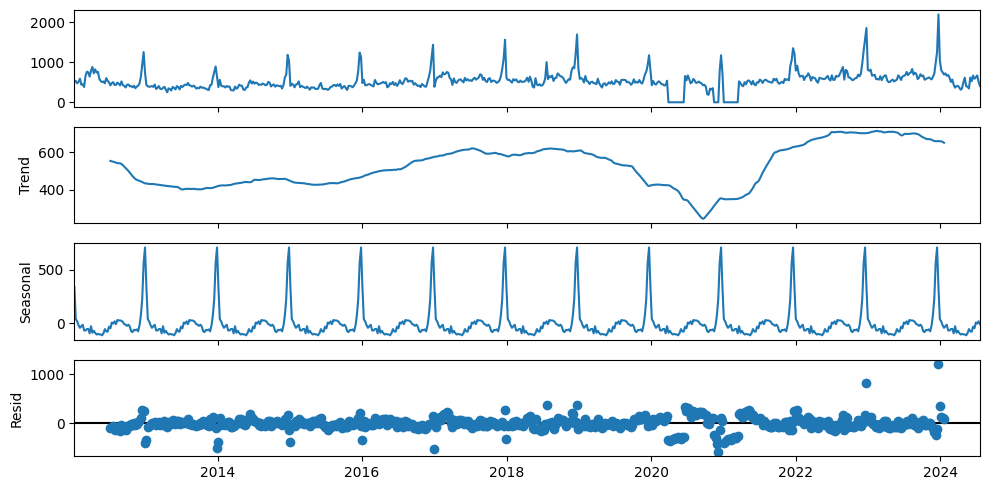

In [ ]:
# Decomposing 'The Alchemist' timeseries
decomposition_alchemist_additive = sm.tsa.seasonal_decompose(book_data_alchemist, model='additive')
fig = decomposition_alchemist_additive.plot()
plt.savefig('decomp_alchemist.svg')
plt.show()

**The Alchemist Timeseries Discussion**

* Once again, the trend component is consistent with the raw timeseries where this time, there are two major peaks preceded by a smaller peak located around 2015. The peaks represent periods of increase in the sales volume for 'The Alchemist'.

* The trends is able to capture the 'zero-sales' periods where it can be seen that the first and second (the shortest) 'zero-sales' periods (in the 2020-2022 window) are considered as continuations of the natural decline in sales that precedes them. The third 'no-sales' period is captured as a flatter level leading up to the next rise, which is again consistent with the raw data.

* The seasonality component is following the double peak form appearing periodically in the original timeseries where a shallower peak is followed up by a much sharper and narrower peak. The cycle seems to repeat anually, i.e. every 12 months.

* The residuals oscillate about zero as before with changing variance (although this is difficult to judge by eye). The residuals resulting within the 2020-2022 window are once again negative but are not much larger in magnitude compared to the other negative residuals as was observed in 'The Very Hungry Caterpillar' case. Once again a histogram plot of the residuals would prove useful to assess if there is a pattern remaining.

In [ ]:
# Again we have some NaN values
decomposition_alchemist_additive.resid.isna().sum()

np.int64(52)

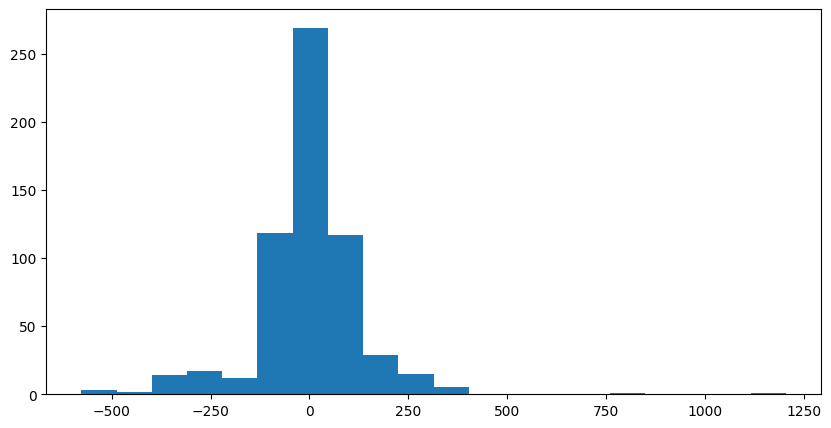

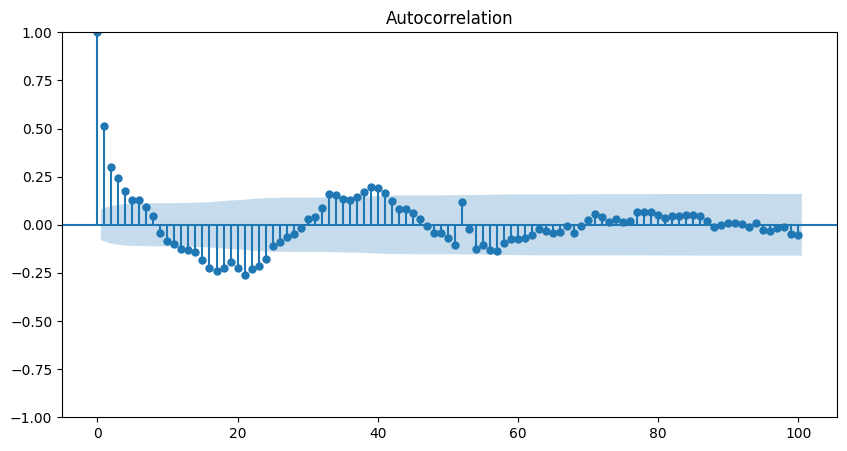

In [ ]:
# Plot the histogram of the residuals.
plt.hist(decomposition_alchemist_additive.resid.dropna(), bins=20)
plt.savefig('residuals_alchemist.svg')
# Plot the ACF of the residuals.
smgraphics.tsa.plot_acf(decomposition_alchemist_additive.resid.dropna(),lags=100);
plt.savefig('residuals_acf_alchemist.svg')

**The Alchemist Residuals Discussion:**

* If the right-skewness is ignored which is created by the very low counts at the extreme values ( > 500), the distribution can be approximated as normal, with a mean around 0 and a standard deviation of roughly 125.

* The standard deviation being zero introduces the possibility of white noise which is why we also need to check for the lag autocorrelation.

* The autocorrelation plot does show several lags that remain outside the insignificance region. While the lag pattern is more complicated, it can be seen that the oscillations around zero are decaying with time (as inferred by the increasing lag value).

* The two observations combined suggets a simple decomposition does not account for the stochastic component that remains after determining trend and seasonality.

* Due to the presence of autocorrelation between the lags, the residuals cannot be considered stationary but have an element of randomness (i.e. structure plus noise).

**Let's see if assuming multiplicative seasonality improves the picture. To be able to apply multiplicative seasonality, we can try adding a small constant to all datapoints temporarily (i.e. to be subtracted post-forecasting):**

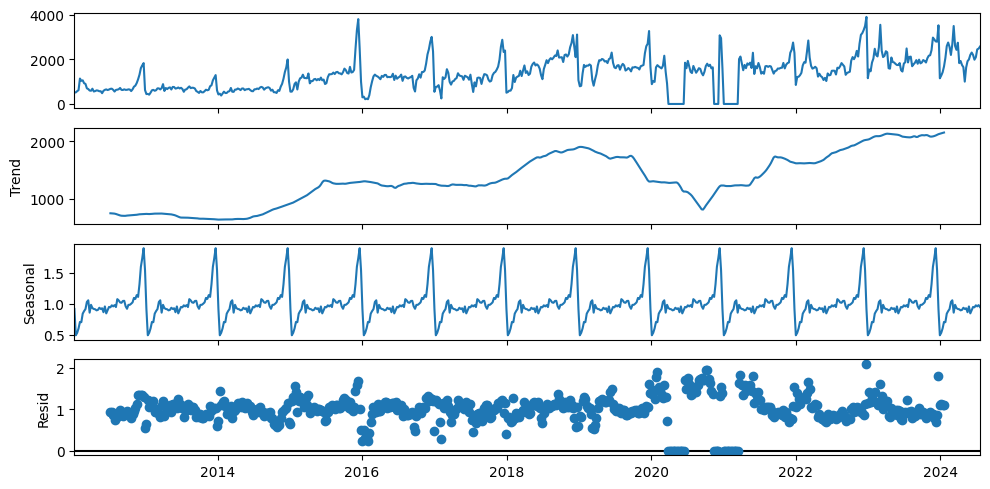

In [ ]:
# Decomposing 'The Very Hungry Caterpillar' timeseries multiplicatively

# Let the small constant be called, c and initialise to 1
c=1
# Perform decomposition
decomposition_caterpillar_multiplicative = sm.tsa.seasonal_decompose(book_data_caterpillar+c, model='multiplicative')
fig = decomposition_caterpillar_multiplicative.plot()
plt.show()

For both books, the multiplicative decomposition results in a very similar trend and a nearly identical seasonal component to that of the additive decomposition case. However, the residuals are scaled differently and now osscilate about 1 which likely is the minumum of the original timeseries given the constant, c.

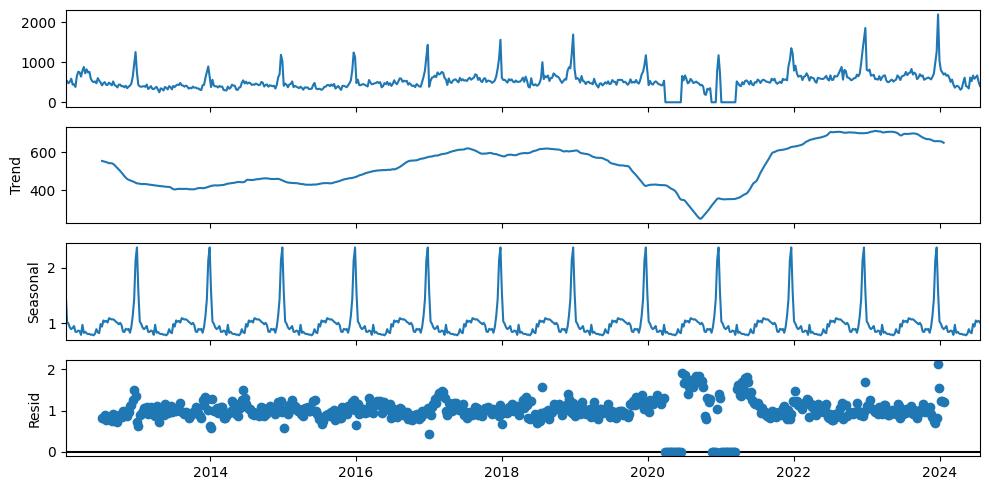

In [ ]:
# Decomposing 'The Alchemist' timeseries multiplicatively

# Let the small constant be called, c and initialise to 1
c=1
# Perform decomposition
decomposition_alchemist_multiplicative = sm.tsa.seasonal_decompose(book_data_alchemist+c, model='multiplicative')
fig = decomposition_alchemist_multiplicative.plot()
plt.show()

In [ ]:
# Checking for NaN values in the residuals
print(decomposition_caterpillar_multiplicative.resid.isna().sum())
print(decomposition_alchemist_multiplicative.resid.isna().sum())

52
52


Checking distribution of the residuals for 'The Very Hungry Caterpillar' data:

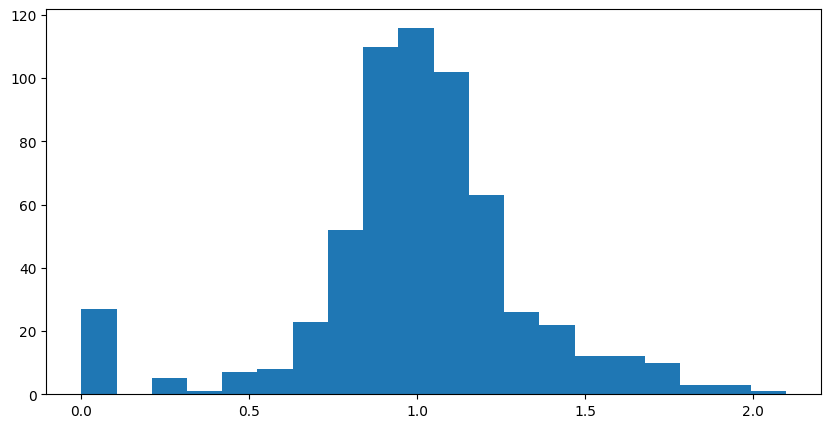

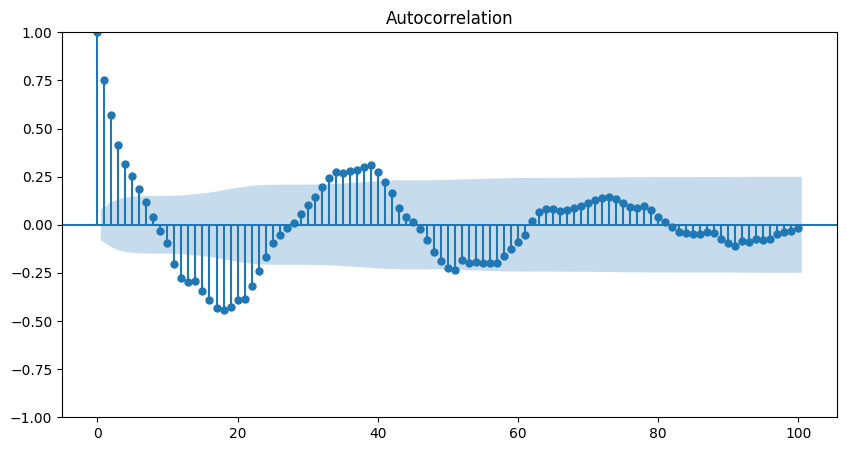

In [ ]:
# Plot the histogram of the residuals.
plt.hist(decomposition_caterpillar_multiplicative.resid.dropna(), bins=20)
# Plot the ACF of the residuals.
smgraphics.tsa.plot_acf(decomposition_caterpillar_multiplicative.resid.dropna(),lags=100);

Checking distribution of the residuals for 'The Alchemist' data:

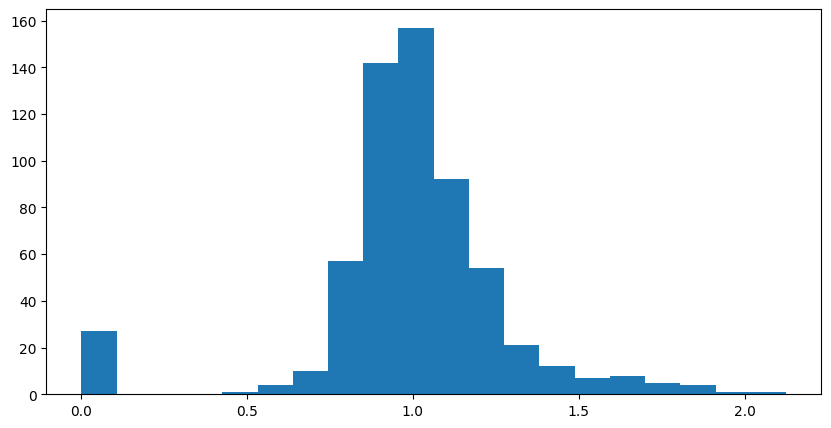

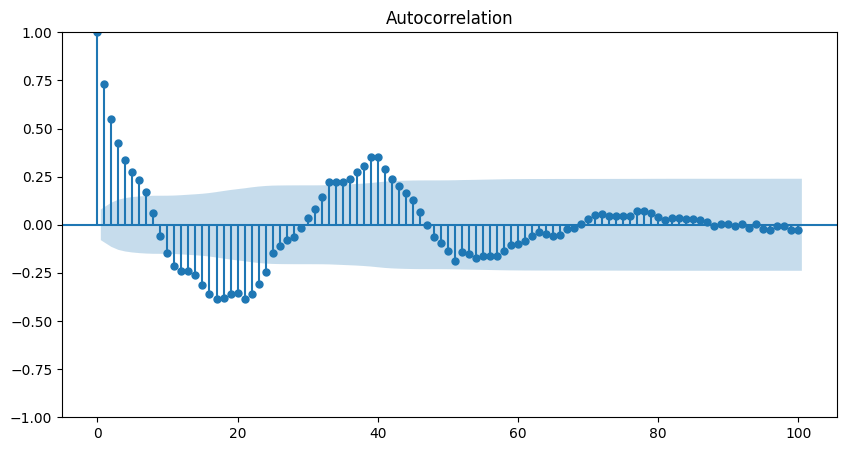

In [ ]:
# Plot the histogram of the residuals.
plt.hist(decomposition_alchemist_multiplicative.resid.dropna(), bins=20)
# Plot the ACF of the residuals.
smgraphics.tsa.plot_acf(decomposition_alchemist_multiplicative.resid.dropna(),lags=100);

Therefore, in both cases, while adding a constant alters the resulting range of the residuals, it does not alter their nature:

* Histogram plots can be approximated as normal distribution (if ignoring the first bins near zero) which suggests an element of randomness.
* The ACF plots indicates structure as implied by the several lags remaining outside the insignificance region.

Note also that the time dependent pattern in the ACF plot becomes more prominent in the case of 'The Alchemist'.

In conclusion, it would be unneccessary to overcomplicate the picture by introducing a constant to decompose under the assumption of multiplicative seasonality.

### 3.2 Perform ACF and PACF on both books. Comment on the results and what they indicate.

<Figure size 2000x1200 with 0 Axes>

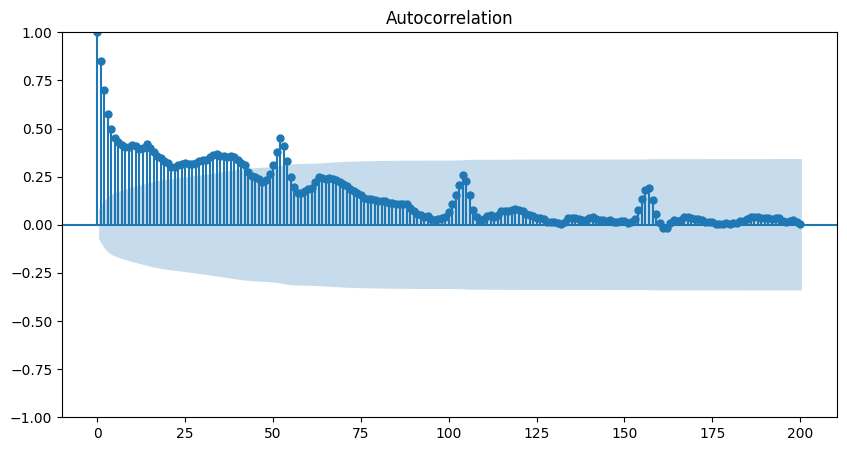

In [ ]:
# 'The Very Hungry Caterpillar' ACF plot
plt.figure(figsize=(20, 12))
smgraphics.tsa.plot_acf(book_data_caterpillar,lags=200)
# plt.savefig('ACF_caterpillar.svg')
plt.show()

As well as indicating significant correlation between the timeseries and its lag, a considerate amount of which remains outside the insignificance region, the ACF plots shows a clear pattern which cycles over 52 lags. It can also be inferred that the autocorrelation is decaying with time.

<Figure size 2000x1200 with 0 Axes>

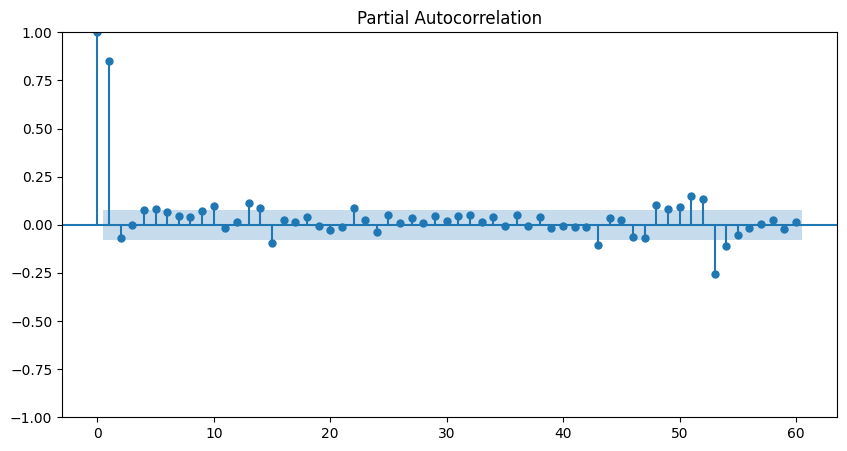

In [ ]:
# 'The Very Hungry Caterpillar' PACF plot
plt.figure(figsize=(20, 12))
smgraphics.tsa.plot_pacf(book_data_caterpillar,lags=60, alpha=0.05)
# plt.savefig('PACF_caterpillar.svg')
plt.show()

Since PACF measures the correlation between a time series and its lagged values after removing the effects of the intermediate lags, the structures arising from the trend and seasonal components are heavily dampened.

However, we can still see a significant correlation between the original timeseries and its 52nd lag which suggests the periodicity is annual: in other words the seasonality is 52 weeks for the weekly data.

While there are other lagged values that are outside of the insignificance region, their magnitude is not as large as that of the 52nd lag ( and those near it).

<Figure size 2000x1200 with 0 Axes>

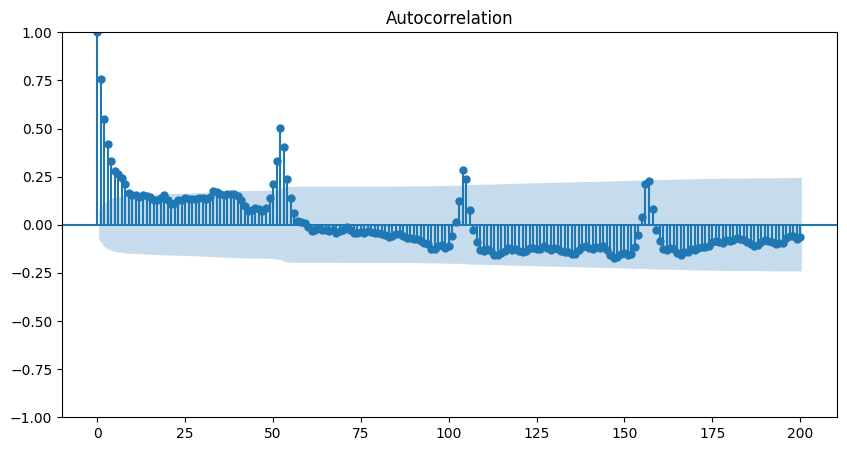

In [ ]:
# 'The Alchemist' ACF plot
plt.figure(figsize=(20, 12))
smgraphics.tsa.plot_acf(book_data_alchemist,lags=200)
# plt.savefig('ACF_alchemist.svg')
plt.show()

Similar to the 'The Very Hungry Caterpillar' timeseries, 'The Alchemist' timeseries shows significant autocorrelation with its lags and displays a strong pattern which cylces over 52 weeks for the weekly dataset.

While strong autocorrelation would be expected for the earlier lags (< 12), the 52-week pattern is evident from the prominence of the latter lags highlighting the seasonal component.

Also not that there are several lags that remain within the insignificance region as the amplitude of the lags decay gradually over time indicating a trend component.

<Figure size 2000x1200 with 0 Axes>

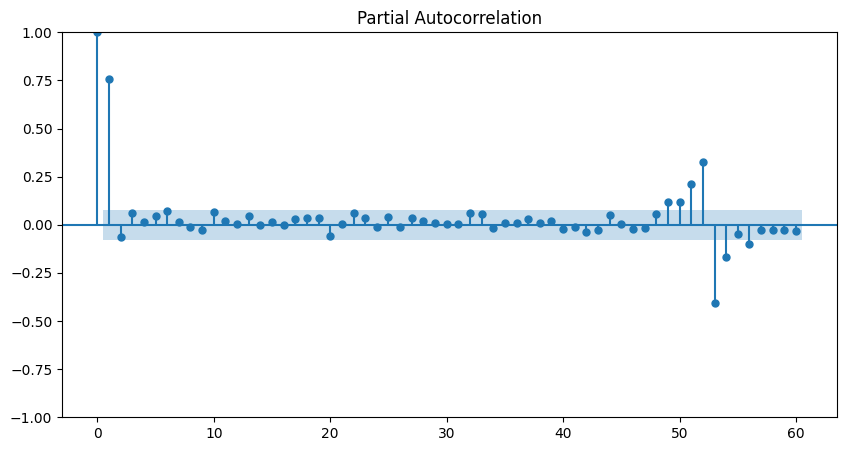

In [ ]:
# 'The Alchemist' PACF plot
plt.figure(figsize=(20, 12))
smgraphics.tsa.plot_pacf(book_data_alchemist,lags=60, alpha=0.05)
# plt.savefig('PACF_alchemist.svg')
plt.show()

Since PACF removes the effect of intermediate lags as discussed earlier, it can be seen once again that a strong autocorrelation is evident for the 52nd lag (and a few other lags near it) indicating the seasonal periodicity. As before, there are other lags, albeit smaller in magnitude, that are found outside of the insignificance region.

### 3.3 Check for stationarity of the data for both books.

The prior visual inspection of the timeseries obtained for the sales volume of both books indicates the following:

* Non-constant mean, i.e. the presence of a trend component.
* A seasonal component.
* Non-constant variance.

Based on these observations which are also supported by the ACF and the PCF plots obtained earlier, both timeseries would be classified as non-stationary.

However, it is important to isolate the non-random structure or the deterministic components such as trend and seasonality and then, assess whether the residual stochastic component itself is stationary.

The analysis of the residuals obtained following the seasonal decompositions performed in section $3.1$ indicate non-stationarity:

1. A quick visual inspection suggests a non-constant variance.
2. The resulting distributions can be approximated as normal and thus, indicate an element of randomness.
3. The autorcorrelation analysis suggests structure remains.

If the residuals were to be stationary, we would expect them to behave like white noise and lack structure.

**The Augmented Dickey-Fuller (ADF) Test**

In [ ]:
# Difference the timeseries first
book_data_caterpillar_diff=book_data_caterpillar.diff()[1:]
book_data_alchemist_diff=book_data_alchemist.diff()[1:]

In [ ]:
# Testing for stationarity - 'The Very Hungry Caterpillar'
adf_result = adf(book_data_caterpillar)
print('p-value of original data:', adf_result[1])

adf_result = adf(book_data_caterpillar_diff)
print('p-value of differenced data:', adf_result[1])

p-value of original data: 0.029616021527175906
p-value of differenced data: 1.242762309266303e-16


In [ ]:
# Testing for stationarity - 'The Alchemist'
adf_result = adf(book_data_alchemist)
print('p-value of original data:', adf_result[1])

adf_result = adf(book_data_alchemist_diff)
print('p-value of differenced data:', adf_result[1])

p-value of original data: 4.139950997174928e-13
p-value of differenced data: 6.058806365373857e-20


The null-hypothesis ($H_0$) for the ADF is that the time series has a unit root, and is therefore, likely non-stationary. Both sets of ADF tests ran on the two timeseries return a p-value below 0.05 which means that we can reject the null hypothesis. In other words, neither 'The Very Hungry Caterpillar' nor 'The Alchemist' timeseries has a stochastic unit root. However, based on prior observations, we cannot claim that the timeseries is stationary. Also note that the p value for the original timeseries for 'The Very Hungry Caterpillar' is relatively close to 0.05.


In [ ]:
# KPSS test - 'The Very Hungry Caterpillar'
stat, p_value_orig_cater, *_ = kpss(book_data_caterpillar.squeeze(), regression='c')
stat, p_value_diff_cater, *_ = kpss(book_data_caterpillar_diff.squeeze(), regression='c')
print("KPSS test p-value of original data:", p_value_orig_cater)
print("KPSS test p-value of differenced data:", p_value_diff_cater)

KPSS test p-value of original data: 0.01
KPSS test p-value of differenced data: 0.1


In [ ]:
# KPSS test - 'The Alchemist'
stat, p_value_orig_alche, *_ = kpss(book_data_alchemist.squeeze(), regression='c')
stat, p_value_diff_alche, *_ = kpss(book_data_alchemist_diff.squeeze(), regression='c')
print("KPSS test p-value of original data:", p_value_orig_alche)
print("KPSS test p-value of differenced data:", p_value_diff_alche)

KPSS test p-value of original data: 0.021978961558447516
KPSS test p-value of differenced data: 0.1


The null-hypothesis ($H_0$) for the KPSS is that the time series is stationary. Therefore, a p-value of below 0.05 (albeit on the same order of magnitude) obtained for both timeseries means the null hypothesis can be rejected. The timeseries for both books is non-stationary. When it comes to the differenced datasets, the p-value is above 0.05 and therefore, the null hypothesis holds. The KPSS is more inline with the observations made earlier -- except the residual ACFs imply non-stationarity persists.


### 3.4 Perform Auto ARIMA on both books. The forecast horizon is the final 32 weeks of data. All prior data (from 2012-01-01 onwards) can be used as the training data. Set reasonable bounds for Auto ARIMA's various parameters so that Auto ARIMA can identify the most suitable model.

In [ ]:
# Perform a train-test split for a final horizon of 32 weeks

# 'The Very Hungry Caterpillar'
ts_caterpillar_train = book_data_caterpillar[:-32]
ts_caterpillar_test = book_data_caterpillar[-32:]

# 'The Alchemist'
ts_alchemist_train = book_data_alchemist[:-32]
ts_alchemist_test = book_data_alchemist[-32:]


In [ ]:
print(len(ts_caterpillar_train),len(ts_caterpillar_test))
print(len(ts_alchemist_train),len(ts_alchemist_test))

623 32
623 32


Recall that:

* p: auto-regressive order.
* d: differencing order.
* q: moving average order.

* P: seasonal auto-regressive order.
* D: seasonal differencing order.
* Q: seasonal moving average order.


In [ ]:
print("GPU Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Device Name:", torch.cuda.get_device_name(0))

GPU Available: True
Device Name: NVIDIA A100-SXM4-80GB


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
set_random_seed(42)

In [ ]:
# Define the model for 'The Very Hungry Caterpillar'
arima_caterpillar= auto_arima(y=ts_caterpillar_train, X=None,
                              start_p=0, d=None, start_q=0, max_p=2, max_d=1, max_q=2,
                              start_P=0, D=None, start_Q=0, max_P=2, max_D=1, max_Q=2,
                              max_order=10, m=52, seasonal=True, stationary=False,
                              information_criterion='aic', alpha=0.05,
                              test='kpss', seasonal_test='ocsb',
                              stepwise=True, n_jobs=1, start_params=None, trend=None,
                              method='lbfgs', maxiter=50, offset_test_args=None, seasonal_test_args=None,
                              suppress_warnings=True, error_action='trace',
                              trace=False, random=False, random_state=None, n_fits=10,
                              return_valid_fits=False, out_of_sample_size=0, scoring='mse',
                              scoring_args=None, with_intercept='auto', sarimax_kwargs=None)

# Print model results.
arima_caterpillar.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                        SARIMAX Results                                        
===============================================================================================
Dep. Variable:                                       y   No. Observations:                  623
Model:             SARIMAX(2, 1, 1)x(1, 0, [1, 2], 52)   Log Likelihood               -4482.094
Date:                                 Wed, 21 Oct 2026   AIC                           8978.188
Time:                                         18:42:48   BIC                           9009.219
Sample:                                     01-08-2012   HQIC                          8990.248
                                          - 12-10-2023                                         
Covariance Type:                                   opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.8131      0.034     23.602      0.000       0.746       0.881
ar.L2         -0.0665      0.032     -2.051      0.040      -0.130      -0.003
ma.L1         -0.9646      0.013    -74.658      0.000      -0.990      -0.939
ar.S.L52       0.6274      0.086      7.311      0.000       0.459       0.796
ma.S.L52      -0.3466      0.089     -3.883      0.000      -0.521      -0.172
ma.S.L104      0.1030      0.051      2.016      0.044       0.003       0.203
sigma2      1.041e+05   3032.202     34.321      0.000    9.81e+04     1.1e+05
===================================================================================
Ljung-Box (L1) (Q):                   0.01   Jarque-Bera (JB):              5951.42
Prob(Q):                              0.94   Prob(JB):                         0.00
Heteroskedasticity (H):               5.46   Skew:                             0.91
Prob(H) (two-sided):                  0.00   Kurtosis:                        18.05
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [ ]:
# Check for Convergence
if arima_caterpillar.arima_res_.mle_retvals['converged']:
    print("Model converged successfully.")
else:
    print("Model did not converge.")

Model converged successfully.


**Interpreting the Residual Diagnostics**

* Prob(Q) tests the null hypothesis which states that the residuals are NOT correlated with their own past values (**no autocorrelation**). If > 0.05  we fail to reject the null hypothesis meaning there is no significant remaining autocorrelation.

* Prob(JB): tests for normal distribution as argued by the null hypothesis. If > 0.05 we fail to reject the null hypothesis.

* A perfectly normal distribution has a *skew* of 0 and a *kurtosis* of 3.

* The heteroskedasticity test checks if the variance (volatility) of your residuals changes over time. If Prob(H) is greater than 0.05, we fail to reject the null hypothesis which argues for constant variance.

In [ ]:
# Define the model for 'The Alchemist'
arima_alchemist= auto_arima(y=ts_alchemist_train, X=None,
                              start_p=0, d=None, start_q=0, max_p=2, max_d=1, max_q=2,
                              start_P=0, D=None, start_Q=0, max_P=2, max_D=1, max_Q=2,
                              max_order=10, m=52, seasonal=True, stationary=False,
                              information_criterion='aic', alpha=0.05,
                              test='kpss', seasonal_test='ocsb',
                              stepwise=True, n_jobs=1, start_params=None, trend=None,
                              method='lbfgs', maxiter=50, offset_test_args=None, seasonal_test_args=None,
                              suppress_warnings=True, error_action='trace',
                              trace=False, random=False, random_state=None, n_fits=10,
                              return_valid_fits=False, out_of_sample_size=0, scoring='mse',
                              scoring_args=None, with_intercept='auto', sarimax_kwargs=None)

# Print model results.
arima_alchemist.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                      SARIMAX Results                                      
===========================================================================================
Dep. Variable:                                   y   No. Observations:                  623
Model:             SARIMAX(1, 1, 2)x(2, 0, [], 52)   Log Likelihood               -3804.646
Date:                             Wed, 21 Oct 2026   AIC                           7623.292
Time:                                     18:52:42   BIC                           7654.322
Sample:                                 01-08-2012   HQIC                          7635.352
                                      - 12-10-2023                                         
Covariance Type:                               opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept     -0.0154      0.163     -0.095      0.925      -0.335       0.304
ar.L1          0.7663      0.052     14.793      0.000       0.665       0.868
ma.L1         -1.0745      0.058    -18.422      0.000      -1.189      -0.960
ma.L2          0.1201      0.045      2.677      0.007       0.032       0.208
ar.S.L52       0.4296      0.026     16.400      0.000       0.378       0.481
ar.S.L104      0.2961      0.026     11.498      0.000       0.246       0.347
sigma2      1.139e+04    360.067     31.620      0.000    1.07e+04    1.21e+04
===================================================================================
Ljung-Box (L1) (Q):                   0.04   Jarque-Bera (JB):              1329.85
Prob(Q):                              0.84   Prob(JB):                         0.00
Heteroskedasticity (H):               2.95   Skew:                             0.54
Prob(H) (two-sided):                  0.00   Kurtosis:                        10.08
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [ ]:
# Check for Convergence
if arima_alchemist.arima_res_.mle_retvals['converged']:
    print("Model converged successfully.")
else:
    print("Model did not converge.")

Model converged successfully.


### 3.5$a$ Comment on the best model provided by Auto ARIMA for both books.


**'The Very Hungry Caterpillar' Best Model**

Model:	SARIMAX(2, 1, 1)x(1, 0, [1, 2], 52)

> Non-Seasonal Components
* AR(2): Uses two autoregressive lags meaning the current value is predicted based on the previous two weeks.
* diff(1): Differences once to handle trend.
* MA(1): Uses one forecast error to capture residual noise patterns which helps with short-term shock smoothing.
* No intercept.

> Seasonal Components
* AR(1): Uses one seasonal autoregressive lag meaning the current week's value is regressed on the value from exactly 52 weeks ago.
* diff(0): No seasonal differencing is applied meaning the seasonal pattern is assumed to be stable. Normally, it is used to remove seasonal trends.
* MA([1,2]): Includes the forecast errors from exactly 52 weeks ago (lag 1, $L^m$) and exactly 104 weeks ago (lag 2, $L^{2m}$).
* m=52:  Owing to weekly time series - 52 periods per year.

> X: signifies the model can include external variables.


**'The Alchemist' Best Model**

Model:	SARIMAX(1, 1, 2)x(2, 0, [], 52)

> Non-Seasonal Components
* AR(1): Uses a single autoregressive lag meaning the current value is regressed based on the previous week.
* diff(1): Differences once, to handle trend.
* MA(2): Uses two forecast errors (shocks) from 1 and 2 weeks ago to capture residual noise patterns.
* An intercept is also added.

> Seasonal Components
* AR(2): Uses two seasonal autoregressive lags meaning the current week's value is regressed on the value from 52 weeks and 104 weeks ago.

* diff(0): Once again no seasonal differencing is applied and the seasonal pattern is assumed to be stable.
* MA([]=0): No historical seasonal forecast error is used to adjust the current prediction.
* m=52:  Owing to weekly time series - 52 periods per year.

> X: signifies the model can include external variables.

### 3.5$b$ Set-up and fit the best models returned by Auto ARIMA - to avoid peforming a search again.

In [ ]:
# Instantiate the model for 'The Very Hungry Caterpilar'
arima_caterpillar = SARIMAX(endog=ts_caterpillar_train,
                            order=(2, 1, 1),
                            seasonal_order=(1, 0,[1,2],52),
                            trend='n',
                            enforce_stationarity=False,
                            enforce_invertibility = True)

# Instantiate the model for 'The Alchemist'
arima_alchemist = SARIMAX(endog=ts_alchemist_train,
                          order=(1, 1, 2),
                          seasonal_order=(2, 0,[],52),
                          trend='c',
                          enforce_stationarity=False,
                          enforce_invertibility = True)

In [ ]:
# Fit the models
# List to store result and AIC values
list_results=[]

models=[arima_caterpillar,arima_alchemist]
for i,model in enumerate(models):
  # Fit the model
  results = model.fit(maxiter=500, disp=False)

  # Store the results in a list
  list_results.append(results)
  titles=['The Very Hungry Caterpillar','The Alchemist']

  # Print the current combination and its AIC
  print(titles[i],'AIC:',results.aic)

The Very Hungry Caterpillar AIC: 7526.183260326064
The Alchemist AIC: 6354.635501872444


Note that re-training the models alters the fitted coefficients after 500 iterations.

In [ ]:
counter=0
titles=['The Very Hungry Caterpillar','The Alchemist']
for title,results in zip(titles,list_results):
  # Print model name and combination
  print('\033[1m',title, '\n', '-'*90,'\n')
  print(f"Model {counter+1} converged? {results.mle_retvals['converged']}")
  print('\033[0m',results.summary(), '\n')
  counter+=1

 The Very Hungry Caterpillar 
 ------------------------------------------------------------------------------------------ 

Model 1 converged? True
                                         SARIMAX Results                                        
Dep. Variable:                                  Volume   No. Observations:                  623
Model:             SARIMAX(2, 1, 1)x(1, 0, [1, 2], 52)   Log Likelihood               -3756.092
Date:                                 Sat, 24 Oct 2026   AIC                           7526.183
Time:                                         10:10:32   BIC                           7555.906
Sample:                                     01-08-2012   HQIC                          7537.831
                                          - 12-10-2023                                         
Covariance Type:                                   opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
----

**'The Very Hungry Caterpillar' Residual Diagnostics**

* Prob(Q) > 0.05, fail to reject the null hypothesis. There is no significant autocorrelation remaining.
* Prob(JB) < 0.05, rejects the null hypothesis that the distribution is normal.
* A skew of 0.92 and a kurtosis of 15.73 means the distribution is slightly right skewed and have a significantly heavier tail than would be expected.
* Prob(H) < 0.05, can reject the null hypothesis. The variance is unstable.
* Out of the 3 criterion (no autocorrelation, normal distribution, constant variance) satisfies 1.

**'The Alchemist' Residual Diagnostics**

* Prob(Q) > 0.05, fail to reject the null hypothesis. There is no significant autocorrelation remaining.
* Prob(JB) < 0.05, rejects the null hypothesis that the distribution is normal.
* A skew of 0.75 and a kurtosis of 10.27 means the distribution is very slightly right skewed and have a much heavier tail than would be expected.
* Prob(H) < 0.05, can reject the null hypothesis. The variance is unstable.
* Out of the 3 criterion (no autocorrelation, normal distribution, constant variance) satisfies 1.

### 3.6 Find the residuals of the 'best' model for both books. Comment on the residuals.

For 'The Very Hungry Caterpillar':

In [ ]:
# Obtain ARIMA predictions and residuals on the training data
# The Very Hungry Caterpillar
arima_fitted_caterpillar=list_results[0].fittedvalues
arima_resid_caterpillar=list_results[0].resid

# The Alchemist
arima_fitted_alchemist=list_results[1].fittedvalues
arima_resid_alchemist=list_results[1].resid


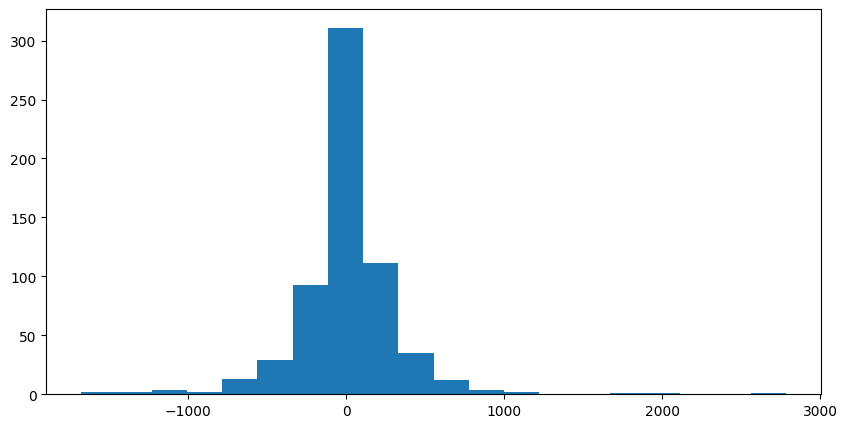

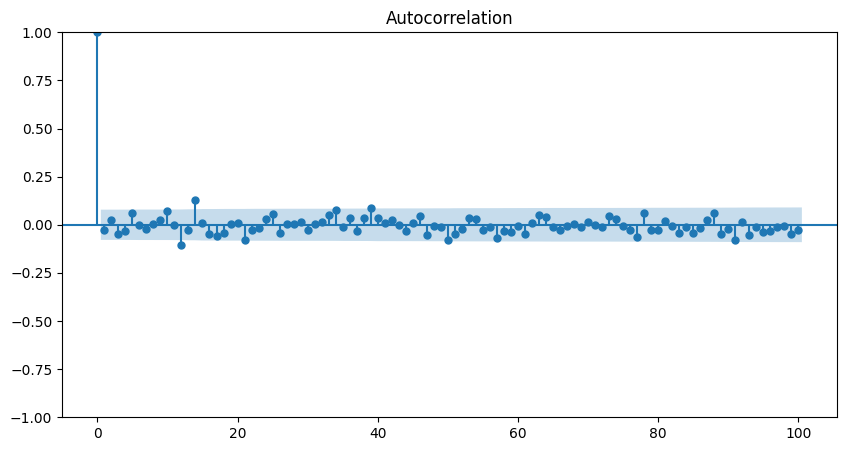

In [ ]:
# Plot the histogram of the residuals.
plt.hist(arima_resid_caterpillar, bins=20)
# plt.savefig('residuals_caterpillar.svg')
# Plot the ACF of the residuals.
smgraphics.tsa.plot_acf(arima_resid_caterpillar,lags=100);
# plt.savefig('residuals_acf_caterpillar.svg')

1-The very heavy tails make the residual distribution deviate from normal. However, if one were to focus solely on the central portion the distribution which has a mean of 0 the residuals could be assumed to follow a normal distribution.

2-The ACF plot shows some autocorrelation remains for two of the lagged values which slightly stick out from the insignificance region. However, they could also be considered borderline.

Combining the two observations, one can conclude the residuals approach non-stationarity but do not achieve it: they possess elements of randomness similar to white noise and are nearly devoid of autocorrelation.


For 'The Alchemist':

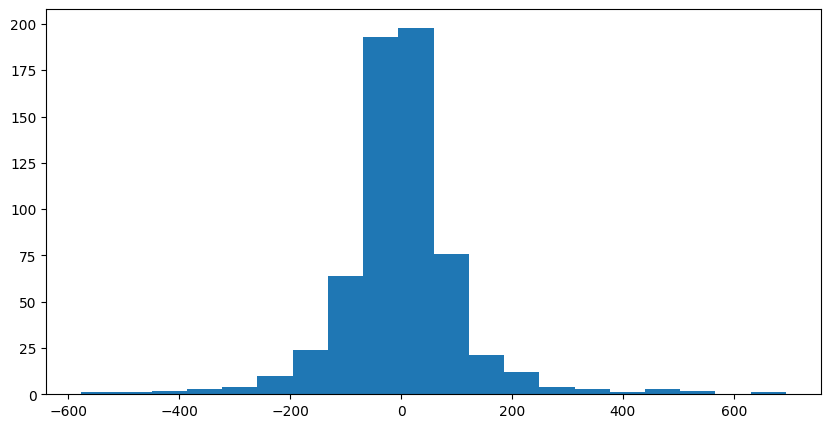

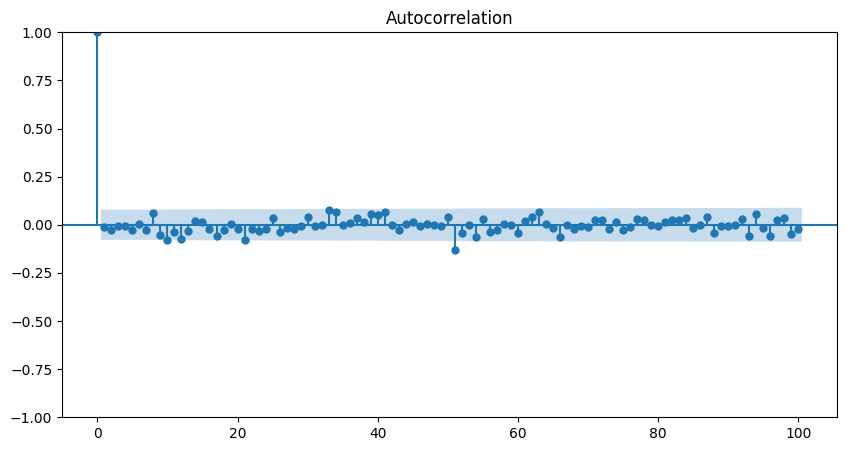

In [ ]:
# Plot the histogram of the residuals.
plt.hist(arima_resid_alchemist, bins=20)
# plt.savefig('residuals_alchemist.svg')
# Plot the ACF of the residuals.
smgraphics.tsa.plot_acf(arima_resid_alchemist,lags=100);
# plt.savefig('residuals_acf_alchemist.svg')

1-The residuals come very close to falling under a normal distribution, but have slightly heavier tails on either side of the central portion. The mean is zero as would be expected from white noise.

2-The ACF plot shows no autocorrelation remains with the majority of the lagged values falling within the insignificance region and a minority intersecting the borders.

Combining the two observations, one can conclude the residuals come very close to non-stationarity (especially in comparison to 'The Very Hungry Caterpillar' case) but do not achieve it: they possess strong elements of randomness similar to white noise and are devoid of autocorrelation.


### 3.7 Use the best model to predict the final 32 weeks of data. Plot the prediction along with the confidence intervals for both books.

In [ ]:
def plot_arima_results(title,original_data,y_train,arima_fitted,arima_forecast,arima_CI,filename):
  fig=plt.figure(figsize=(14, 4))
  n_split=len(y_train)
  plt.plot(original_data, c='0')
  plt.plot(arima_fitted[:n_split], '--', c='c')
  plt.plot(arima_forecast.predicted_mean, c='crimson')
  plt.plot(arima_CI['lower Volume'], ':', c='grey', linewidth=3)
  plt.plot(arima_CI['upper Volume'], ':', c='grey', linewidth=3)
  plt.title(f"Observed vs Predicted Sales Volume -- {title}",fontdict={'size':14,'color':'navy','weight':'bold',})
  plt.xlabel('Time',fontsize=14)
  plt.ylabel('Sales Volume', fontsize=14)
  plt.legend(['Observed', 'Fitted', 'Forecast', '95% CI'])
  axes =fig.axes
  for ax in axes:
      ax.tick_params(width=2)
      # Change spine (axis line) thickness
      for edge in ['top', 'bottom', 'left', 'right']:
          ax.spines[edge].set_linewidth(2)
  plt.savefig(filename)

**For 'The Very Hungry Caterpillar':**

In [ ]:
# Forecast data
arima_forecast_caterpillar = list_results[0].get_forecast(steps=32)

In [ ]:
# Confidence Interval
arima_CI_caterpillar=arima_forecast_caterpillar.conf_int()

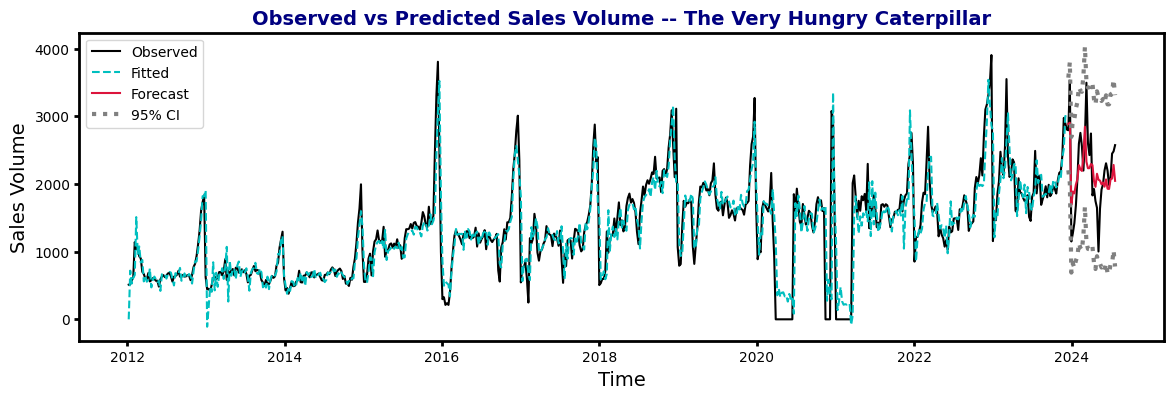

In [ ]:
# Plot the predictions
plot_arima_results('The Very Hungry Caterpillar',
                   book_data_caterpillar,ts_caterpillar_train,
                   arima_fitted_caterpillar,arima_forecast_caterpillar,
                   arima_CI_caterpillar,
                   'arima_caterpillar.svg')

**'The Very Hungry Caterpillar' Forecast:**

The values fitted using the 'best model' closely follow the original timeseries, except it does not always match the seasonal amplitude.

It can be seen from the fluctuations that it struggles with emulating the 0-valued gaps in the 2020-2022 window which comprises a more significant short-term shock caused by the Covid pandemic that cannot be accounted for, using forecasted errors.

The straight line rising steeply aroud 2012 and around 2013 is the result of initiation bias as the model adjusts its parameters during training.

With all the aforementioned points taken into account, the model appears to fit the training data well but not necessarily the test data. In other words, it fails to generalise adequately: The initial rise and falls in the sales volume is predicted well, up to mid-way between 2024 and 2025 where it predicts a small rise when there is a sharp decline. It recovers over the last quarter but also struggles to predict the correct amplitudes for the sales.

The confidence intervals resulting from the error between the predicted to observed sales data appears realistic such that the forecast can be said to agree with the observed data within 2 standard deviations (95% CI).

**For 'The Alchemist':**


In [ ]:
# Forecast data
arima_forecast_alchemist = list_results[1].get_forecast(steps=32)

In [ ]:
# Confidence Interval
arima_CI_alchemist=arima_forecast_alchemist.conf_int()

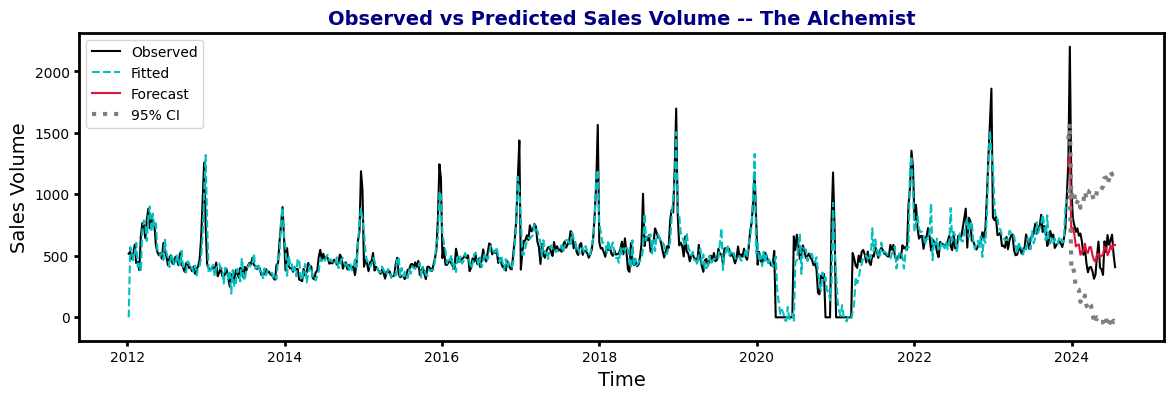

In [ ]:
# Plot the predictions
plot_arima_results('The Alchemist',
                   book_data_alchemist,ts_alchemist_train,
                   arima_fitted_alchemist,arima_forecast_alchemist,
                   arima_CI_alchemist,
                   'arima_alchemist.svg')

**'The Alchemist' Forecast:**

The predicted trend and seasonal components appear to match the observed data well, but there appears to be an issue with predicting the seasonal peak heights - the actual sales volume accurately.

While the model experiences a slight initiation bias at the 2012 mark, there is good agreement within the 2012-2019 time window.

Post 2019, additional peak forms appear which could be indicative of the seasonal components of the SARIMAX model not adjusting well especially following the shock induced by the Covid pandemic around 2020-2021.

The Covid-induced flat gaps themselves are modelled well considering no exogenous features were provided to the model for context.

The forecast made on the test set comes close to matching the general trend but misses the dip that follows the sharp peak. It also significantly undershoots the peak height.

As a result of this significant undershoot, the confidence interval does not extend to the bounds of the actual data points. If the confidence interval was to be exteded to 99.7% then perhaps the forecast horizon would better match the observed data within the last 32 weeks.

However, another issue is the more extreme nature of the seasonal peak which occurs after 2024, following an (earlier) trend that was disrupted by the short-term shock induced by the Covid pandemic. Hence, the model struggles to generalise and falls short in capturing the true trends under the current error forecasting approach.

### 3.8 Comment on how the prediction compares with the actual values.

In additoin to the comments above the mean absolute and squared errors appear relatively large but when we take into the account the percentage errors, it can be seen that the two SARIMAX models return ~20%. This means the predicted sales volumes per book title is on average far off by roughly 20% compared to the actual sales records.

In [ ]:
# Calculate MSE
titles=['The Very Hungry Caterpillar','The Alchemist']
arima_predictions=[arima_forecast_caterpillar.predicted_mean,arima_forecast_alchemist.predicted_mean]
test_data=[ts_caterpillar_test,ts_alchemist_test]

for title,test,forecast in zip(titles, test_data, arima_predictions):
  mse = mean_squared_error(test, forecast)
  mae = mean_absolute_error(test,forecast)
  mape = mean_absolute_percentage_error(test,forecast)
  # Print model name and combination
  print('\033[1m',title, '\n', '-'*40,'\n')
  # print('\033[0m',f"Mean Squared Error: {round(mse,3)}", '\n')
  print('\033[0m',f"Mean Absolute Error: {round(mae,3)}", '\n')
  print('\033[0m',f"Mean Absolute Percentage Error: {round(mape,3)}", '\n')

 The Very Hungry Caterpillar 
 ---------------------------------------- 

 Mean Absolute Error: 350.472 

 Mean Absolute Percentage Error: 0.185 

 The Alchemist 
 ---------------------------------------- 

 Mean Absolute Error: 132.427 

 Mean Absolute Percentage Error: 0.219 



## 4.Machine learning and deep learning techniques

### 4.1 Prepare the data to feed into the machine learning models. The forecast horizon is 32 weeks. The training data consists of all prior data, from 2012-01-01.

In the current scenario, it would be ideal to use a historical window length of 52 weeks (full anual seasonal cycle, 12 months) to predict the last 32 weeks (8 months). Here window length dictates how far back the model looks to understand recent trends, whereas the forecasting horizon is how far forward the model predicts.

Assuming $y= X_t $, if we look back 52 weeks to predict the next 32 weeks, then we would have to:

* Use [$X_{t-51}$,$X_{t-50}$..., $X_{t-1}$, $X_t$] → Predict $X_{t+1}$

* Use [$X_{t-50}$,..., $X_{t-1}$, $X_t$, $X_{t+1}$] → Predict $X_{t+2}$

* Use [$X_{t-49}$,..., $X_{t-1}$, $X_t$, $X_{t+1}$,$X_{t+2}$ ] → Predict $X_{t+3}$

* <br>
* <br>
* <br>

* Use[$X_{t-20}$,...,$X_{t-1}$, $X_t$, $X_{t+1}$...$X_{t+31}$] → Predict $X_{t+32}$


In other words, we would be dynamically shifting the regression window to include the most recent predictions (or the most recent history) to forecast into the future. Thus, to automate the process such that we can generate multiple single-step forecasts while handling the recursive historical data feeding, it is ideal to use a built-in 'recursive_forecaster' in the XGBoost pipeline.

This then simplifies the data preparation process to chrolonogical splitting as follows:

In [ ]:
# Chronological split of data into train and test sets

# Book 1
y_train_caterpillar, y_test_caterpillar = ts_caterpillar_train, ts_caterpillar_test

# Book 2
y_train_alchemist, y_test_alchemist = ts_alchemist_train, ts_alchemist_test

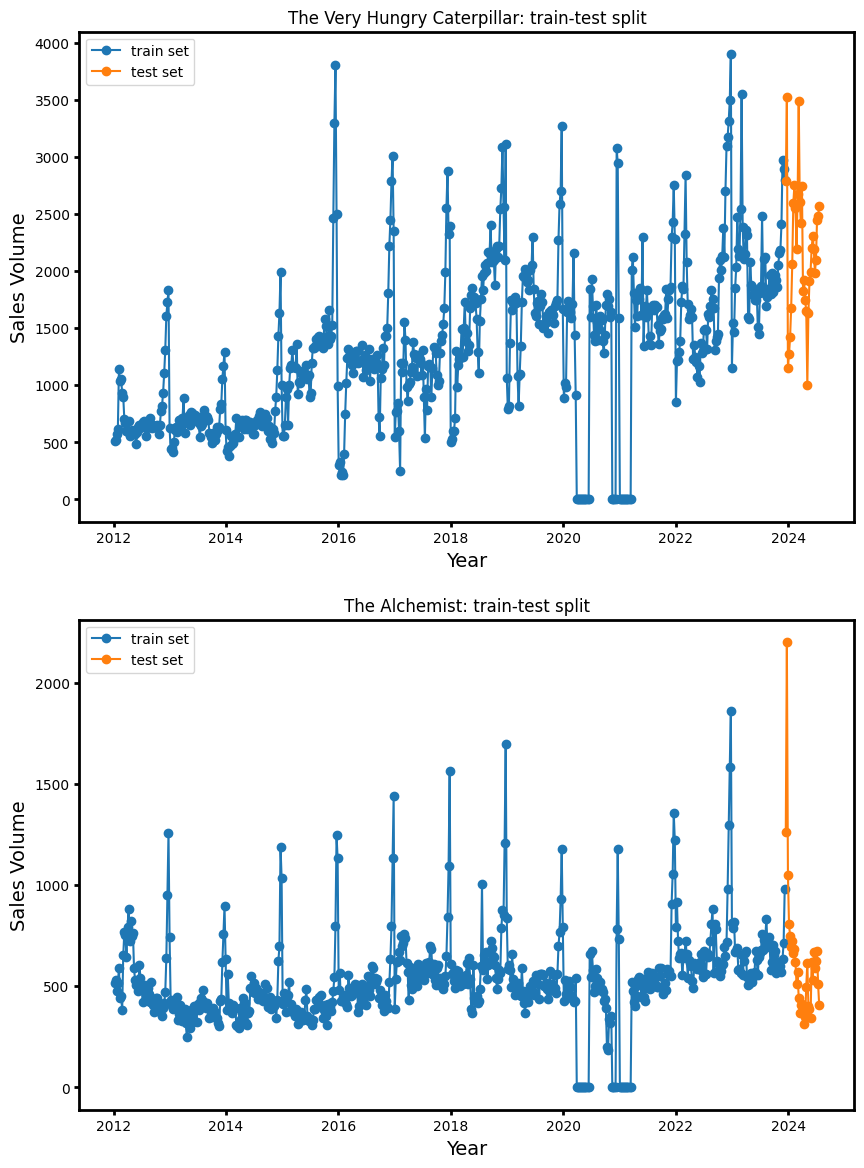

In [ ]:
# Visualise the train-test split
fig, axes = plt.subplots(2, 1,figsize=(10,14))


axes[0].plot(y_train_caterpillar.index,y_train_caterpillar.values,'-o',label='train set')
axes[0].plot(y_test_caterpillar.index,y_test_caterpillar.values,'-o',label='test set')

axes[1].plot(y_train_alchemist.index,y_train_alchemist.values,'-o',label='train set')
axes[1].plot(y_test_alchemist.index,y_test_alchemist.values,'-o',label='test set')


# titles and labels
for i in range(2):
  axes[i].set_title(f"{titles[i]}: train-test split")
  axes[i].set_xlabel('Year',fontsize=14)
  axes[i].set_ylabel('Sales Volume',fontsize=14)
  axes[i].legend(loc='upper left')

axes =fig.axes
for ax in axes:
    ax.tick_params(width=2)
    # Change spine (axis line) thickness
    for edge in ['top', 'bottom', 'left', 'right']:
        ax.spines[edge].set_linewidth(2)

#plt.savefig('train_test_split.svg')
plt.show()


Before forecasting, it will be helpful to provide the model with context in the form a dummy exogenous variable indicating which weekly sales records are affected by the Covid-19 pandemic lockdowns. In the current scenario, the 2020-2022 window will be labelled as 'Covid-19 impacted'. The period March 2020 - July 2021 constitutes two full cycles (104 weeks), of which 27 weeks are already composed of zero values.


In [ ]:
# Function to create a dataframe column that tells models
# if a date corresponds to a pandemic disruption period

def create_exogenous_var(dataframe, datatype):

  # Copy dataframe
  df_sales=dataframe.copy()

  # Initialize the exogenous feature to ~0 or 'No'
  if datatype == 'Numerical':
    df_sales['is_Covid'] = 1e-9
  elif datatype == 'Categorical':
    df_sales['is_Covid'] = 'No'


  # Define the exact timelines based on your historical UK lockdown data
  lockdowns = [
    {
        "name": "First Lockdown",
        "start": "2020-03-23",
        "end": "2020-06-15",
        "weeks_before": 2,
        "weeks_after": 2
    },
    {
        "name": "Second Lockdown",
        "start": "2020-10-31",
        "end": "2020-12-02",
        "weeks_before": 1,
        "weeks_after": 1
    },
    {
        "name": "Third Lockdown",
        "start": "2021-01-04",
        "end": "2021-07-19",
        "weeks_before": 1,
        "weeks_after": 1
    }
  ]

  # Loop through each lockdown, apply shoulder adjustments, and flag the index
  for phase in lockdowns:
    # Convert string dates to pandas timestamps
    start_dt = pd.to_datetime(phase["start"])
    end_dt = pd.to_datetime(phase["end"])

    # Calculate the extended shoulder boundaries
    adjusted_start = start_dt - pd.Timedelta(weeks=phase["weeks_before"])
    adjusted_end = end_dt + pd.Timedelta(weeks=phase["weeks_after"])

    # Flag the entire window in your dataframe
    if datatype == 'Numerical':
      df_sales.loc[adjusted_start:adjusted_end, 'is_Covid'] =  1.0
    elif datatype == 'Categorical':
      df_sales.loc[adjusted_start:adjusted_end, 'is_Covid'] = 'Yes'

    print(f"Flagged {phase['name']}: {adjusted_start.strftime('%Y-%m-%d')} to {adjusted_end.strftime('%Y-%m-%d')}")

  return df_sales.drop('Volume',axis=1)

In [ ]:
# Prepare the exogenous feature as before
print('Book 1', '\n', '='*50)
X_xgb_caterpillar = create_exogenous_var(book_data_caterpillar,datatype='Numerical')

print('\n','Book 2', '\n', '='*50)
X_xgb_alchemist = create_exogenous_var(book_data_alchemist,datatype='Numerical')

Book 1 
Flagged First Lockdown: 2020-03-09 to 2020-06-29
Flagged Second Lockdown: 2020-10-24 to 2020-12-09
Flagged Third Lockdown: 2020-12-28 to 2021-07-26

 Book 2 
Flagged First Lockdown: 2020-03-09 to 2020-06-29
Flagged Second Lockdown: 2020-10-24 to 2020-12-09
Flagged Third Lockdown: 2020-12-28 to 2021-07-26


In [ ]:
# Perform train-test split on the exogenous input variable, X
# Book 1
X_train_caterpillar, X_test_caterpillar = X_xgb_caterpillar[:-32], X_xgb_caterpillar[-32:]
# Book 2
X_train_alchemist, X_test_alchemist = X_xgb_alchemist[:-32], X_xgb_alchemist[-32:]

In [ ]:
print(y_train_caterpillar.shape,y_test_caterpillar.shape)
print(X_train_caterpillar.shape,X_test_caterpillar.shape)
print(y_train_alchemist.shape,y_test_alchemist.shape)
print(X_train_alchemist.shape,X_test_alchemist.shape)

(623, 1) (32, 1)
(623, 1) (32, 1)
(623, 1) (32, 1)
(623, 1) (32, 1)


<Axes: xlabel='End_Date'>

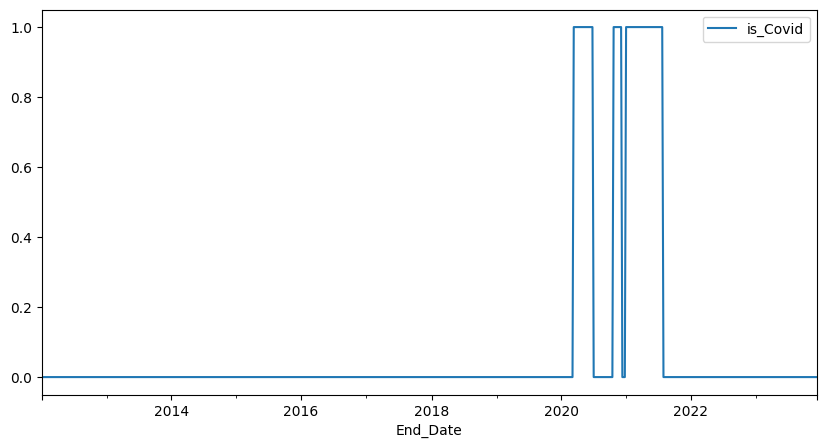

In [ ]:
X_train_alchemist.plot()

When the XGBoost model looks back 52 weeks from December 2023, it lands on December 2022. If any trailing disruption flags are active for late 2022 (i.e. if some recovery windows are added as buffers), the model encounters a historical row where 'is_Covid' is 1.

### 4.2 Create the required pipeline for the XGBoost model.

 The pipeline does not rely on the forecaster internally storing every past data point. Thus, to silence the future warnings and opt into the memory-saving performance, will set remember_data=False.

In [ ]:
# Overwrite the warning handler

# Use a specific attribute on the warnings module to prevent infinite loops if re-run
if not hasattr(warnings, "_original_handler_saved"):
    warnings._original_handler_saved = warnings.showwarning # store original system warning function to avoid breaking other warnings
# Define custom filter function with the exact signature Python expects
def custom_filter(message, category, filename, lineno, file=None, line=None):
    if "remember_data" in str(message):
        return  # Silently drop the sktime warning

    #  Otherwise, pass it through to the original system handler
    return warnings._original_handler_saved(message, category, filename, lineno, file, line)

# Apply the filter safely
warnings.showwarning = custom_filter

In addition to the context provided by the exogenous variable in the form of a 'is_Covid' flag, a Yeo-Johnson transformer is also added to the pipeline to help reduce the skew caused by the zero-Covid values.

In [ ]:
# Create a pipeline with detrender and deseasonaliser.
def create_predictor_xgboost(seasonal_model, sp, degree, window_length):

# Base XGBoost Regressor
  regressor=Pipeline([
      # The imputer looks through the incoming feature matrix (X) for any blank cells, missing values, or NaN symbols
      # and replaces them with zeros. This is a safe guard against NaN values.
                      ('imputer', SimpleImputer(strategy='constant', fill_value=0)),
                      ('xgb',XGBRegressor(n_estimators=400,
                          min_child_weight=1,
                          max_depth=7,
                          learning_rate=0.1,
                          booster='gbtree',
                          tree_method='exact',
                          reg_alpha=0,
                          subsample=0.5,
                          validate_parameters=1,
                          colsample_bylevel=1,
                          colsample_bynode=1,
                          colsample_bytree=1,
                          gamma=0,
                          objective='reg:squarederror'
                      ))
                    ])

  # Define the Yeo-Johnson step
  yeo_johnson_transformer = TabularToSeriesAdaptor(
      PowerTransformer(method="yeo-johnson", standardize=True)
  )


  # Create the recursive reduction forecaster
  # strategy="recursive" ensures it loops 1-step-ahead during inference
  recursive_forecaster = make_reduction(
      estimator=regressor,
      strategy="recursive",
      scitype='tabular-regressor',
      window_length=window_length,
  )

  # Apply memory saving to reduction forecaster directly
  recursive_forecaster.set_config(remember_data=False)

  # Create the trend forecaster
  trend_forecaster = PolynomialTrendForecaster(degree=degree)

  # Apply memory saving to the trend forecaster directly
  trend_forecaster.set_config(remember_data=False)



  # Wrap everything in target transformations
  forecaster = TransformedTargetForecaster(
      [   ("yeo_johnson", yeo_johnson_transformer),
          ("deseasonalize", Deseasonalizer(model=seasonal_model, sp=sp)),
          ("detrend", Detrender(forecaster=trend_forecaster)),
          ("forecast", recursive_forecaster),
      ]
  )

  # Enforce memory saving to the parent pipeline and clear global warnings flag
  forecaster.set_config(remember_data=False,display_warnings=False)

  return forecaster

In [ ]:
# Instantiate the baseline XGBoost regressor for each book
# The Very Hungry Caterpillar
xgb_base_caterpillar=create_predictor_xgboost(seasonal_model='additive',sp=52,degree=1,window_length=52)
# The Alchemist
xgb_base_alchemist=create_predictor_xgboost(seasonal_model='additive',sp=52,degree=1,window_length=52)

In [ ]:
xgb_base_alchemist.get_params().keys()

dict_keys(['steps', 'yeo_johnson', 'deseasonalize', 'detrend', 'forecast', 'yeo_johnson__fit_in_transform', 'yeo_johnson__input_type', 'yeo_johnson__pass_y', 'yeo_johnson__pooling', 'yeo_johnson__transformer', 'yeo_johnson__transformer__copy', 'yeo_johnson__transformer__method', 'yeo_johnson__transformer__standardize', 'deseasonalize__model', 'deseasonalize__sp', 'detrend__forecaster', 'detrend__model', 'detrend__forecaster__degree', 'detrend__forecaster__prediction_intervals', 'detrend__forecaster__regressor', 'detrend__forecaster__with_intercept', 'forecast__estimator', 'forecast__pooling', 'forecast__transformers', 'forecast__window_length', 'forecast__estimator__memory', 'forecast__estimator__steps', 'forecast__estimator__transform_input', 'forecast__estimator__verbose', 'forecast__estimator__imputer', 'forecast__estimator__xgb', 'forecast__estimator__imputer__add_indicator', 'forecast__estimator__imputer__copy', 'forecast__estimator__imputer__fill_value', 'forecast__estimator__imp

Note:
An additive seasonal component is applied due to imputation with 0.

A global (long-term) trend is assumed for both the 'The Very Hungry Caterpillar' dataset and 'The Alchemist' dataset based on the auto ARIMA results.

Based on the decompositions obtained earlier the trend appears to have a quadratic nature; however using high degree polynomials in the XGBoost pipeline can cause issues with volatility outside the training range.

### 4.3 Perform cross-validation.

In [ ]:
# Function to perform manual cross-validation in an expanding window fashion
def manual_expanding_window_cross_validation(n_splits,X_train,y_train,test_size,model):
  fold_mae_scores=[]
  # Set frequency
  if not isinstance(X_train.index, pd.PeriodIndex):
      X_train.index = pd.PeriodIndex(X_train.index, freq='W')
  # Clean and reset index format before setting PeriodIndex
  if not isinstance(y_train.index, pd.PeriodIndex):
      y_train.index = pd.PeriodIndex(y_train.index, freq='W')
  # Set-up TimeSeriesSplit
  tscv = TimeSeriesSplit(n_splits=n_splits, test_size=test_size)
  # Perform split and iterate through the chronological folds
  for fold, (train_index, val_index) in enumerate(tscv.split(y_train)):
    X_fold_train, X_fold_val = X_train.iloc[train_index], X_train.iloc[val_index]
    y_fold_train, y_fold_val = y_train.iloc[train_index], y_train.iloc[val_index]

    model.fit(y=y_fold_train,X=X_fold_train)
    y_pred = model.predict(fh=np.arange(1, test_size + 1),X=X_fold_val)

    # Handle alignment edge cases if y_pred structure returns missing targets
    if hasattr(y_pred, "ffill"):
        y_pred = y_pred.ffill().bfill()

    # Calculate and store current fold's MAE score
    fold_mae=mean_absolute_error(y_fold_val,y_pred)
    fold_mae_scores.append(fold_mae)

    print(f"Fold {fold+1} -- MAE: {fold_mae:.4f} ")

# Return the mean MAE Score
  ave_mae=np.mean(fold_mae_scores)
  print(f"\n Average {n_splits}-Fold Cross-Validation MAE: {ave_mae:.4f}")


Note that the recursive_forecaster withing the XGBoost pipeline automatically slices y_train to create the tabular feature matrix (X) and target vector (y).

In [ ]:
titles=['The Very Hungry Caterpillar','The Alchemist']
print(titles[0],'\n','=' *50)
manual_expanding_window_cross_validation(10,X_train_caterpillar,y_train_caterpillar,32,xgb_base_caterpillar)

The Very Hungry Caterpillar 
Fold 1 -- MAE: 307.0913 
Fold 2 -- MAE: 542.0596 
Fold 3 -- MAE: 260.0601 
Fold 4 -- MAE: 545.4069 
Fold 5 -- MAE: 437.1931 
Fold 6 -- MAE: 1071.7663 
Fold 7 -- MAE: 730.6357 
Fold 8 -- MAE: 468.2293 
Fold 9 -- MAE: 680.4612 
Fold 10 -- MAE: 495.9752 

 Average 10-Fold Cross-Validation MAE: 553.8879


In [ ]:
print(titles[1],'\n', '=' *50)
manual_expanding_window_cross_validation(10,X_train_alchemist,y_train_alchemist,32,xgb_base_alchemist)

The Alchemist 
Fold 1 -- MAE: 1034.3230 
Fold 2 -- MAE: 164.4845 
Fold 3 -- MAE: 55.7971 
Fold 4 -- MAE: 89.3316 
Fold 5 -- MAE: 128.7930 
Fold 6 -- MAE: 314.8023 
Fold 7 -- MAE: 415.2063 
Fold 8 -- MAE: 89.5894 
Fold 9 -- MAE: 132.7304 
Fold 10 -- MAE: 68.2896 

 Average 10-Fold Cross-Validation MAE: 249.3347


To streamline the process before hyperparameter tuning:

In [ ]:
# Function to perform cross-validation
def cross_validate_xgboost_forecaster(X_train,y_train,sp,window_length,initial_window,step_length):

  # Instantiate forecaster
  forecaster = create_predictor_xgboost(
      seasonal_model="additive", sp=sp, degree=1, window_length=window_length
  )

  # Forecasting horizon to evaluate
  fh= np.arange(1, (step_length+1))

  # Define the Expanding Window Splitter
  cv = ExpandingWindowSplitter(
      initial_window=initial_window,  # Size of the first training window (~ batch size)
      step_length=step_length, # How many steps to slide forward each iteration
      fh=fh,  # Forecasting horizon
  )

  # Run the cross-validation
  cv_results = evaluate(
      forecaster=forecaster,
      y=y_train, # Target time series
      X=X_train, # Exogenous feature
      cv=cv,
      scoring=MeanAbsolutePercentageError(symmetric=True),  # Defaults to MeanAbsolutePercentageError
      strategy="refit",  # Retrains the model at each window step
  )

  return cv_results

In [ ]:
cv_results_caterpillar=cross_validate_xgboost_forecaster(X_train_caterpillar.values,y_train_caterpillar.values,52,52,260,32)

In [ ]:
cv_results_caterpillar

,test_MeanAbsolutePercentageError,fit_time,pred_time,len_train_window,cutoff
0,0.211529,0.247836,0.045926,260,259
1,0.248230,0.278829,0.044631,292,291
2,0.489493,0.315830,0.045135,324,323
3,0.264229,0.335351,0.044154,356,355
4,0.201769,0.377581,0.044955,388,387
5,0.880221,0.415374,0.045040,420,419
6,1.176571,0.550290,0.062551,452,451
7,0.951848,0.521869,0.060300,484,483
8,0.270138,0.586802,0.046232,516,515
9,0.430072,0.577109,0.061404,548,547


Text(0.5, 0, 'Fold Iteration')

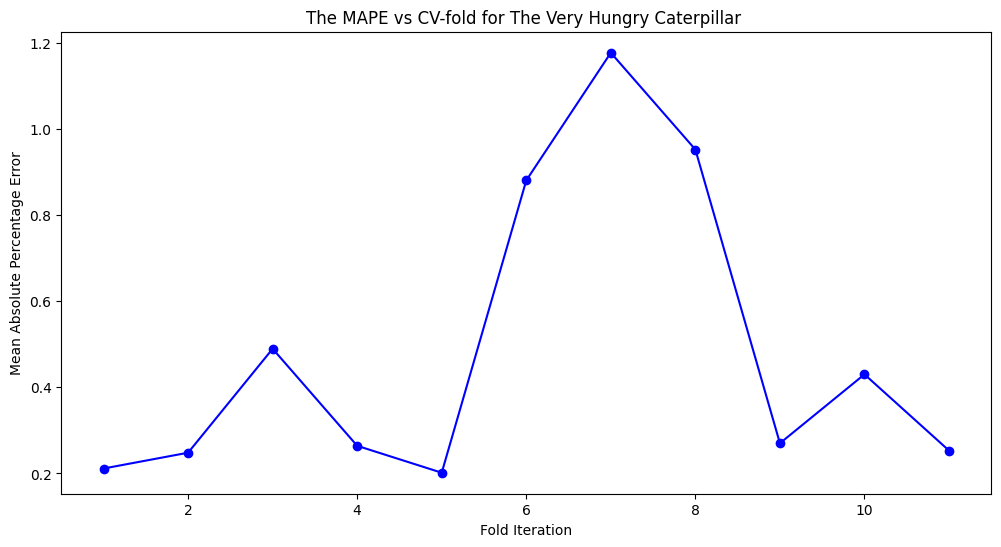

In [ ]:
# Visualise Results
plt.figure(figsize=(12, 6))
plt.plot(np.array(range(1,12,1)),cv_results_caterpillar['test_MeanAbsolutePercentageError'],'-ob')
plt.title('The MAPE vs CV-fold for The Very Hungry Caterpillar ')
plt.ylabel('Mean Absolute Percentage Error')
plt.xlabel('Fold Iteration')
#plt.savefig('CV_caterpillar_weekly.svg')

In [ ]:
cv_results_alchemist=cross_validate_xgboost_forecaster(X_train_alchemist.values,y_train_alchemist.values,52,52,260,32)

In [ ]:
cv_results_alchemist

,test_MeanAbsolutePercentageError,fit_time,pred_time,len_train_window,cutoff
0,0.438018,0.265298,0.045242,260,259
1,0.292908,0.278811,0.045430,292,291
2,0.211040,0.309259,0.043692,324,323
3,0.198080,0.350026,0.047048,356,355
4,0.156649,0.364517,0.043757,388,387
5,0.835947,0.421743,0.045399,420,419
6,1.325396,0.434260,0.044148,452,451
7,1.440349,0.467507,0.045693,484,483
8,0.196652,0.489618,0.044580,516,515
9,0.177415,0.552225,0.047080,548,547


Text(0.5, 0, 'Fold Iteration')

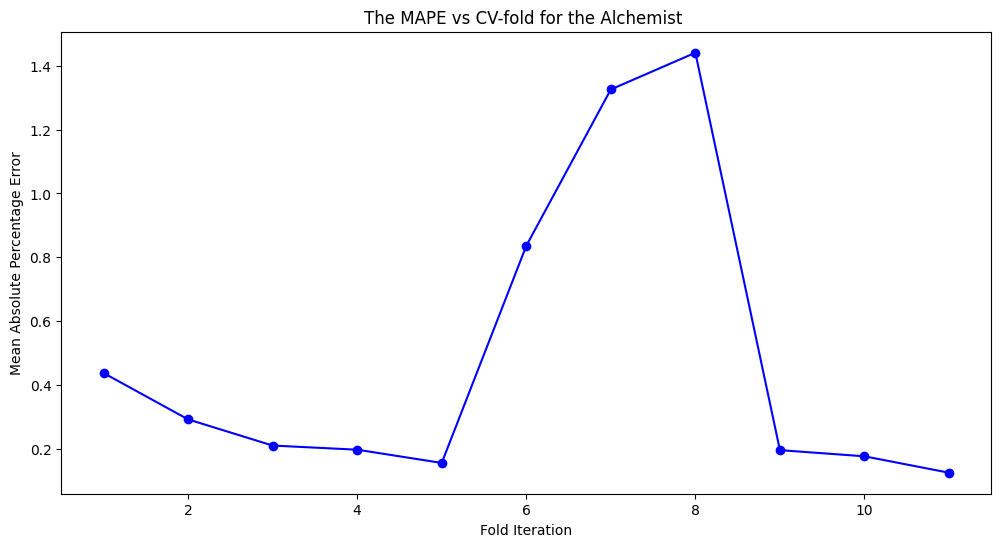

In [ ]:
# Visualise Results
plt.figure(figsize=(12, 6))
plt.plot(np.array(range(1,12,1)),cv_results_alchemist['test_MeanAbsolutePercentageError'],'-ob')
plt.title('The MAPE vs CV-fold for the Alchemist ')
plt.ylabel('Mean Absolute Percentage Error')
plt.xlabel('Fold Iteration')
# plt.savefig('CV_alchemist_weekly.svg')

In [ ]:
display(book_data_alchemist[419:547])

,Volume
End_Date,
2020-01-19,461
2020-01-26,442
2020-02-02,495
2020-02-09,525
2020-02-16,496
...,...
2022-05-29,586
2022-06-05,619
2022-06-12,661


It is clear that a peak results in the folds spanning from 5-9, due to the model struggling to generalise to the zero-valued gaps in data introduced by the Covid lock downs. However, the MAPE score later recovers meaning by adjusting the lookback window length it may be possible to avoid error accumulation to an extent.

### 4.4 Perform parameter tuning (including window_length) using grid search.

In [ ]:
torch.cuda.empty_cache()

In [ ]:
set_random_seed(42)

In [ ]:
# Define the parameter grid
# Structure: [step_name]__[component]__[parameter]
param_grid_1 = {
  # Tune the sktime reduction window length
  "forecast__window_length":[26, 32, 52],
  # Tune the nested XGBoost regressor parameters
  "forecast__estimator__xgb__max_depth":[6, 8, 10],
  "forecast__estimator__xgb__gamma": [0,2],
  "forecast__estimator__xgb__n_estimators":[200, 300, 400],
  "forecast__estimator__xgb__reg_alpha":list(range(40,180,40)),
  "forecast__estimator__xgb__colsample_bytree":[0.5,0.7,1]
  }

In [ ]:
def tune_xgboost_model_grid(param_grid,X_train,y_train,step_length, initial_window):
  # Instantiate the base forecaster pipeline
  forecaster = create_predictor_xgboost(
    seasonal_model="additive", sp=52, degree=1, window_length=52
  )

  # Set-up the Expanding Window CV Splitter
  cv = ExpandingWindowSplitter(
    initial_window=initial_window,  # Size of first training split
    step_length=step_length,  # Expand window by 3 steps each fold
    fh=np.arange(1, (step_length+1)),  # Forecasting horizon to validate against
  )

  # Set-up the Grid Search
  gscv = ForecastingGridSearchCV(
    forecaster=forecaster,
    param_grid=param_grid,
    cv=cv,
    n_jobs=-1,  # Spawns multiple CPU processes to feed the A100 GPU
    scoring=MeanAbsolutePercentageError(symmetric=True),
    strategy="refit",  # Complete retraining for each window/param combo
    verbose=1,
  )

  # Run the grid search optimization
  gscv.fit(X=X_train, y=y_train)

  # Extract results
  print(f"Best Parameters: {gscv.best_params_}")
  print(f"Best Score: {gscv.best_score_}")
  #best_model = gscv.best_forecaster_

  best_model = {
        "model": gscv.best_forecaster_,
        "params": gscv.best_params_,
        "score": gscv.best_score_
    }

  return best_model

The XGBoost has several tunable hyperparameters of which the following would be high-priority:

* 'n_estimators': Sets the number of trees in the ensemble. Too low a value risks underfitting, while too high wastes computational resources.

* 'max_depth': Restricts the number of levels that the tree can have. The maximum depth can take on an integer value or default to 'None', allowing the tree to reach its maximum possible depth.

* 'gamma': Helps manage tree complexity by determining when a node will be split based on reduction in loss (or increase in gain). Higher gamma values make the algorithm more conservative and result in simpler, shallower trees.

* 'colsample_bytree': Establishes the percentage of features that will be sampled at random for growing each tree.

*  'reg_alpha' : Controls the strength of the L1 regularisaton term.

'learning_rate' which prevents overfitting by controlling step size shrinkage used in learner update  is also important but since lower values require longer training, we will keep this fixed to rasonable value for the grid seearch.

**HYPERPARAMETER TUNING ROUND 1:**

In [ ]:
best_model_caterpillar_5CV=tune_xgboost_model_grid(param_grid_1,X_train_caterpillar.values,y_train_caterpillar.values,step_length=32, initial_window=436)

Fitting 5 folds for each of 648 candidates, totalling 3240 fits
Best Parameters: {'forecast__estimator__xgb__colsample_bytree': 1, 'forecast__estimator__xgb__gamma': 0, 'forecast__estimator__xgb__max_depth': 10, 'forecast__estimator__xgb__n_estimators': 200, 'forecast__estimator__xgb__reg_alpha': 40, 'forecast__window_length': 32}
Best Score: 0.4007451435505117


In [ ]:
best_model_caterpillar_5CV["params"]

{'forecast__estimator__xgb__colsample_bytree': 1,
 'forecast__estimator__xgb__gamma': 0,
 'forecast__estimator__xgb__max_depth': 10,
 'forecast__estimator__xgb__n_estimators': 200,
 'forecast__estimator__xgb__reg_alpha': 40,
 'forecast__window_length': 32}

In [ ]:
best_model_alchemist_5CV=tune_xgboost_model_grid(param_grid_1,X_train_alchemist.values,y_train_alchemist.values,step_length=32, initial_window=436)

Fitting 5 folds for each of 648 candidates, totalling 3240 fits
Best Parameters: {'forecast__estimator__xgb__colsample_bytree': 1, 'forecast__estimator__xgb__gamma': 0, 'forecast__estimator__xgb__max_depth': 10, 'forecast__estimator__xgb__n_estimators': 400, 'forecast__estimator__xgb__reg_alpha': 40, 'forecast__window_length': 26}
Best Score: 0.4490578882096691


In [ ]:
best_model_alchemist_5CV["params"]

{'forecast__estimator__xgb__colsample_bytree': 1,
 'forecast__estimator__xgb__gamma': 0,
 'forecast__estimator__xgb__max_depth': 10,
 'forecast__estimator__xgb__n_estimators': 400,
 'forecast__estimator__xgb__reg_alpha': 40,
 'forecast__window_length': 26}

**HYPERPARAMETER TUNING ROUND 2:** Trading depth for softer regularisation


In [ ]:
# Define a new parameter grid which trades depth for softer regularisation
# Structure: [step_name]__[component]__[parameter]
param_grid_2 = {
  # Tune the sktime reduction window length
  "forecast__window_length":[26, 32, 48, 52],
  # Tune the nested XGBoost regressor parameters
  "forecast__estimator__xgb__max_depth":[3, 5, 7],
  "forecast__estimator__xgb__gamma": [0,2],
  "forecast__estimator__xgb__n_estimators":[200, 300, 400],
  "forecast__estimator__xgb__reg_alpha":[0, 1, 10, 50],
  "forecast__estimator__xgb__colsample_bytree":[0.5,0.7,1]
  }

Following are the results obtained for 'The Very Hungry Caterpillar':

In [ ]:
best_model2_caterpillar_5CV=tune_xgboost_model_grid(param_grid_2,X_train_caterpillar.values,y_train_caterpillar.values,step_length=32, initial_window=436)

Fitting 5 folds for each of 864 candidates, totalling 4320 fits
Best Parameters: {'forecast__estimator__xgb__colsample_bytree': 1, 'forecast__estimator__xgb__gamma': 0, 'forecast__estimator__xgb__max_depth': 5, 'forecast__estimator__xgb__n_estimators': 400, 'forecast__estimator__xgb__reg_alpha': 50, 'forecast__window_length': 48}
Best Score: 0.4072841850542631


In [ ]:
best_model2_caterpillar_5CV["params"]

{'forecast__estimator__xgb__colsample_bytree': 1,
 'forecast__estimator__xgb__gamma': 0,
 'forecast__estimator__xgb__max_depth': 5,
 'forecast__estimator__xgb__n_estimators': 400,
 'forecast__estimator__xgb__reg_alpha': 50,
 'forecast__window_length': 48}

Following are the results obtained for 'The Alchemist':

In [ ]:
best_model2_alchemist_5CV=tune_xgboost_model_grid(param_grid_2,X_train_alchemist.values,y_train_alchemist.values,step_length=32, initial_window=436)

Fitting 5 folds for each of 864 candidates, totalling 4320 fits
Best Parameters: {'forecast__estimator__xgb__colsample_bytree': 1, 'forecast__estimator__xgb__gamma': 0, 'forecast__estimator__xgb__max_depth': 5, 'forecast__estimator__xgb__n_estimators': 300, 'forecast__estimator__xgb__reg_alpha': 10, 'forecast__window_length': 32}
Best Score: 0.47149765700946017


In [ ]:
best_model2_alchemist_5CV["params"]

{'forecast__estimator__xgb__colsample_bytree': 1,
 'forecast__estimator__xgb__gamma': 0,
 'forecast__estimator__xgb__max_depth': 5,
 'forecast__estimator__xgb__n_estimators': 300,
 'forecast__estimator__xgb__reg_alpha': 10,
 'forecast__window_length': 32}

To save time and avoid re-running the grid-search as well as re-uploading saved models, will be using the best parameters identified by the grid search to recreate and train the tuned XGBoost regressors.

In [ ]:
best_params_1_caterpillar={'n_estimators':200,
                       'max_depth':10,
                       'reg_alpha':40,
                       'colsample_bytree':1,
                       'gamma':0,
                       'window_length':32,
                       'degree':1}

In [ ]:
best_params_1_alchemist={'n_estimators':400,
                       'max_depth':10,
                       'reg_alpha':40,
                       'colsample_bytree':1,
                       'gamma':0,
                       'window_length':26,
                       'degree':1}

In [ ]:
best_params_2_caterpillar={'n_estimators':400,
                       'max_depth':5,
                       'reg_alpha':50,
                       'colsample_bytree':1,
                       'gamma':0,
                       'window_length':48,
                       'degree':1}

In [ ]:
best_params_2_alchemist={'n_estimators':300,
                       'max_depth':5,
                       'reg_alpha':10,
                       'colsample_bytree':1,
                       'gamma':0,
                       'window_length':32,
                       'degree':1}

In [ ]:
# Function to re-create XGBoost Model with tuned parameters

def tuned_xgboost(best_params,seasonal_model,sp):

    # Base XGBoost Regressor
    regressor= XGBRegressor(n_estimators=best_params['n_estimators'],
                            min_child_weight=1,
                            max_depth=best_params['max_depth'],
                            learning_rate=0.1,
                            booster='gbtree',
                            tree_method='exact',
                            reg_alpha=best_params['reg_alpha'],
                            subsample=0.5,
                            validate_parameters=1,
                            colsample_bylevel=1,
                            colsample_bynode=1,
                            colsample_bytree=best_params['colsample_bytree'],
                            gamma=best_params['gamma'],
                            objective='reg:squarederror'
                           )

    # Define the Yeo-Johnson transformer
    yeo_johnson_transformer = TabularToSeriesAdaptor(
        PowerTransformer(method="yeo-johnson", standardize=True)
    )

    # Create the recursive reduction forecaster
    # strategy="recursive" ensures it loops 1-step-ahead during inference
    recursive_forecaster = make_reduction(
        estimator=regressor,
        scitype="tabular-regressor",
        strategy="recursive",
        window_length=best_params['window_length'],
    )

    # Apply memory saving to reduction forecaster directly
    recursive_forecaster.set_config(remember_data=False)

    # Create the trend forecaster
    trend_forecaster = PolynomialTrendForecaster(degree=best_params['degree'])

    # Apply memory saving to the trend forecaster directly
    trend_forecaster.set_config(remember_data=False)

    # Wrap everything in target transformations
    forecaster = TransformedTargetForecaster(
        [   ("yeo_johnson", yeo_johnson_transformer),
            ("deseasonalize", Deseasonalizer(model=seasonal_model, sp=sp)),
            ("detrend", Detrender(forecaster=trend_forecaster)),
            ("forecast", recursive_forecaster),
        ]
    )

    # Enforce memory saving to the parent pipeline and clear global warnings flag
    forecaster.set_config(remember_data=False,display_warnings=False)

    return forecaster



### 4.5 Identify the best models.

In [ ]:
# Build best model for Book 1
xgb_tuned_caterpillar_1=tuned_xgboost(best_params_1_caterpillar,'additive',52)
# Build best model for Book 2
xgb_tuned_alchemist_1=tuned_xgboost(best_params_1_alchemist,'additive',52)

In [ ]:
# Build the best model '2' for Book 1
xgb_tuned_caterpillar_2=tuned_xgboost(best_params_2_caterpillar,'additive',52)
# Build best model '2' for Book 2
xgb_tuned_alchemist_2=tuned_xgboost(best_params_2_alchemist,'additive',52)

In [ ]:
# Function to fit custom XGBoost models
def fit_xgboost_model(model,X_train,X_test,y_train,y_test,horizon):
  # Fit the model
  model.fit(y=y_train,X=X_train)
  # Forecast on the validation fold
  y_pred=model.predict(fh = np.arange(1, (horizon+1)),X=X_test)
  # Calculate and store current fold's MAE score
  model_mae=mean_absolute_error(y_test,y_pred)
  model_mape=mean_absolute_percentage_error(y_test,y_pred)
  results = {
      "predictions": y_pred,
      "mae": model_mae,
      "mape": model_mape,
  }

  return results


In [ ]:
# Base Model -- 'The Very Hungry Caterpillar'
xgb_caterpillar_baseline=fit_xgboost_model(xgb_base_caterpillar,X_train_caterpillar.values,X_test_caterpillar.values,y_train_caterpillar.values,y_test_caterpillar.values,32)

In [ ]:
# Base Model -- 'The Alchemist'
xgb_alchemist_baseline=fit_xgboost_model(xgb_base_alchemist,X_train_alchemist.values,X_test_alchemist.values,y_train_alchemist.values,y_test_alchemist.values,32)

In [ ]:
# Tuned Models 1 & 2 -- 'The Very Hungry Caterpillar'
xgb_caterpillar_tuned_1=fit_xgboost_model(xgb_tuned_caterpillar_1,X_train_caterpillar.values,X_test_caterpillar.values,y_train_caterpillar.values,y_test_caterpillar.values,32)
xgb_caterpillar_tuned_2=fit_xgboost_model(xgb_tuned_caterpillar_2,X_train_caterpillar.values,X_test_caterpillar.values,y_train_caterpillar.values,y_test_caterpillar.values,32)

In [ ]:
# Tuned Models 1 & 2 -- 'The Alchemist
xgb_alchemist_tuned_1=fit_xgboost_model(xgb_tuned_alchemist_1,X_train_alchemist.values,X_test_alchemist.values,y_train_alchemist.values,y_test_alchemist.values,32)
xgb_alchemist_tuned_2=fit_xgboost_model(xgb_tuned_alchemist_2,X_train_alchemist.values,X_test_alchemist.values,y_train_alchemist.values,y_test_alchemist.values,32)

In [ ]:
# Prepare data frames to serve as mock 'results' tables
caterpillar_models =[xgb_caterpillar_baseline,xgb_caterpillar_tuned_1,xgb_caterpillar_tuned_2]
alchemist_models =  [xgb_alchemist_baseline,xgb_alchemist_tuned_1,xgb_alchemist_tuned_2]

caterpillar_xgb_model_scores=pd.DataFrame(columns=['Model','MAE','MAPE'])
alchemist_xgb_model_scores=caterpillar_xgb_model_scores.copy()

In [ ]:
# List Errors -- Book 1
caterpillar_xgb_model_scores['Model']=['Base Model', 'Tuned Model 1','Tuned Model 2']
for i, model in enumerate(caterpillar_models):
  caterpillar_xgb_model_scores.loc[i,'MAE']= model['mae']
  caterpillar_xgb_model_scores.loc[i,'MAPE']= model['mape']
caterpillar_xgb_model_scores.index.name='Caterpillar'
caterpillar_xgb_model_scores

,Model,MAE,MAPE
Caterpillar,,,
0,Base Model,428.474918,0.195581
1,Tuned Model 1,768.707493,0.331163
2,Tuned Model 2,716.281276,0.307732


In [ ]:
# List Errors -- Book 2
alchemist_xgb_model_scores['Model']=['Base Model', 'Tuned Model 1', 'Tuned Model 2']
for i, model in enumerate(alchemist_models):
  alchemist_xgb_model_scores.loc[i,'MAE']= model['mae']
  alchemist_xgb_model_scores.loc[i,'MAPE']= model['mape']
alchemist_xgb_model_scores.index.name='Alchemist'
alchemist_xgb_model_scores

,Model,MAE,MAPE
Alchemist,,,
0,Base Model,152.241626,0.215526
1,Tuned Model 1,159.459795,0.253968
2,Tuned Model 2,175.881403,0.239976


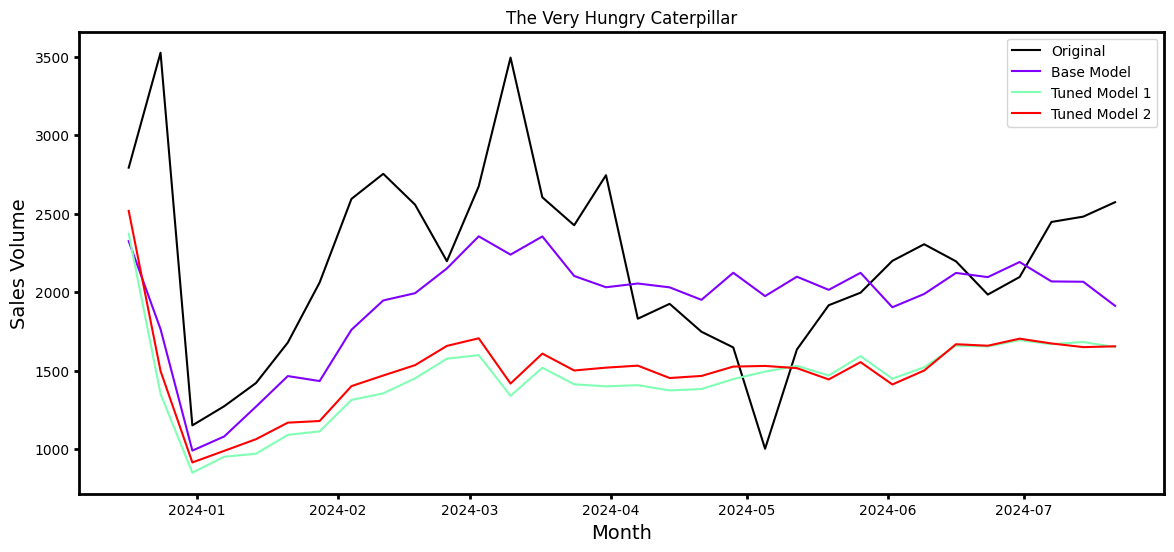

In [ ]:
# Deciding on the best model- The Very Hungry Caterpillar
fig=plt.figure(figsize=(14,6))
colors = iter(cm.rainbow(np.linspace(0, 1,3)))
plt.plot(ts_caterpillar_test.index, ts_caterpillar_test.values, c='black', label='Original')
for i in range(3):
 plt.plot(ts_caterpillar_test.index,caterpillar_models[i]['predictions'], c=next(colors), label= f"{caterpillar_xgb_model_scores.Model[i]}")

# titles & labels
plt.title(f"{titles[0]}")
plt.xlabel('Month',fontsize=14)
plt.ylabel('Sales Volume',fontsize=14)
plt.legend()

axes =fig.axes
for ax in axes:
    ax.tick_params(width=2)
    # Change spine (axis line) thickness
    for edge in ['top', 'bottom', 'left', 'right']:
        ax.spines[edge].set_linewidth(2)

plt.savefig('XGB_model_comparisons_caterpillar.svg')

The predictions made by the pe-tuned model match the original test data better, as also supported by the MAE and MAPE scores. Therefore, the best model for the 'The Very Hungry Caterpillar' dataset is the base model created. Note that all models miss the dip near 2024-05, but broadly speaking follow the general trends.

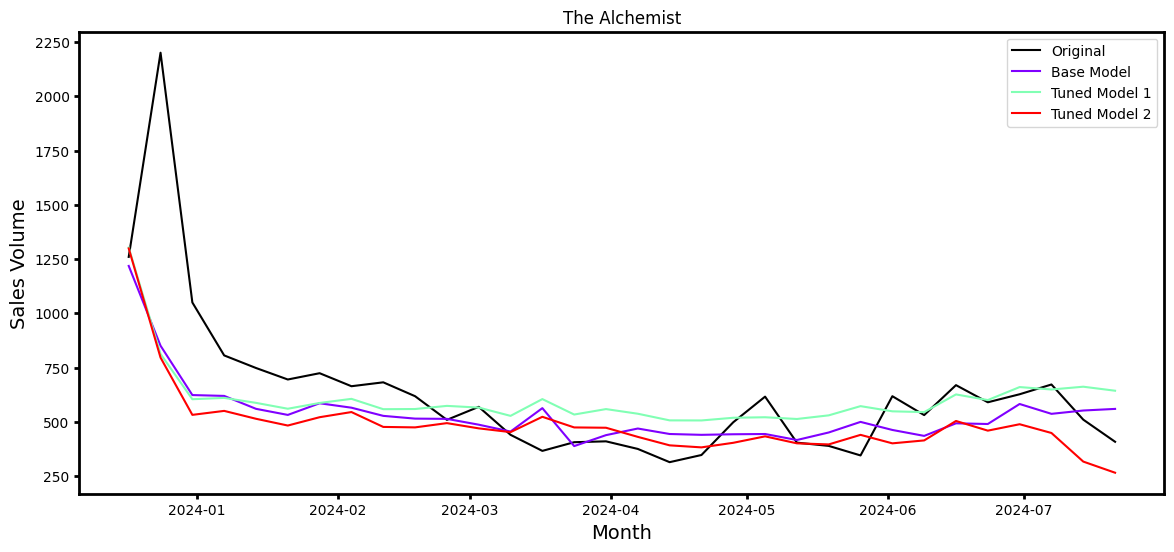

In [ ]:
# Deciding on the best model - The Alchemist
fig=plt.figure(figsize=(14,6))
colors = iter(cm.rainbow(np.linspace(0, 1,3)))
plt.plot(ts_alchemist_test.index, ts_alchemist_test.values, c='black', label='Original')

for i in range(3):
 plt.plot(ts_alchemist_test.index,alchemist_models[i]['predictions'], c=next(colors), label= f"{alchemist_xgb_model_scores.Model[i]}")

# titles & labels
plt.title(f"{title}")
plt.xlabel('Month',fontsize=14)
plt.ylabel('Sales Volume',fontsize=14)
plt.legend()

axes =fig.axes
for ax in axes:
    ax.tick_params(width=2)
    # Change spine (axis line) thickness
    for edge in ['top', 'bottom', 'left', 'right']:
        ax.spines[edge].set_linewidth(2)

plt.savefig('XGB_model_comparisons_alchemist.svg')

None of the fitted models produce predictions that closely match the original test set and at the same time, yield very similar performances. Based on the error scores, the 'Base Model' performs best.

Hyper-parameter tuning does not always return the most optimally performing model since the process is limited by the parameter search grid provided. As a future improvement, the search grid may be extended to contain a wider range as well as more hyperparameters such as the learning rate.

That said, a bigger issue is likely the zero-sales gaps or the extended 2020-2022 Covid window not being directly addressed.

### 4.6 Use the best models to forecast the final 32 weeks of sales data for both books.

In [ ]:
# Final predictions by the best models selected
predictions_xgb_caterpillar = xgb_caterpillar_baseline['predictions']
predictions_xgb_alchemist = xgb_alchemist_baseline['predictions']


In [ ]:
predictions_xgb_caterpillar.shape

(32, 1)

In [ ]:
# Build 95% confidence interval for future forecast
def build_CI(y_test,predictions):
  residuals = y_test.values- predictions
  sigma = np.std(residuals)  # standard deviation of residuals

# Prediction intervals
  int_lower = predictions - 1.96*sigma
  int_upper = predictions + 1.96*sigma
  forecast_int={"lower": int_lower,
                "upper": int_upper}
  return forecast_int


In [ ]:
# Build CIs for visualisation
forecast_int_caterpillar=build_CI(y_test_caterpillar,predictions_xgb_caterpillar)
forecast_int_alchemist=build_CI(y_test_alchemist,predictions_xgb_alchemist)

In [ ]:
forecast_int_caterpillar['lower'].shape

(32, 1)

### 4.7 Plot the original data along with the predictions.

In [ ]:
# Function to plot results
def plot_results(title, series_train, series_test, forecast, mae, mape, forecast_int,plot_color,filename):
  # Clean and reset index format before setting PeriodIndex
  if not isinstance(series_train.index, pd.PeriodIndex):
    series_train.index = pd.PeriodIndex(series_train.index, freq='W')
  if not isinstance(series_test.index, pd.PeriodIndex):
    series_test.index = pd.PeriodIndex(series_test.index, freq="W")

  fig=plt.figure(figsize=(12, 6))
  plt.title(f"{title} - MAE: {mae:.2f}, MAPE: {mape:.3f}", size=18)
  plt.plot(series_train.index.to_timestamp(),series_train.values,label="Train", color="blue")
  plt.plot(series_test.index.to_timestamp(),series_test.values,label="Test", color="coral")
  plt.plot(series_test.index.to_timestamp(),forecast.flatten(),label="Forecast", color=plot_color)

  plt.fill_between(
          series_test.index.to_timestamp(),
          forecast_int["lower"].flatten(),
          forecast_int["upper"].flatten(),
          alpha=0.3,
          color="lightgray",
          label="95% Prediction Interval"
      )

  plt.legend(prop={"size": 12})

  axes =fig.axes
  for ax in axes:
      ax.tick_params(width=2)
      # Change spine (axis line) thickness
      for edge in ['top', 'bottom', 'left', 'right']:
          ax.spines[edge].set_linewidth(2)

  plt.savefig(filename)
  plt.show()

### 4.8 Display the MAE and MAPE.

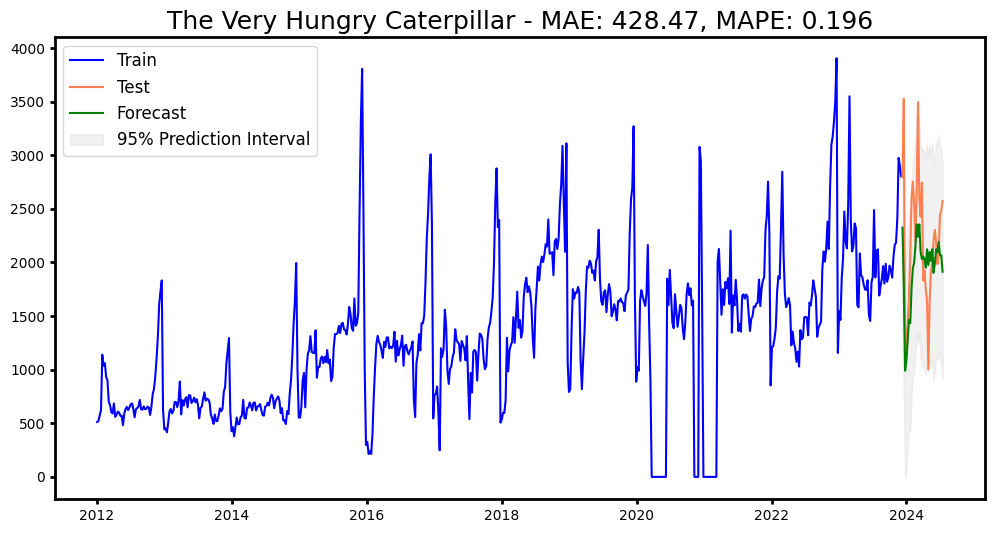

In [ ]:
# Book 1: 'The Very Hungry Caterpillar'
plot_results('The Very Hungry Caterpillar',
             y_train_caterpillar,y_test_caterpillar,
             predictions_xgb_caterpillar,
             xgb_caterpillar_baseline['mae'],xgb_caterpillar_baseline['mape'],
             forecast_int_caterpillar,
             'green', 'XGBoost_forecast_caterpillar.svg')

While the error scores obtained for the forecasted sales volume are in isolation acceptable, it can be seen that the model predicts a sharp fall continuing on from the last 52 week window it was trained on, which is then followed by a more moderate rise and fall. Clearly the pattern resembles but fails to match the observation whereas the confidence interval is unable to accommodate the sharp seasonal rises seen in 2024.

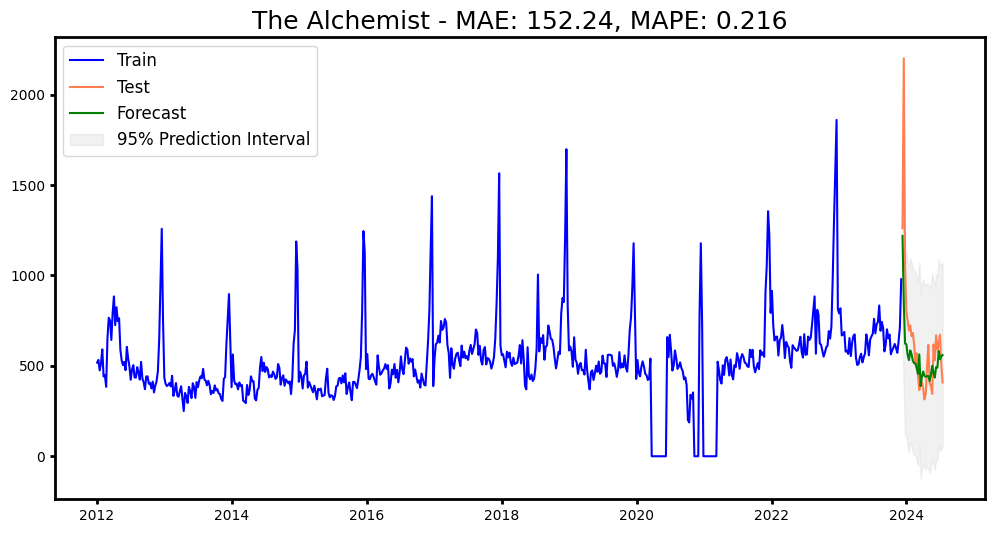

In [ ]:
# Book 2: 'The Alchemist'
plot_results('The Alchemist',
             y_train_alchemist,y_test_alchemist,
             predictions_xgb_alchemist,
             xgb_alchemist_baseline['mae'],xgb_alchemist_baseline['mape'],
             forecast_int_alchemist,
             'green', 'XGBoost_forecast_alchemist.svg')

In the case of 'The Alchemist' timeseries where there is a more clear-cut seasonal as well as long-term trend, the XGBoost model performs better in emulating the sharp rise in sales volume that is followed by a fall and a shallower rise. However, it significantly undershoots the true amplitude which means it is struggling with the longer-term trend which again was distrupted due to the Covid lockdowns.

### 4.9 Create an LSTM model for both books.

**Preparing Input Data for an LSTM**

Given the recursive nature of an LSTM model, the data needs to be organised into sequences of fixed length.

In addition, LSTM models need data to be in a 3D format, i.e. (samples, time steps, features), where:


* Samples: Each sample is one full sequence of observations (i.e. samples can be considered rows of fixed length data).

* Time Steps: The number of time points in your sequence used to make a prediction. This is equivalent to the length of the look-back window or the window_length parameter in XGBoost.

* Features: The number of variables (columns) used at each time step (could be lags or exogenous variables).

For a univariate timeseries, $X_t$ with 600 observations in a given window where the window length is 52 weeks and the horizon is set to be 32 weeks, the input sequences would  have a shape (600, 52, 1) where the output sequences would have a shape (600, 32 , 1).



Since we will be using a deep learning model, an important essential step is to normalise the data such that the weight matrices are not influenced by the true range.

In [ ]:
# To normalise the time series data:
scaler = MinMaxScaler(feature_range=(0, 1))

# Create dataframes with only the scaled training data
df_caterpillar_scaled = pd.DataFrame(index=book_data_caterpillar.index)
df_caterpillar_scaled['Scaled'] = scaler.fit_transform(book_data_caterpillar.values.reshape(-1,1))
df_alchemist_scaled = pd.DataFrame(index=book_data_alchemist.index)
df_alchemist_scaled['Scaled'] = scaler.fit_transform(book_data_alchemist.values.reshape(-1,1))


<Axes: xlabel='End_Date'>

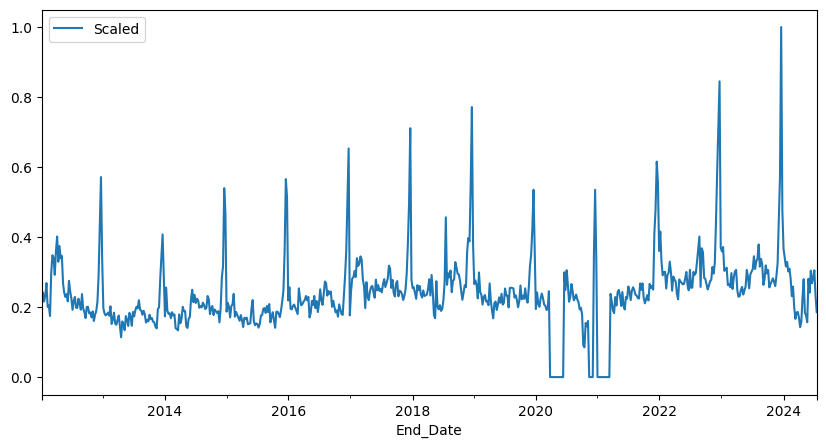

In [ ]:
df_alchemist_scaled.plot()

In [ ]:
# Turn the training series into overlapping windows with multi-step outputs

def make_multi_step_sequences(values, lookback, horizon):
    X, y = [], []
    for i in range(lookback, len(values) - horizon + 1):
        X.append(values[i-lookback:i, 0])
        y.append(values[i:i+horizon, 0])
    X = np.array(X).reshape(-1, lookback, 1)
    y = np.array(y).reshape(-1, horizon, 1) # Reshaped to 3D
    return X, y


As opposed to an exogenous variable that will serve as a masking function for the LSTM model, we skip the lock-down periods entirely. Note that skipping is viable since there are 7 full cycles (7 x 52 weeks) of sales data leading up to the Covid-19 window, followed by over 2 full cycles.

In [ ]:
# Define the lockdown periods with no trailing weeks
lockdown_periods = [
    {
        "name": "First Lockdown",
        "start": "2020-03-23",
        "end": "2020-06-15",
    },
    {
        "name": "Second Lockdown",
        "start": "2020-10-31",
        "end": "2020-12-02",
    },
    {
        "name": "Third Lockdown",
        "start": "2021-01-04",
        "end": "2021-07-19",
    }
  ]

To create the 3D sequences with a desired window length while excluding lockdown periods, will implement the following steps:

In [ ]:
# Function to check if any date in the rolling window falls inside a lockdown period
def is_lockdown(window_dates, lockdowns):
  for lockdown in lockdowns:
    start_date = pd.to_datetime(lockdown["start"])
    end_date = pd.to_datetime(lockdown["end"])
    # Check if the window overlaps with the lockdown range
    if not (window_dates.max() < start_date or window_dates.min() > end_date):
        return True
  return False

In [ ]:
# Build safe inference windows
def create_safe_multi_step_sequences(df_scaled, lockdown_periods, lookback, horizon):
    X_list, y_list= [], []
    # info_list=[]
    # Slide across the dataframe index
    for i in range(len(df_scaled) - lookback - horizon + 1):
        # Extract the exact date ranges for this window
        input_dates = df_scaled.index[i : i + lookback]
        target_dates = df_scaled.index[i + lookback : i + lookback + horizon]

        # Check both the lookback weeks AND the target horizon
        if is_lockdown(input_dates, lockdown_periods) or is_lockdown(target_dates, lockdown_periods):
            continue  # Skip this window entirely

        # If safe, extract the features and targets
        X_window =df_scaled.iloc[i : i + lookback]
        y_window = df_scaled.iloc[i + lookback : i + lookback + horizon]

        X_list.append(X_window)
        y_list.append(y_window)
        #info_list.append({"forecast_origin": input_dates[-1], "target_start": target_dates[0]})

    return np.array(X_list), np.array(y_list) #, info_list


In [ ]:
# Now create the 3D sequences
# Book 1
train_caterpillar_mult_52, test_caterpillar_mult_52 = create_safe_multi_step_sequences(df_caterpillar_scaled,lockdown_periods,lookback=52,horizon=32)
# Book 2
train_alchemist_mult_52, test_alchemist_mult_52 = create_safe_multi_step_sequences(df_alchemist_scaled,lockdown_periods,lookback=52,horizon=32)

In [ ]:
train_alchemist_mult_52.shape

(420, 52, 1)

In [ ]:
# Reserve last training sequences for testing
# Book 1
X_train_caterpillar_mult_52, y_train_caterpillar_mult_52 = train_caterpillar_mult_52[:-1], test_caterpillar_mult_52 [:-1]
X_test_caterpillar_mult_52, y_test_caterpillar_mult_52 = train_caterpillar_mult_52[-1:], test_caterpillar_mult_52 [-1:]
# Book 2
X_train_alchemist_mult_52, y_train_alchemist_mult_52 = train_alchemist_mult_52[:-1], test_alchemist_mult_52[:-1]
X_test_alchemist_mult_52, y_test_alchemist_mult_52 = train_alchemist_mult_52[-1:], test_alchemist_mult_52 [-1:]

**Let's start the analysis with multi-step forecasting and experiment with the window length:**


In [ ]:
print('Book 1')
print('Train:', y_train_caterpillar_mult_52.shape,'==>', y_test_caterpillar_mult_52.shape)
print('Test:', X_test_caterpillar_mult_52.shape,'==>', y_test_caterpillar_mult_52.shape)
print('Book 2')
print('Train',X_train_alchemist_mult_52.shape,'==>', y_train_alchemist_mult_52.shape)
print('Test',X_test_alchemist_mult_52.shape,'==>', y_test_alchemist_mult_52.shape)

Book 1
Train: (419, 32, 1) ==> (1, 32, 1)
Test: (1, 52, 1) ==> (1, 32, 1)
Book 2
Train (419, 52, 1) ==> (419, 32, 1)
Test (1, 52, 1) ==> (1, 32, 1)


Thus, the model is trained on the train sets X_train and y_train, makes predictions on the X_test set (last sequence), but is never exposed to the y_test set which is reserved for forecasting.

**Create an LSTM Model suitable for multi-step forecasting**:

When applying LSTM models to timeseries problems, using a multi-step overlapping window training approach can help mitigate error accumulation.

In [ ]:
set_random_seed(42)
tf.keras.backend.clear_session()

In [ ]:
# Define a multi-step model.
def create_multi_step_LSTM(nodes, window, forecast):
    model = Sequential()

    model.add(LSTM(units=nodes, return_sequences=True, input_shape=(window, 1))),

    model.add(Dropout(0.2)),

    model.add(LSTM(units=nodes, return_sequences=False)),

    model.add(Dropout(0.2)),

    # Forecast step
    model.add(Dense(forecast))

    model.compile(loss='mean_squared_error', optimizer='adam', metrics=['mean_squared_error'])

    return model

The stacked LSTM architecture:

* First LSTM layer : Processes the 3D input sequence and returns the hidden state for every time step in the lookback window. Thus, it passes a 3D sequence to next layer.

* Second LSTM layer : Processes the sequence from the first layer and outputs only the final hidden state vector after processing the entire sequence. In other words, it compresses the temporal data into a 2D tensor.

* Dropout layers : The two dropout layers help with regularisation by randomly deactivating 20% of the neurons during training to prevent overfitting.

* Output layer: The final dense layer is a fully connected layer. It maps the final LSTM hidden state directly to the output vector of size forecast- in this case (1,32).


In [ ]:
# Instantiate the stacked model
LSTM_multi_step_52= create_multi_step_LSTM(64, 52, 32)
LSTM_multi_step_52.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 52, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 52, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 52,000 (203.12 KB)

 Trainable params: 52,000 (203.12 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Let's train the model with the two datesets

LSTM_multi_step_52_caterpillar_history = LSTM_multi_step_52.fit(X_train_caterpillar_mult_52,y_train_caterpillar_mult_52, epochs=100, batch_size=32,verbose=0)


In [ ]:
LSTM_multi_step_52_alchemist_history = LSTM_multi_step_52.fit(X_train_alchemist_mult_52,y_train_alchemist_mult_52, epochs=100, batch_size=32, verbose=0)


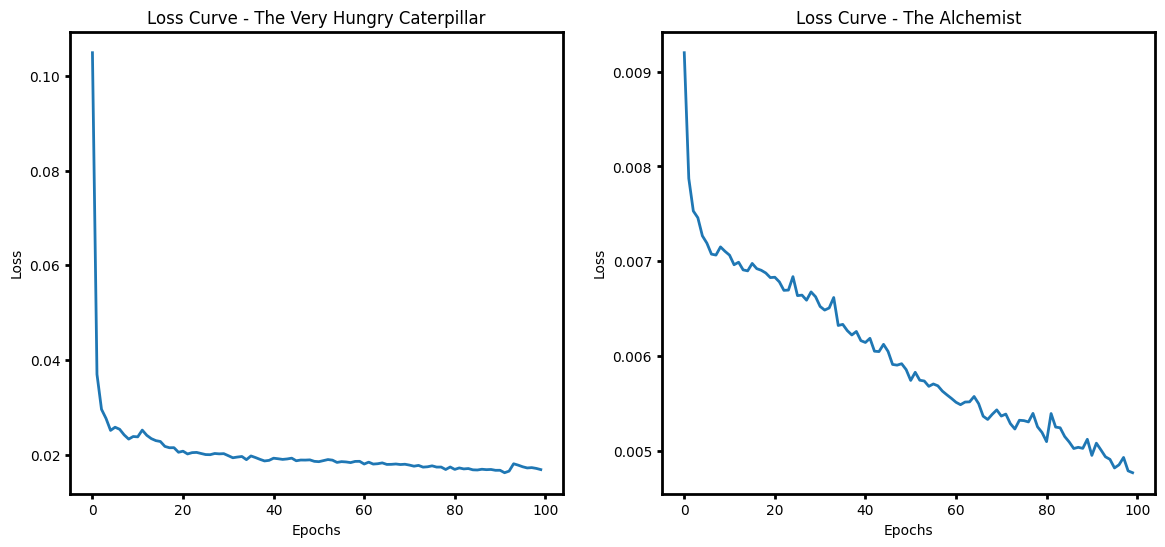

In [ ]:
# Visualise the loss curves
fig, axes = plt.subplots(1, 2, figsize=(14,6))
titles=['The Very Hungry Caterpillar','The Alchemist']
# Plot accuracy.
axes[0].plot(LSTM_multi_step_52_caterpillar_history.epoch,LSTM_multi_step_52_caterpillar_history.history['loss'],linewidth=2)
axes[1].plot(LSTM_multi_step_52_alchemist_history.epoch,LSTM_multi_step_52_alchemist_history.history['loss'],linewidth=2)

# titles
for i in range(2):
  axes[i].set_title(f"Loss Curve - {titles[i]}")
  axes[i].set_xlabel('Epochs')
  axes[i].set_ylabel('Loss')

for i in range(2):
 axes[i].tick_params(width=2)
 for axs in ['top','bottom','left','right']:
    axes[i].spines[axs].set_linewidth(2)

plt.savefig('LSTM_losscurves_first.svg')


The loss curve obtained for 'The Very Hungary Caterpillar' indicates that model is continuously improving albeit at increasingly slower rates. The decline in the end suggests it has not yet reached complete saturation but would benefit from early stopping. The loss curve obtained for 'The Alchemist' on the other hand suggests more epochs would prove useful even past the 100 point mark.

In [ ]:
# Make predictions
scaled_predictions_caterpillar_multi_52=LSTM_multi_step_52.predict(X_test_caterpillar_mult_52)
scaled_predictions_alchemist_multi_52=LSTM_multi_step_52.predict(X_test_alchemist_mult_52)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 174ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step


In [ ]:
# Inverse MinMax scaling
predictions_caterpillar_multi_52 = scaler.inverse_transform(scaled_predictions_caterpillar_multi_52.reshape(-1,1))
predictions_alchemist_multi_52 = scaler.inverse_transform(scaled_predictions_alchemist_multi_52.reshape(-1,1))

In [ ]:
# Calculate Errors
mae_caterpillar_multi_52 = mean_absolute_error(ts_caterpillar_test.values,predictions_caterpillar_multi_52.reshape(-1,1))
mape_caterpillar_multi_52 = mean_absolute_percentage_error(ts_caterpillar_test.values,predictions_caterpillar_multi_52.reshape(-1,1))
mae_alchemist_multi_52 = mean_absolute_error(ts_alchemist_test.values, predictions_alchemist_multi_52.reshape(-1,1))
mape_alchemist_multi_52 = mean_absolute_percentage_error(ts_alchemist_test.values, predictions_alchemist_multi_52.reshape(-1,1))

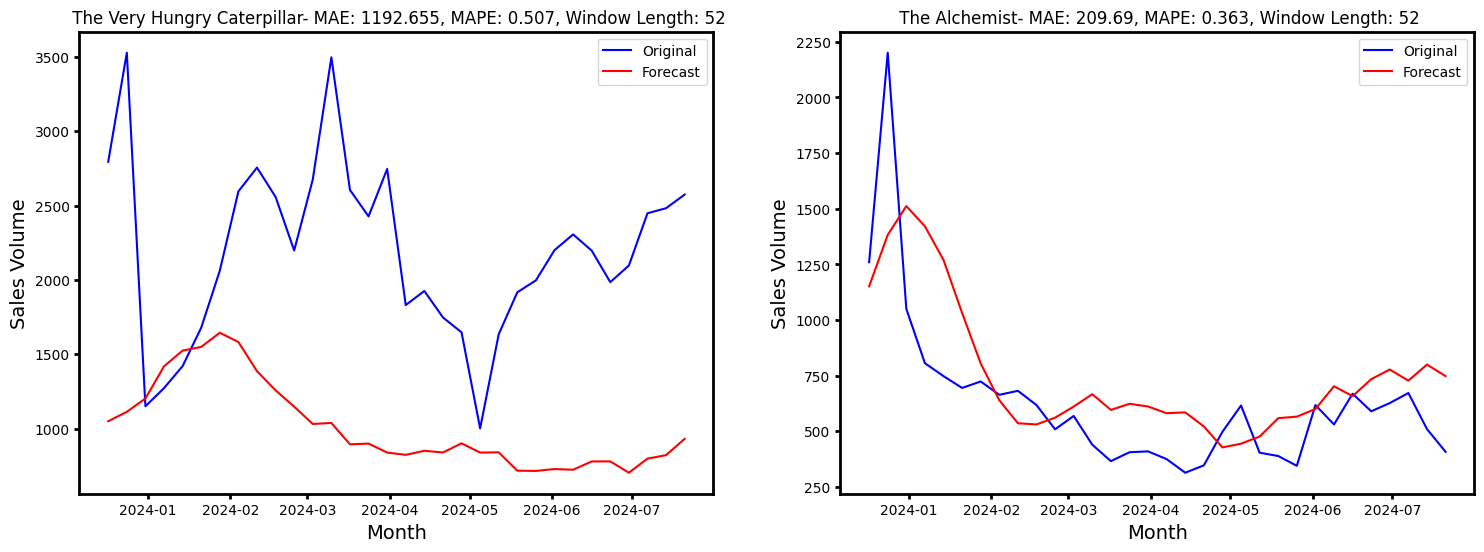

In [ ]:
# Visualise
fig, axes = plt.subplots(1, 2, figsize=(18,6))
# Plots
axes[0].plot(ts_caterpillar_test.index, ts_caterpillar_test.values, c='b', label='Original')
axes[0].plot(ts_caterpillar_test.index,predictions_caterpillar_multi_52.reshape(-1,1), c='r', label='Forecast')
axes[1].plot(ts_alchemist_test.index, ts_alchemist_test.values, c='b', label='Original')
axes[1].plot(ts_alchemist_test.index,predictions_alchemist_multi_52.reshape(-1,1), c='r', label='Forecast')
errors=[[mae_caterpillar_multi_52,mape_caterpillar_multi_52],[mae_alchemist_multi_52,mape_alchemist_multi_52]]
# titles
for i in range(2):
  axes[i].set_title(f" {titles[i]}- MAE: {round(errors[i][0],3)}, MAPE: {round(errors[i][1],3)}, Window Length: 52")
  axes[i].set_xlabel('Month',fontsize=14)
  axes[i].set_ylabel('Sales Volume',fontsize=14)
  axes[i].legend()

for i in range(2):
 axes[i].tick_params(width=2)
 for axs in ['top','bottom','left','right']:
    axes[i].spines[axs].set_linewidth(2)
# plt.savefig('First_LSTM_predictions.svg')


The preliminary forecast obtained for 'The Very Hungry Caterpillar' timeseries appears promising in terms of the broad trend. However there is a great mismatch between the actual and predicted sales volume levels. This is not the case for 'The Alchemist' timeseries where the same LSTM model applied yields higher accuracy and vaguely follows the trend pattern.

The observation likely stems from the differences in variance within the original range of the two timeseries datasets. Notably, 'The Very Hungry Caterpillar' encompasses a larger range in sales volume compared to ' The Alchemist'.

Thus, when the data is scaled to the [0,1] range the true (non-zero) minimum of the sales is given an artifical positive shift towards 1, which is more adversely affecting 'The Very Hungry Caterpillar' timeseries by reducing the perceived weight of the higher amplitude peaks.

**Experimenting with the lookback window length:**

In [ ]:
# Let's stream line the process to test other window lengths

def variant_window_multi_step_training(df_scaled,lockdown_periods,window,forecast,nodes,epochs,batch_size):


  # Create multi-step 3D sequences
  train_out,test_out= create_safe_multi_step_sequences(df_scaled,lockdown_periods,window,forecast)

  X_train, y_train = train_out[:-1], test_out[:-1]
  X_test,  y_test = train_out[-1:], test_out[-1:]

  print('Train:', X_train.shape, y_train.shape)
  print('Test:',  X_test.shape, y_test.shape)

  # Instantiate multi-step LSTM model
  LSTM_multi = create_multi_step_LSTM(nodes, window, forecast)
  # LSTM_multi.summary()

  # Train the Model
  LSTM_multi.fit(X_train,y_train, epochs, batch_size,verbose=0)
  # Make predictions
  y_pred_scaled = LSTM_multi.predict(X_test)

  # Return predictions
  return y_pred_scaled

In [ ]:
def calculate_errors(original_test_set, predictions):
  # Inverse MinMax scaling
  y_pred = scaler.inverse_transform(predictions.reshape(-1,1))

  # keeping scaling isolated in case interference is needed later

  # Calculate Errors
  MAE = mean_absolute_error(original_test_set.values,y_pred.reshape(-1,1))
  MAPE = mean_absolute_percentage_error(original_test_set.values,y_pred.reshape(-1,1))

  return y_pred, MAE, MAPE

In [ ]:
tf.keras.backend.clear_session()

In [ ]:
# Experiment with different window_lengths
caterpillar_mult_step_preds=[]
window_lengths=[52, 78, 104, 156]
for window in window_lengths:
  # clear cache
  tf.keras.backend.clear_session()
  # train model and make predictions, using higher number of nodes to address longer windows, and based on the loss curves double the epochs
  y_pred_scaled=variant_window_multi_step_training(df_caterpillar_scaled,lockdown_periods,window,forecast=32, nodes=256, epochs=100, batch_size=32)
  caterpillar_mult_step_preds.append(y_pred_scaled)


Train: (419, 52, 1) (419, 32, 1)
Test: (1, 52, 1) (1, 32, 1)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 165ms/step
Train: (367, 78, 1) (367, 32, 1)
Test: (1, 78, 1) (1, 32, 1)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step
Train: (315, 104, 1) (315, 32, 1)
Test: (1, 104, 1) (1, 32, 1)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step
Train: (241, 156, 1) (241, 32, 1)
Test: (1, 156, 1) (1, 32, 1)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step


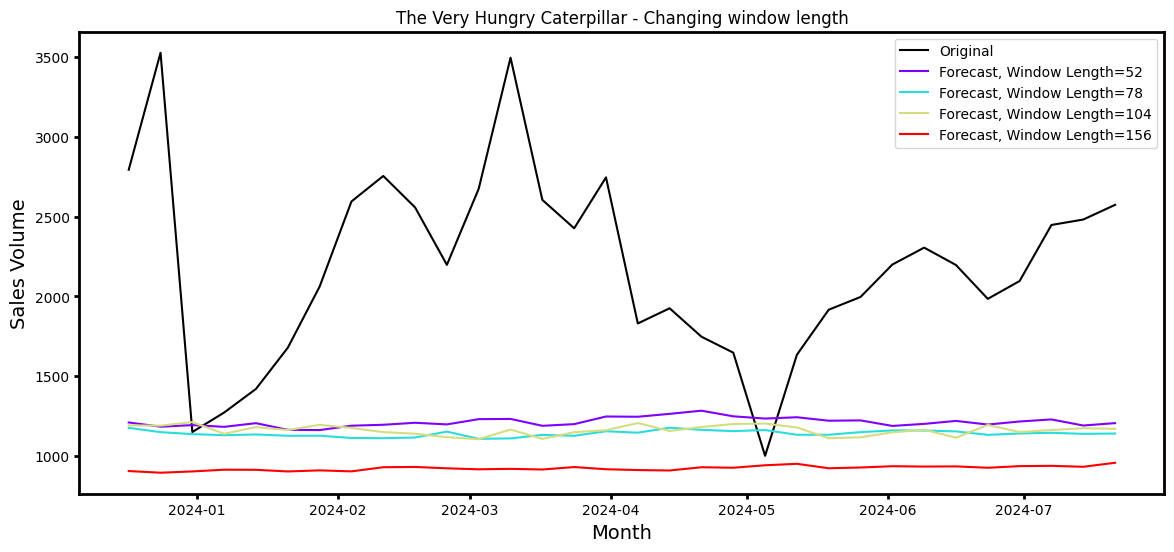

In [ ]:
# Now calculate errors and plot
table_caterpillar_mult_step_errors=pd.DataFrame(columns=['WindowLength', 'MAE', 'MAPE'])
window_lengths=[52,78,104,156]
colors = iter(cm.rainbow(np.linspace(0, 1, len(window_lengths))))
table_caterpillar_mult_step_errors['WindowLength']= window_lengths
fig=plt.figure(figsize=(14,6))
plt.plot(ts_caterpillar_test.index, ts_caterpillar_test.values, c='black', label='Original')
for i, window in enumerate(window_lengths):
  # Get predictions and errors
  y_pred, MAE, MAPE = calculate_errors(ts_caterpillar_test, caterpillar_mult_step_preds[i])
  # Plot
  plt.plot(ts_caterpillar_test.index, y_pred, c=next(colors), label=f"Forecast, Window Length={window}")
  # Store in table
  table_caterpillar_mult_step_errors.loc[i,'MAE']= round(MAE,3)
  table_caterpillar_mult_step_errors.loc[i,'MAPE']= round(MAPE,3)

plt.title("The Very Hungry Caterpillar - Changing window length")
plt.xlabel('Month',fontsize=14)
plt.ylabel('Sales Volume',fontsize=14)
plt.legend()

axes =fig.axes
for ax in axes:
    ax.tick_params(width=2)
    # Change spine (axis line) thickness
    for edge in ['top', 'bottom', 'left', 'right']:
        ax.spines[edge].set_linewidth(2)
# plt.savefig('Caterpillar_changing_window.svg')


The forecast plots produced for 4 different window lengths does not show a clear pattern, and appear to fit a base line to the test data. Thus, the window length producing the higher level is likely to return a lower MAPE score.

In [ ]:
table_caterpillar_mult_step_errors

,WindowLength,MAE,MAPE
0,52,990.064,0.414
1,78,1054.902,0.443
2,104,1040.102,0.437
3,156,1262.023,0.541


In [ ]:
# Repeat for the second title
# Experiment with different window_lengths
alchemist_mult_step_preds=[]
window_lengths=[52, 78, 104,156]
for window in window_lengths:
  # clear cache
  tf.keras.backend.clear_session()
  # train model and make predictions
  y_pred_scaled=variant_window_multi_step_training(df_alchemist_scaled,lockdown_periods,window,forecast=32, nodes=256, epochs=100, batch_size=32)
  alchemist_mult_step_preds.append(y_pred_scaled)


Train: (419, 52, 1) (419, 32, 1)
Test: (1, 52, 1) (1, 32, 1)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step
Train: (367, 78, 1) (367, 32, 1)
Test: (1, 78, 1) (1, 32, 1)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step
Train: (315, 104, 1) (315, 32, 1)
Test: (1, 104, 1) (1, 32, 1)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step
Train: (241, 156, 1) (241, 32, 1)
Test: (1, 156, 1) (1, 32, 1)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step


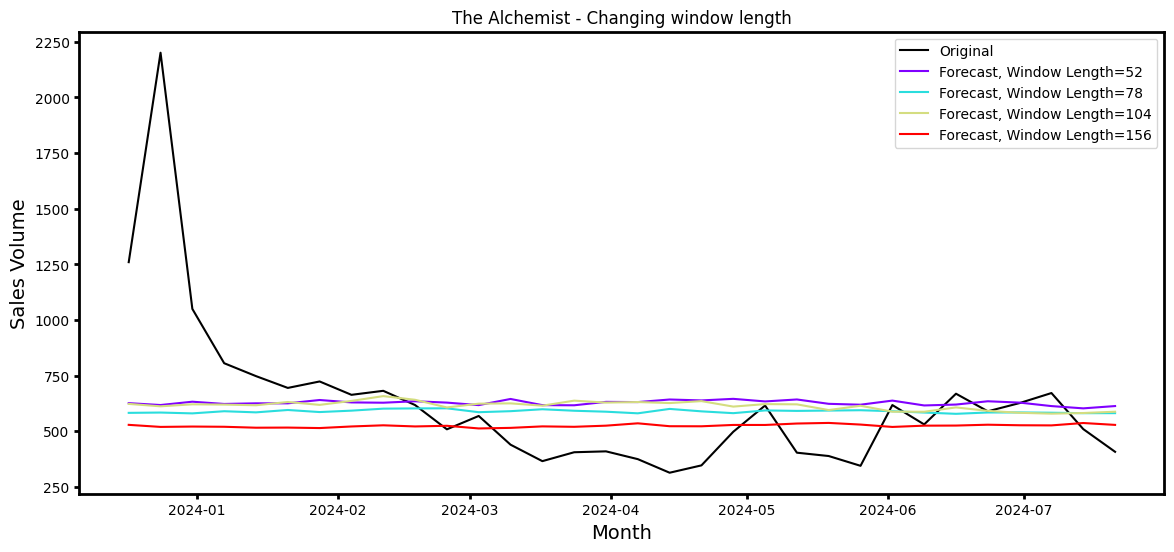

In [ ]:
# Now calculate errors and plot
table_alchemist_mult_step_errors=pd.DataFrame(columns=['WindowLength', 'MAE', 'MAPE'])
window_lengths=[52,78,104,156]
colors = iter(cm.rainbow(np.linspace(0, 1, len(window_lengths))))
table_alchemist_mult_step_errors['WindowLength']= window_lengths
fig=plt.figure(figsize=(14,6))
plt.plot(ts_alchemist_test.index, ts_alchemist_test.values, c='black', label='Original')
for i, window in enumerate(window_lengths):
  # Get predictions and errors
  y_pred, MAE, MAPE = calculate_errors(ts_alchemist_test, alchemist_mult_step_preds[i])
  # Plot
  plt.plot(ts_alchemist_test.index, y_pred, c=next(colors), label=f"Forecast, Window Length={window}")
  # Store in table
  table_alchemist_mult_step_errors.loc[i,'MAE']= round(MAE,3)
  table_alchemist_mult_step_errors.loc[i,'MAPE']= round(MAPE,3)

plt.title("The Alchemist - Changing window length")
plt.xlabel('Month',fontsize=14)
plt.ylabel('Sales Volume',fontsize=14)
plt.legend()

axes =fig.axes
for ax in axes:
    ax.tick_params(width=2)
    # Change spine (axis line) thickness
    for edge in ['top', 'bottom', 'left', 'right']:
        ax.spines[edge].set_linewidth(2)

# plt.savefig('Alchemist_changing_window.svg')


In [ ]:
table_alchemist_mult_step_errors

,WindowLength,MAE,MAPE
0,52,206.405,0.342
1,78,201.235,0.313
2,104,201.986,0.329
3,156,206.294,0.288


Based on the error scores, it can be seen that increasing the window length would prove useful for 'The Alchemist' timeseries. However, the approach can result in diminishing returns quite quickly due to the sequential dependency of the LSTM model: the longer window lengths can cause further destabilisation in the Covid-affected windows as well as requiring more hidden cell states to train. Thus, a conservative improvement using a window length of 78 time units will be aimed.

Let's re-generate the selected sequences for the two books, using the optimal window length-LSTM node combinations:

In [ ]:
# Now create the new 3D sequences
# Book 1 - already generated
# train_caterpillar_mult_52, test_caterpillar_mult_52 = create_safe_multi_step_sequences(df_caterpillar_scaled,lockdown_periods,lookback=52,horizon=32)
# Book 2
train_alchemist_mult_78, test_alchemist_mult_78 = create_safe_multi_step_sequences(df_alchemist_scaled,lockdown_periods,lookback=78,horizon=32)
X_train_alchemist_mult_78, y_train_alchemist_mult_78 = train_alchemist_mult_78[:-1], test_alchemist_mult_78[:-1]
X_test_alchemist_mult_78, y_test_alchemist_mult_78 = train_alchemist_mult_78[-1:], test_alchemist_mult_78[-1:]

In [ ]:
print('Book 1')
print('Train:', X_train_caterpillar_mult_52.shape,'==>', y_train_caterpillar_mult_52.shape)
print('Test:', X_test_caterpillar_mult_52.shape,'==>', y_test_caterpillar_mult_52.shape)
print('Book 2')
print('Train',X_train_alchemist_mult_78.shape,'==>', y_train_alchemist_mult_78.shape)
print('Test',X_test_alchemist_mult_78.shape,'==>', y_test_alchemist_mult_78.shape)

Book 1
Train: (419, 52, 1) ==> (419, 32, 1)
Test: (1, 52, 1) ==> (1, 32, 1)
Book 2
Train (367, 78, 1) ==> (367, 32, 1)
Test (1, 78, 1) ==> (1, 32, 1)


### 4.10 Apply KerasTuner, and perform hyperparameter tuning using the training data, for both books.


In [ ]:
# Make sure there is no overlap with hyperopt libraries
hp = HyperParameters()

In [ ]:
# Tuner function for 'The Very Hungry Caterpillar'
def tune_LSTM_model_caterpillar(hp, window, forecast):
    model = Sequential()

    # Tune the number of units in the first LSTM layer
    hp_nodes_1 = hp.Int('nodes_layer_1', min_value=64, max_value=256, step=32)
    model.add(LSTM(units=hp_nodes_1, return_sequences=True, input_shape=(window, 1)))

    # Tune the first dropout rate
    hp_dropout_1 = hp.Float('dropout_1', min_value=0.0, max_value=0.4, step=0.1)
    model.add(Dropout(rate=hp_dropout_1))

    # Tune the number of units in the second LSTM layer
    hp_nodes_2 = hp.Int('nodes_layer_2', min_value=64, max_value=256, step=32)
    model.add(LSTM(units=hp_nodes_2, return_sequences=False))

    # Tune the second dropout rate
    hp_dropout_2 = hp.Float('dropout_2', min_value=0.0, max_value=0.4, step=0.1)
    model.add(Dropout(rate=hp_dropout_2))

    # Forecast step (fixed size)
    # Activation function choices based on 0-1 range
    hp_activation=hp.Choice('dense_activation',values=['relu', 'sigmoid'])
    model.add(Dense(forecast, activation=hp_activation))


    # Tune the learning rate for the Adam optimizer
    hp_learning_rate = hp.Choice('learning_rate', values=[1e-2,5e-03,1e-3])

    model.compile(
        loss='mean_squared_error',
        optimizer=Adam(learning_rate=hp_learning_rate),
        metrics=['mean_squared_error']
    )

    return model

In [ ]:
# Use a different range for 'The Alchemist'
def tune_LSTM_model_alchemist(hp, window, forecast):
    model = Sequential()

    # Tune the number of units in the first LSTM layer
    hp_nodes_1 = hp.Int('nodes_layer_1', min_value=96, max_value=288, step=32)
    model.add(LSTM(units=hp_nodes_1, return_sequences=True, input_shape=(window, 1)))

    # Tune the first dropout rate
    hp_dropout_1 = hp.Float('dropout_1', min_value=0.0, max_value=0.4, step=0.1)
    model.add(Dropout(rate=hp_dropout_1))

    # Tune the number of units in the second LSTM layer
    hp_nodes_2 = hp.Int('nodes_layer_2', min_value=96, max_value=288, step=32)
    model.add(LSTM(units=hp_nodes_2, return_sequences=False))

    # Tune the second dropout rate
    hp_dropout_2 = hp.Float('dropout_2', min_value=0.0, max_value=0.4, step=0.1)
    model.add(Dropout(rate=hp_dropout_2))

    # Forecast step (fixed size)
    # Activation function choices based on 0-1 range
    hp_activation=hp.Choice('dense_activation',values=['relu', 'sigmoid'])
    model.add(Dense(forecast, activation=hp_activation))


    # Tune the learning rate for the Adam optimizer
    hp_learning_rate = hp.Choice('learning_rate', values=[1e-2, 1e-3])

    model.compile(
        loss='mean_squared_error',
        optimizer=Adam(learning_rate=hp_learning_rate),
        metrics=['mean_squared_error']
    )

    return model

In [ ]:
# Add Early Stopping
early_stopping = EarlyStopping(
    monitor='mean_squared_error',
    patience=5,
    mode='min',
    restore_best_weights=True # Keeps the best model weights, not the overfitted final epoch
)

**BOOK 1: 'The Very Hungry Caterpillar'**

In [ ]:
# Instantiate the tuner with RandomSearch
tf.keras.backend.clear_session()
set_random_seed(42)
tuner_lstm_caterpillar= RandomSearch(
    hypermodel=lambda hp: tune_LSTM_model_caterpillar(hp,window=52,forecast=32),
    objective='mean_squared_error',
    max_trials=30,            # Total model variations to test
    executions_per_trial=1    # How many times to train each variation to average out noise
)

In [ ]:
# Perform the Random Search for the Caterpillar dataset
tuner_lstm_caterpillar.search(
    X_train_caterpillar_mult_52, y_train_caterpillar_mult_52,
    epochs=100,
    batch_size=32,
    verbose=0,
    #callbacks=[early_stopping]
)

In [ ]:
best_lstm_caterpillar = tuner_lstm_caterpillar.get_best_hyperparameters(num_trials=1)[0]
best_lstm_caterpillar.values

{'nodes_layer_1': 192,
 'dropout_1': 0.4,
 'nodes_layer_2': 160,
 'dropout_2': 0.0,
 'dense_activation': 'relu',
 'learning_rate': 0.01}

**BOOK2: 'The Alchemist'**

In [ ]:
# Instantiate the tuner with RandomSearch
tf.keras.backend.clear_session()
set_random_seed(42)
tuner_lstm_alchemist = RandomSearch(
    hypermodel=lambda hp: tune_LSTM_model_alchemist(hp,window=78,forecast=32),
    objective='mean_squared_error',
    max_trials=30,            # Total model variations to test
    #executions_per_trial=1,   # How many times to train each variation to average out noise
)

In [ ]:
# Perform the Random Search for the Alchemist dataset
tuner_lstm_alchemist.search(
    X_train_alchemist_mult_78, y_train_alchemist_mult_78,
    epochs=100,
    batch_size=32,
    verbose=0,
    # callbacks=[early_stopping]
)

In [ ]:
best_lstm_alchemist = tuner_lstm_alchemist.get_best_hyperparameters(num_trials=1)[0]
best_lstm_alchemist.values

{'nodes_layer_1': 160,
 'dropout_1': 0.30000000000000004,
 'nodes_layer_2': 160,
 'dropout_2': 0.0,
 'dense_activation': 'relu',
 'learning_rate': 0.01}

In [ ]:
# Function to create the best model for Book 1

def create_tuned_LSTM_caterpillar(window,forecast):
    model = Sequential()

    model.add(LSTM(units=192, return_sequences=True, input_shape=(window, 1))),

    model.add(Dropout(0.4)),

    model.add(LSTM(units=160, return_sequences=False)),

    # model.add(Dropout(0.1)),

    # Forecast step
    model.add(Dense(forecast,activation='relu'))

    adam_optimizer = Adam(learning_rate=0.01)
    model.compile(loss='mean_squared_error', optimizer=adam_optimizer)

    return model


In [ ]:
# Function to create the best model for Book 2

def create_tuned_LSTM_alchemist(window,forecast):
    model = Sequential()

    model.add(LSTM(units=160, return_sequences=True, input_shape=(window, 1))),

    model.add(Dropout(0.3)),

    model.add(LSTM(units=160, return_sequences=False)),

    # model.add(Dropout(0.2)),

    # Forecast step
    model.add(Dense(forecast, activation='relu'))

    adam_optimizer = Adam(learning_rate=0.01)
    model.compile(loss='mean_squared_error', optimizer=adam_optimizer)

    return model

In [ ]:
# Instantiate the tuned model for book 1
LSTM_tuned_caterpillar = create_tuned_LSTM_caterpillar(52, 32)
LSTM_tuned_caterpillar.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 52, 192)        │       148,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 52, 192)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 160)            │       225,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         5,152 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 380,064 (1.45 MB)

 Trainable params: 380,064 (1.45 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Instantiate the tuned model for book 2
LSTM_tuned_alchemist = create_tuned_LSTM_alchemist(78, 32)
LSTM_tuned_alchemist.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 78, 160)        │       103,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 78, 160)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 160)            │       205,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         5,152 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 314,272 (1.20 MB)

 Trainable params: 314,272 (1.20 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Train the model for book 1
LSTM_tuned_caterpillar_history = LSTM_tuned_caterpillar.fit(X_train_caterpillar_mult_52,y_train_caterpillar_mult_52, epochs=200, batch_size=32,callbacks=[early_stopping],verbose=0)

In [ ]:
# Train the model for book 2
LSTM_tuned_alchemist_history = LSTM_tuned_alchemist.fit(X_train_alchemist_mult_78,y_train_alchemist_mult_78,epochs=200,batch_size=32, callbacks=[early_stopping],verbose=0)

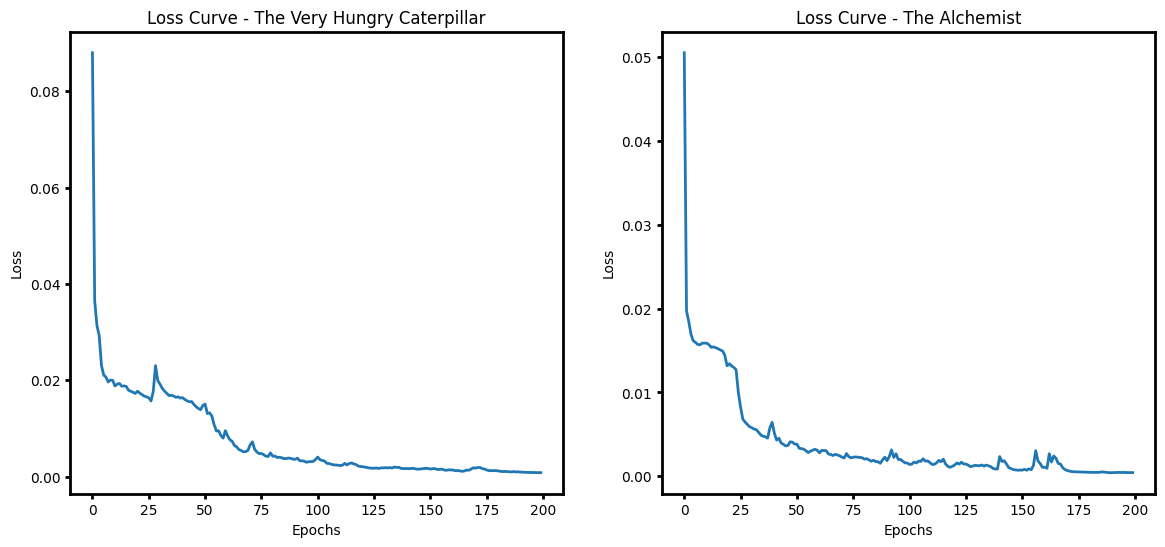

In [ ]:
# Loss Curves
# Visualise the loss curves
fig, axes = plt.subplots(1, 2, figsize=(14,6))
# Plot accuracy.
axes[0].plot(LSTM_tuned_caterpillar_history.epoch,LSTM_tuned_caterpillar_history.history['loss'],linewidth=2)
axes[1].plot(LSTM_tuned_alchemist_history.epoch,LSTM_tuned_alchemist_history.history['loss'],linewidth=2)

# titles
for i in range(2):
  axes[i].set_title(f"Loss Curve - {titles[i]}")
  axes[i].set_xlabel('Epochs')
  axes[i].set_ylabel('Loss')

axes =fig.axes
for ax in axes:
    ax.tick_params(width=2)
    # Change spine (axis line) thickness
    for edge in ['top', 'bottom', 'left', 'right']:
        ax.spines[edge].set_linewidth(2)


# plt.savefig('LSTM_losscurves_final.svg')


Post hyperparameter tuning, the loss curves present with more fluctions but ultimately start settling after 100 epochs.

In [ ]:
# Predict the 32-week forecast - book 1
scaled_predictions_caterpillar_tuned=LSTM_tuned_caterpillar.predict(X_test_caterpillar_mult_52)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step


In [ ]:
# Predict the 32-week forecast- book 2
scaled_predictions_alchemist_tuned=LSTM_tuned_alchemist.predict(X_test_alchemist_mult_78)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 174ms/step


In [ ]:
# Re-scale and derive errors
y_pred_caterpillar_tuned, MAE_caterpillar_tuned, MAPE_caterpillar_tuned = calculate_errors(ts_caterpillar_test,scaled_predictions_caterpillar_tuned)
y_pred_alchemist_tuned, MAE_alchemist_tuned, MAPE_alchemist_tuned = calculate_errors(ts_alchemist_test,scaled_predictions_alchemist_tuned)


In [ ]:
# Derive the 95% confidence interval for future forecast
def build_CI(y_test,predictions):
  residuals = y_test.values- predictions
  sigma = np.std(residuals)  # standard deviation of residuals

# Prediction intervals
  int_lower = predictions - 1.96*sigma
  int_upper = predictions + 1.96*sigma
  forecast_int={"lower": int_lower,
                "upper": int_upper}
  return forecast_int

In [ ]:
lstm_CI_caterpillar = build_CI(ts_caterpillar_test, y_pred_caterpillar_tuned)
lstm_CI_alchemist = build_CI(ts_alchemist_test, y_pred_alchemist_tuned)

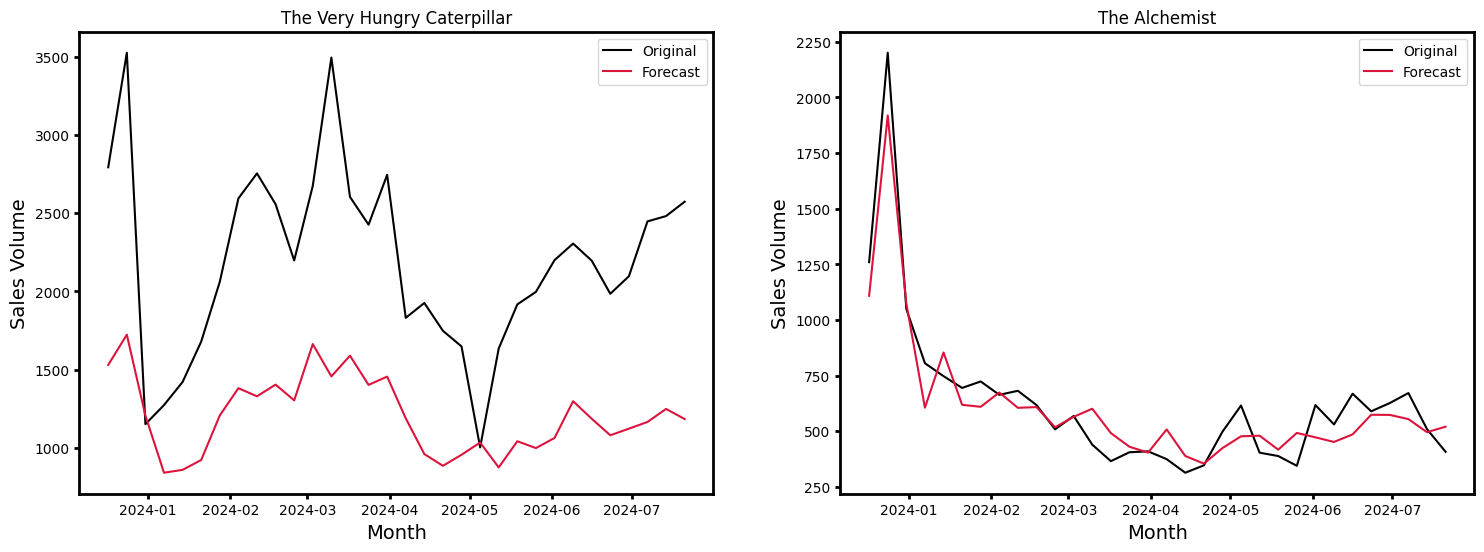

In [ ]:
# Preliminary checks:
fig, axes = plt.subplots(1,2, figsize=(18,6))

axes[0].plot(ts_caterpillar_test.index, ts_caterpillar_test.values, c='black', label='Original')
axes[0].plot(ts_caterpillar_test.index, y_pred_caterpillar_tuned, c='crimson', label='Forecast')

axes[1].plot(ts_alchemist_test.index, ts_alchemist_test.values, c='black', label='Original')
axes[1].plot(ts_alchemist_test.index, y_pred_alchemist_tuned, c='crimson', label='Forecast')


# titles
for i in range(2):
  axes[i].set_title(f"{titles[i]}")
  axes[i].set_xlabel('Month',fontsize=14)
  axes[i].set_ylabel('Sales Volume',fontsize=14)
  axes[i].legend()

for i in range(2):
 axes[i].tick_params(width=2)
 for axs in ['top','bottom','left','right']:
    axes[i].spines[axs].set_linewidth(2)

 plt.savefig('Post_tuning_LSTM_checks.svg')



In [ ]:
# Print model name and resulting errors
print('\033[1m',titles[0], '\n', '-'*40,'\n')
print('\033[0m',f"Mean Absolute Error: {MAE_caterpillar_tuned}", '\n')
print('\033[0m',f"Mean Absolute Percentage Error: {MAPE_caterpillar_tuned}", '\n')
print('\033[1m',titles[1], '\n', '-'*40,'\n')
print('\033[0m',f"Mean Absolute Error: {MAE_alchemist_tuned}", '\n')
print('\033[0m',f"Mean Absolute Percentage Error: {MAPE_alchemist_tuned}", '\n')



 The Very Hungry Caterpillar 
 ---------------------------------------- 

 Mean Absolute Error: 986.8701171875 

 Mean Absolute Percentage Error: 0.4318375289440155 

 The Alchemist 
 ---------------------------------------- 

 Mean Absolute Error: 86.88632202148438 

 Mean Absolute Percentage Error: 0.1502579152584076 



### 4.11 Use the best model to predict the final 32 weeks of data for both books.


There are obvious improvements in 'The Very Hungry Caterpillar' forecast based both on the error metrics and the visual comparison to the original test set. In the case of 'The Alchemist' the improvement is not as clear compared to the pre-tuning plots, but a smaller MAPE is achieved.

Thus, in both cases the tuned models with the specified window-lengths will be considered the best models.


### 4.12 Plot the original data along with the predictions.


### 4.13 Display the MAE and MAPE.

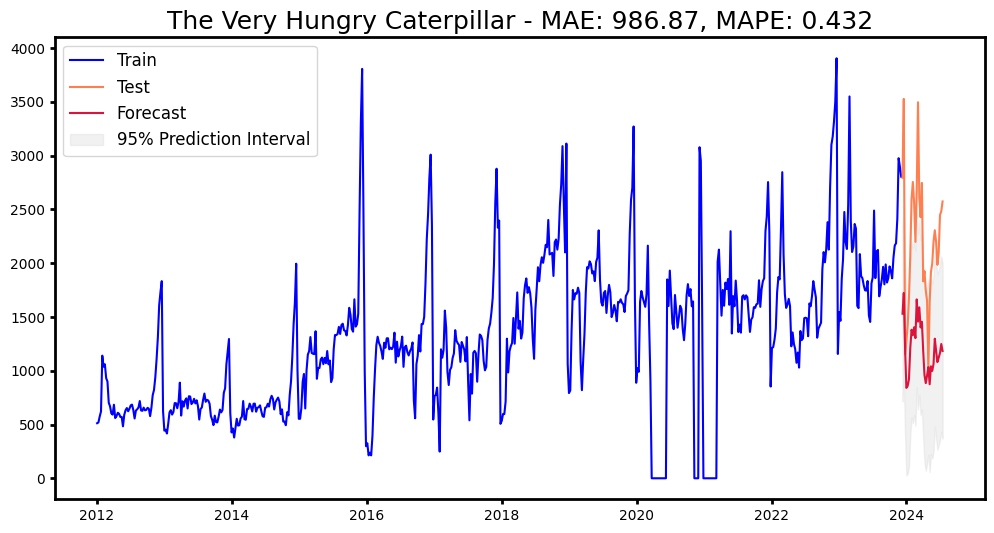

In [ ]:
# Book 1
plot_results('The Very Hungry Caterpillar',
                  ts_caterpillar_train,
                  ts_caterpillar_test,
                  y_pred_caterpillar_tuned,
                  MAE_caterpillar_tuned,
                  MAPE_caterpillar_tuned,
                  lstm_CI_caterpillar,'crimson','LSTM_caterpillar_final.svg')

While the presence of zero-valued records alter the input scale pre-training, during training the use of 'sigmoid' and 'tanh' functions across various gates of the LSTM architecture is also altering the range. As a result, the long-term memory likely cannot keep up.

The confidence interval also ends up being very large reflecting the magnitude of the error itself.

That said, the pattern does not appear random, and the rises and falls in the actual timeseries is somewhat matched.

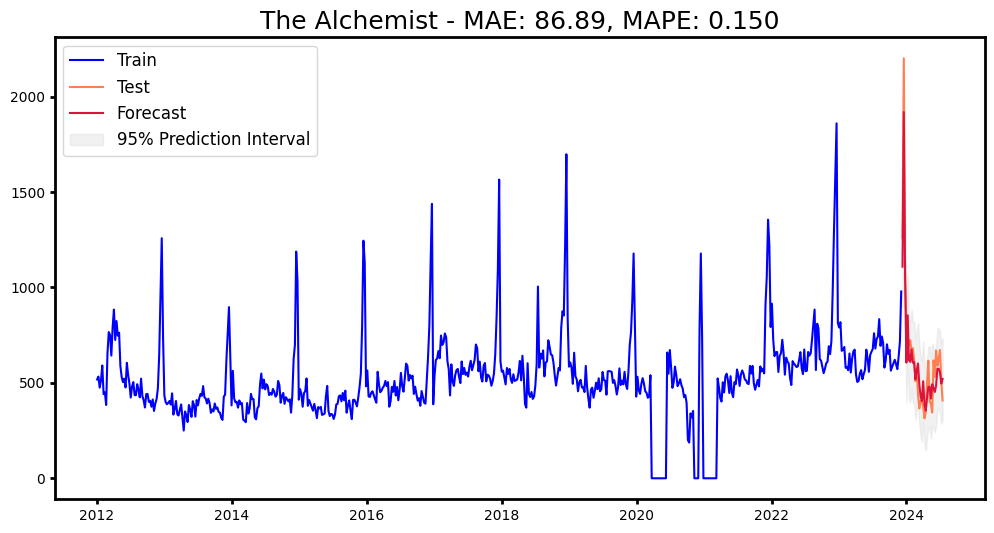

In [ ]:
# Book 2
plot_results('The Alchemist',
                  ts_alchemist_train,
                  ts_alchemist_test,
                  y_pred_alchemist_tuned,
                  MAE_alchemist_tuned,
                  MAPE_alchemist_tuned,
                  lstm_CI_alchemist,'crimson','LSTM_alchemist_final.svg')

In the case of 'The Alchemist' time series, the amplitude of the seasonal peak produced using the LSTM forecast is still closer to the actual value but the error is not as large as in the case of 'The Very Hungry Caterpillar'. As a result, the confidence interval is more balanced yet still outside the range of the true peak height.

Since the variance in 'The Alchemist' sales volume data is lower while following simpler trends, the LSTM architecture does not suffer the same level of memory distortion observed in the 'The Very Hungry Caterpillar' case.

## 5.Hybrid Models

### 5.1 Apply a hybrid model of SARIMA and LSTM in sequential combination wherein the residuals from SARIMA will be forecasted using LSTM. The final prediction will be the sum of the predictions from SARIMA and LSTM. The LSTM will be trained on the residuals obtained during the training of the SARIMA model. The forecast horizon will be the final 32 weeks. Use KerasTuner to get the best model. Plot the results. Display the MAE and MAPE, and comment on the results.

**General Strategy:**

* Convert the residuals from the SARIMA model fitted earlier (section $3.6$) into 3D sequences.

* Apply the optimal window length and hence, multi-step splitting approach determined in section $4.9$.

* Train the residual timeseries data using the tuned LSTM model obtained per book in section $4.11$.

* Visually inspect the results.

* Perform hyperparameter tuning for the residuals.

* Determine the best-model, re-train, re-fit and examine performance.




In [ ]:
# Get the arima predictions
y_pred_arima_caterpillar=arima_forecast_caterpillar.predicted_mean.values
y_pred_arima_alchemist=arima_forecast_alchemist.predicted_mean.values

**Prepare the two sets of residual data:**

In [ ]:
# Get the last 32 weeks
residuals_test_caterpillar=(ts_caterpillar_test-y_pred_arima_caterpillar.reshape(-1,1)).values
residuals_test_alchemist=(ts_alchemist_test-y_pred_arima_alchemist.reshape(-1,1)).values

In [ ]:
# Concatenate
residuals_all_caterpillar = np.concatenate((arima_resid_caterpillar.values, residuals_test_caterpillar.flatten()),axis=0)
residuals_all_alchemist= np.concatenate((arima_resid_alchemist.values, residuals_test_alchemist.flatten()),axis=0)


In [ ]:
# New Scaler
resid_scaler= MinMaxScaler(feature_range=(0, 1))

# Create dataframes with only the scaled training data
# Book 1
resid_caterpillar_scaled = pd.DataFrame(index=book_data_caterpillar.index)
resid_caterpillar_scaled['Scaled'] = resid_scaler.fit_transform(residuals_all_caterpillar.reshape(-1,1))
# Book 2
resid_alchemist_scaled = pd.DataFrame(index=book_data_alchemist.index)
resid_alchemist_scaled['Scaled'] = resid_scaler.fit_transform(residuals_all_alchemist.reshape(-1,1))

# Form 3D multi-step rolling window sequences
# Book 1
train_caterpillar_resid, test_caterpillar_resid = create_safe_multi_step_sequences(resid_caterpillar_scaled,lockdown_periods,lookback=52,horizon=32)
# Book 2
train_alchemist_resid, test_alchemist_resid = create_safe_multi_step_sequences(resid_alchemist_scaled,lockdown_periods,lookback=78,horizon=32)


In [ ]:
# Reserve last training sequences for testing
# Book 1
X_train_caterpillar_resid, y_train_caterpillar_resid = train_caterpillar_resid[:-1], test_caterpillar_resid [:-1]
X_test_caterpillar_resid, y_test_caterpillar_resid = train_caterpillar_resid[-1:], test_caterpillar_resid [-1:]
# Book 2
X_train_alchemist_resid, y_train_alchemist_resid = train_alchemist_resid[:-1], test_alchemist_resid[:-1]
X_test_alchemist_resid, y_test_alchemist_resid = train_alchemist_resid[-1:], test_alchemist_resid[-1:]

In [ ]:
# Check
print('Book 1')
print('Train:', X_train_caterpillar_resid.shape,'==>', y_train_caterpillar_resid.shape)
print('Test:', X_test_caterpillar_resid.shape,'==>', y_test_caterpillar_resid.shape)
print('Book 2')
print('Train',X_train_alchemist_resid.shape,'==>', y_train_alchemist_resid.shape)
print('Test',X_test_alchemist_resid.shape,'==>', y_test_alchemist_resid.shape)


Book 1
Train: (419, 52, 1) ==> (419, 32, 1)
Test: (1, 52, 1) ==> (1, 32, 1)
Book 2
Train (367, 78, 1) ==> (367, 32, 1)
Test (1, 78, 1) ==> (1, 32, 1)


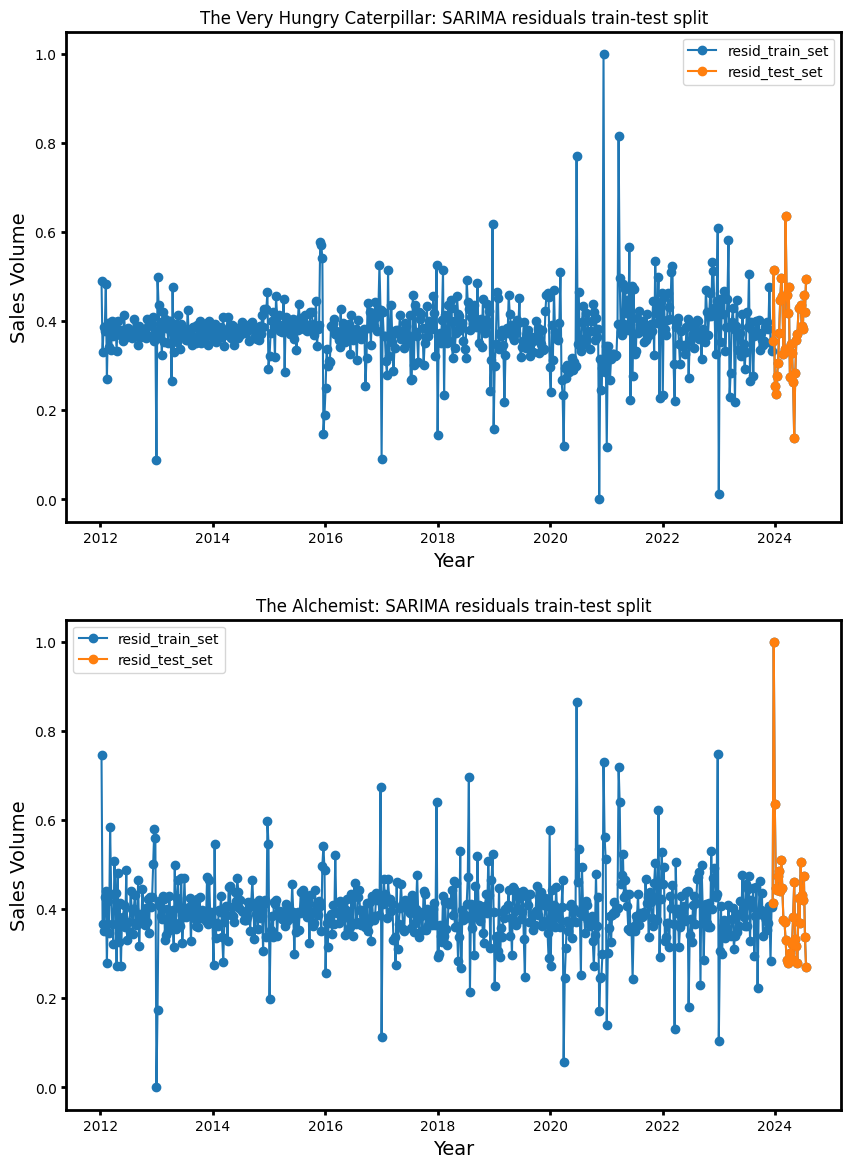

In [ ]:
# Visualise the residual train-test split
fig, axes = plt.subplots(2, 1,figsize=(10,14))


axes[0].plot(resid_caterpillar_scaled.index,resid_caterpillar_scaled.values, '-o', label='resid_train_set')
axes[0].plot(ts_caterpillar_test.index,y_test_caterpillar_resid.flatten(),'-o',label='resid_test_set')
axes[0].legend()
axes[1].plot(resid_alchemist_scaled.index,resid_alchemist_scaled.values, '-o',label='resid_train_set')
axes[1].plot(ts_alchemist_test.index,y_test_alchemist_resid.flatten(),'-o',label='resid_test_set')
axes[1].legend()

# titles and labels
for i in range(2):
  axes[i].set_title(f"{titles[i]}: SARIMA residuals train-test split")
  axes[i].set_xlabel('Year',fontsize=14)
  axes[i].set_ylabel('Sales Volume',fontsize=14)


axes =fig.axes
for ax in axes:
    ax.tick_params(width=2)
    # Change spine (axis line) thickness
    for edge in ['top', 'bottom', 'left', 'right']:
        ax.spines[edge].set_linewidth(2)

plt.savefig('SARIMA_resids.svg')
plt.show()


In [ ]:
set_random_seed(42)
tf.keras.backend.clear_session()

In [ ]:
# Train the model for book 1
LSTM__caterpillar_resid_history = LSTM_tuned_caterpillar.fit(X_train_caterpillar_resid,y_train_caterpillar_resid, epochs=200, batch_size=32,callbacks=[early_stopping],verbose=0)

In [ ]:
# Train the model for book 2
LSTM__alchemist_resid_history = LSTM_tuned_alchemist.fit(X_train_alchemist_resid,y_train_alchemist_resid, epochs=200, batch_size=32,callbacks=[early_stopping],verbose=0)

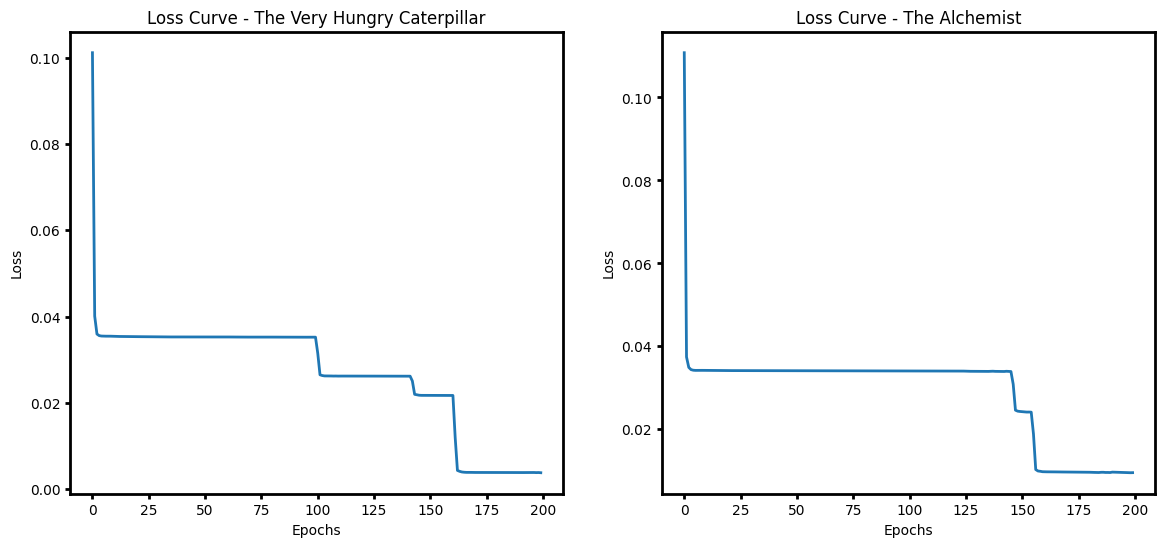

In [ ]:
# Loss Curves
# Visualise the loss curves
fig, axes = plt.subplots(1, 2, figsize=(14,6))
# Plot accuracy.
axes[0].plot(LSTM__caterpillar_resid_history.epoch,LSTM__caterpillar_resid_history.history['loss'],linewidth=2)
axes[1].plot(LSTM__alchemist_resid_history.epoch,LSTM__alchemist_resid_history.history['loss'],linewidth=2)

# titles
for i in range(2):
  axes[i].set_title(f"Loss Curve - {titles[i]}")
  axes[i].set_xlabel('Epochs')
  axes[i].set_ylabel('Loss')

axes =fig.axes
for ax in axes:
    ax.tick_params(width=2)
    # Change spine (axis line) thickness
    for edge in ['top', 'bottom', 'left', 'right']:
        ax.spines[edge].set_linewidth(2)

# plt.savefig('LSTM_losscurves_resid_first.svg')


During training, the two data sets present with a stepped decline in the mean-squared-error (loss metric).

In [ ]:
# Predict the 32-week residual forecast - book 1
scaled_predictions_caterpillar_resid=LSTM_tuned_caterpillar.predict(X_test_caterpillar_resid)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step


In [ ]:
# Predict the 32-week residual forecast - book 2
scaled_predictions_alchemist_resid=LSTM_tuned_alchemist.predict(X_test_alchemist_resid)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step


In [ ]:
def calculate_errors_resid(original_test_set, predictions):
  # Inverse MinMax scaling
  y_pred = resid_scaler.inverse_transform(predictions.reshape(-1,1))

  # keeping scaling isolated in case interference is needed later

  # Calculate Errors
  MAE = mean_absolute_error(original_test_set,y_pred.reshape(-1,1))
  MAPE = mean_absolute_percentage_error(original_test_set,y_pred.reshape(-1,1))

  return y_pred, MAE, MAPE

In [ ]:
# Re-scale and derive errors
y_pred_caterpillar_resid, MAE_caterpillar_resid, MAPE_caterpillar_resid = calculate_errors_resid(residuals_test_caterpillar,scaled_predictions_caterpillar_resid)
y_pred_alchemist_resid, MAE_alchemist_resid, MAPE_alchemist_resid = calculate_errors_resid(residuals_test_alchemist,scaled_predictions_alchemist_resid)

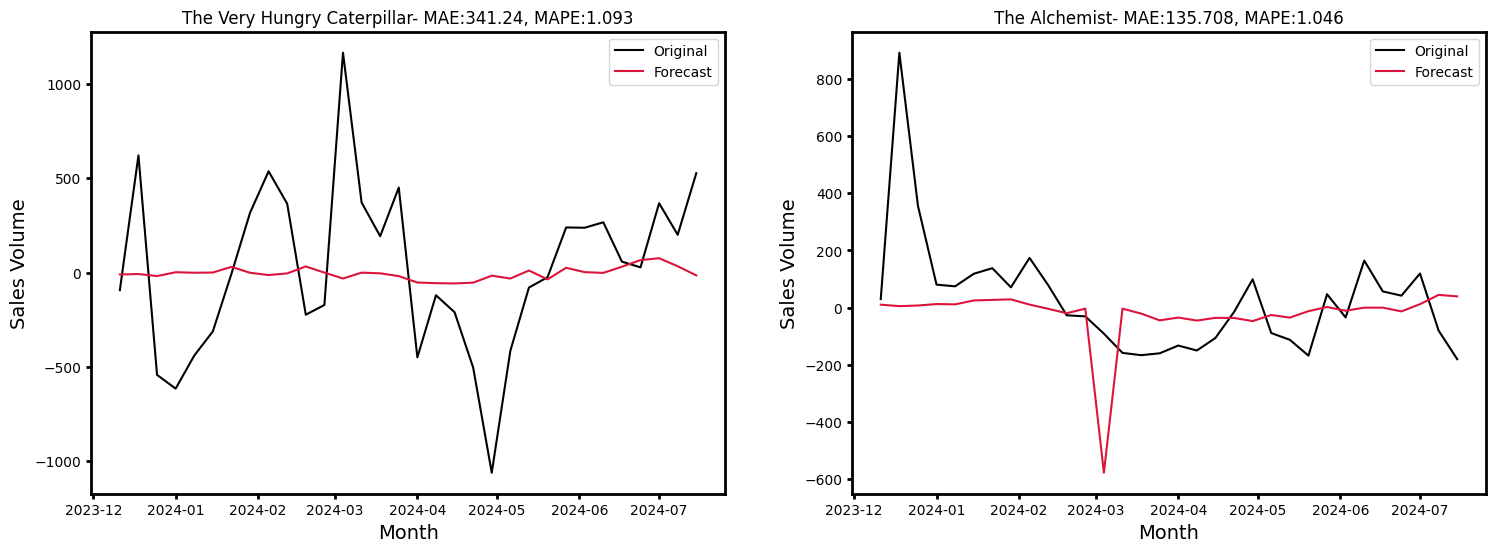

In [ ]:
# Preliminary checks:
fig, axes = plt.subplots(1,2, figsize=(18,6))

axes[0].plot(ts_caterpillar_test.index.to_timestamp(), residuals_test_caterpillar, c='black', label='Original')
axes[0].plot(ts_caterpillar_test.index.to_timestamp(), y_pred_caterpillar_resid, c='crimson', label='Forecast')

axes[1].plot(ts_alchemist_test.index.to_timestamp(), residuals_test_alchemist, c='black', label='Original')
axes[1].plot(ts_alchemist_test.index.to_timestamp(), y_pred_alchemist_resid, c='crimson', label='Forecast')

errors_list_init=[[MAE_caterpillar_resid, MAPE_caterpillar_resid],[MAE_alchemist_resid, MAPE_alchemist_resid]]

# titles
for i in range(2):
  axes[i].set_title(f"{titles[i]}- MAE:{round(errors_list_init[i][0],3)}, MAPE:{round(errors_list_init[i][1],3)}")
  axes[i].set_xlabel('Month',fontsize=14)
  axes[i].set_ylabel('Sales Volume',fontsize=14)
  axes[i].legend()

for i in range(2):
 axes[i].tick_params(width=2)
 for axs in ['top','bottom','left','right']:
    axes[i].spines[axs].set_linewidth(2)

 plt.savefig('Residual_LSTM_checks.svg')

As it is more difficult to fit unstructured data, the models return a very large MAPE value for both sets of residuals. In the case of 'The Very Hungry Caterpillar', a nearly straight line is fit around the mean. In the case of 'The Alchemist', the straight line is distored by a large dip around 2024-03.

**BOOK 1: Hyperparameter Tuning 'The Very Hungry Caterpillar' Residuals**

In [ ]:
# Instantiate the tuner with RandomSearch
tf.keras.backend.clear_session()
set_random_seed(42)
tuner_lstm_caterpillar= RandomSearch(
    hypermodel=lambda hp: tune_LSTM_model_caterpillar(hp,window=52,forecast=32),
    objective='mean_squared_error',
    max_trials=20,            # Total model variations to test
    executions_per_trial=1    # How many times to train each variation to average out noise
)

In [ ]:
# Perform the Random Search for the Caterpillar dataset
tuner_lstm_caterpillar.search(
    X_train_caterpillar_resid,y_train_caterpillar_resid,
    epochs=100,
    batch_size=32,
    verbose=0,
    #callbacks=[early_stopping]
)

In [ ]:
# Get the pest parameters
tuner_lstm_caterpillar.get_best_hyperparameters(num_trials=1)[0].values

{'nodes_layer_1': 256,
 'dropout_1': 0.1,
 'nodes_layer_2': 96,
 'dropout_2': 0.0,
 'dense_activation': 'sigmoid',
 'learning_rate': 0.01}

In [ ]:
# Function to create the best model for Book 1

def create_tuned_LSTM_caterpillar_resid(window,forecast):
    model = Sequential()

    model.add(LSTM(units=256, return_sequences=True, input_shape=(window, 1))),

    model.add(Dropout(0.1)),

    model.add(LSTM(units=96, return_sequences=False)),

    # model.add(Dropout(0.1)),

    # Forecast step
    model.add(Dense(forecast,activation='sigmoid'))

    adam_optimizer = Adam(learning_rate=0.01)
    model.compile(loss='mean_squared_error', optimizer=adam_optimizer)

    return model

In [ ]:
# Instantiate the tuned model for book 1
tf.keras.backend.clear_session()
set_random_seed(42)
LSTM_tuned_caterpillar_resid = create_tuned_LSTM_caterpillar_resid(52, 32)
LSTM_tuned_caterpillar_resid.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 52, 256)        │       264,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 52, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 96)             │       135,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         3,104 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 402,848 (1.54 MB)

 Trainable params: 402,848 (1.54 MB)

 Non-trainable params: 0 (0.00 B)

**BOOK 2: Hyperparameter Tuning 'The Alchemist' Residuals**

In [ ]:
# Instantiate the tuner with RandomSearch
tf.keras.backend.clear_session()
set_random_seed(42)
tuner_lstm_alchemist = RandomSearch(
    hypermodel=lambda hp: tune_LSTM_model_alchemist(hp,window=78,forecast=32),
    objective='mean_squared_error',
    max_trials=20,            # Total model variations to test
    #executions_per_trial=1,   # How many times to train each variation to average out noise
)

In [ ]:
# Perform the Random Search for the Caterpillar dataset
tuner_lstm_alchemist.search(
    X_train_alchemist_resid,y_train_alchemist_resid,
    epochs=100,
    batch_size=32,
    verbose=0,
    #callbacks=[early_stopping]
)

In [ ]:
# Get the best parameters
tuner_lstm_alchemist.get_best_hyperparameters(num_trials=1)[0].values

{'nodes_layer_1': 256,
 'dropout_1': 0.4,
 'nodes_layer_2': 160,
 'dropout_2': 0.0,
 'dense_activation': 'sigmoid',
 'learning_rate': 0.001}

In [ ]:
# Function to create the best model for Book 2

def create_tuned_LSTM_alchemist_resid(window,forecast):
    model = Sequential()

    model.add(LSTM(units=160, return_sequences=True, input_shape=(window, 1))),

    # model.add(Dropout(0.2)),

    model.add(LSTM(units=64, return_sequences=False)),

    model.add(Dropout(0.4)),

    # Forecast step
    model.add(Dense(forecast, activation='sigmoid'))

    adam_optimizer = Adam(learning_rate=0.01)
    model.compile(loss='mean_squared_error', optimizer=adam_optimizer)

    return model

In [ ]:
# Instantiate the tuned model for book 2
# tf.keras.backend.clear_session()
# set_random_seed(42)
LSTM_tuned_alchemist_resid= create_tuned_LSTM_alchemist_resid(78, 32)
LSTM_tuned_alchemist_resid.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 78, 160)        │       103,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 64)             │        57,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 163,360 (638.12 KB)

 Trainable params: 163,360 (638.12 KB)

 Non-trainable params: 0 (0.00 B)

**Train and fit the tuned models**

In [ ]:
# Train the model for book 1
LSTM_tuned_caterpillar_resid_history = LSTM_tuned_caterpillar_resid.fit(X_train_caterpillar_resid,y_train_caterpillar_resid, epochs=300, batch_size=32,callbacks=[early_stopping],verbose=0)

In [ ]:
# Train the model for book 2
LSTM_tuned_alchemist_resid_history = LSTM_tuned_alchemist_resid.fit(X_train_alchemist_resid,y_train_alchemist_resid, epochs=300, batch_size=32,callbacks=[early_stopping],verbose=0)

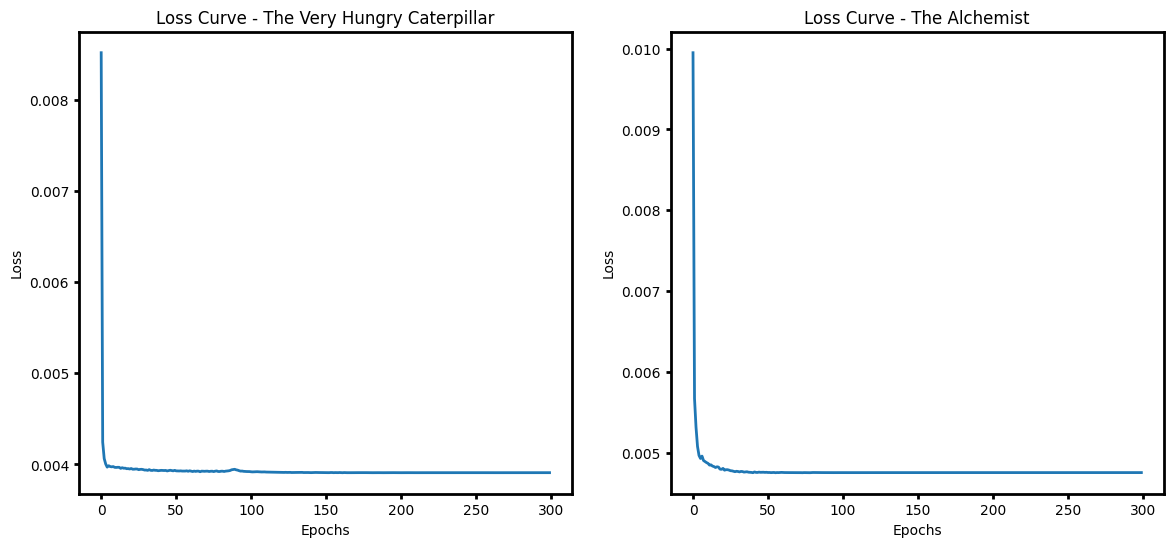

In [ ]:
# Loss Curves
# Visualise the loss curves
fig, axes = plt.subplots(1, 2, figsize=(14,6))
# Plot accuracy.
axes[0].plot(LSTM_tuned_caterpillar_resid_history.epoch,LSTM_tuned_caterpillar_resid_history.history['loss'],linewidth=2)
axes[1].plot(LSTM_tuned_alchemist_resid_history.epoch,LSTM_tuned_alchemist_resid_history.history['loss'],linewidth=2)

# titles
for i in range(2):
  axes[i].set_title(f"Loss Curve - {titles[i]}")
  axes[i].set_xlabel('Epochs')
  axes[i].set_ylabel('Loss')

axes =fig.axes
for ax in axes:
    ax.tick_params(width=2)
    # Change spine (axis line) thickness
    for edge in ['top', 'bottom', 'left', 'right']:
        ax.spines[edge].set_linewidth(2)
# plt.savefig('LSTM_losscurves_resid_final.svg')




In [ ]:
# Predict the 32-week residual forecast - book 1
scaled_predictions_caterpillar_resid_tuned=LSTM_tuned_caterpillar_resid.predict(X_test_caterpillar_resid)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step


In [ ]:
# Predict the 32-week residual forecast - book 2
scaled_predictions_alchemist_resid_tuned=LSTM_tuned_alchemist_resid.predict(X_test_alchemist_resid)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step


In [ ]:
# Re-scale and derive errors
y_pred_caterpillar_resid_tuned, MAE_caterpillar_resid_tuned, MAPE_caterpillar_resid_tuned = calculate_errors_resid(residuals_test_caterpillar,
                                                                                                                   scaled_predictions_caterpillar_resid_tuned)

y_pred_alchemist_resid_tuned, MAE_alchemist_resid_tuned, MAPE_alchemist_resid_tuned = calculate_errors_resid(residuals_test_alchemist,
                                                                                                             scaled_predictions_alchemist_resid_tuned)

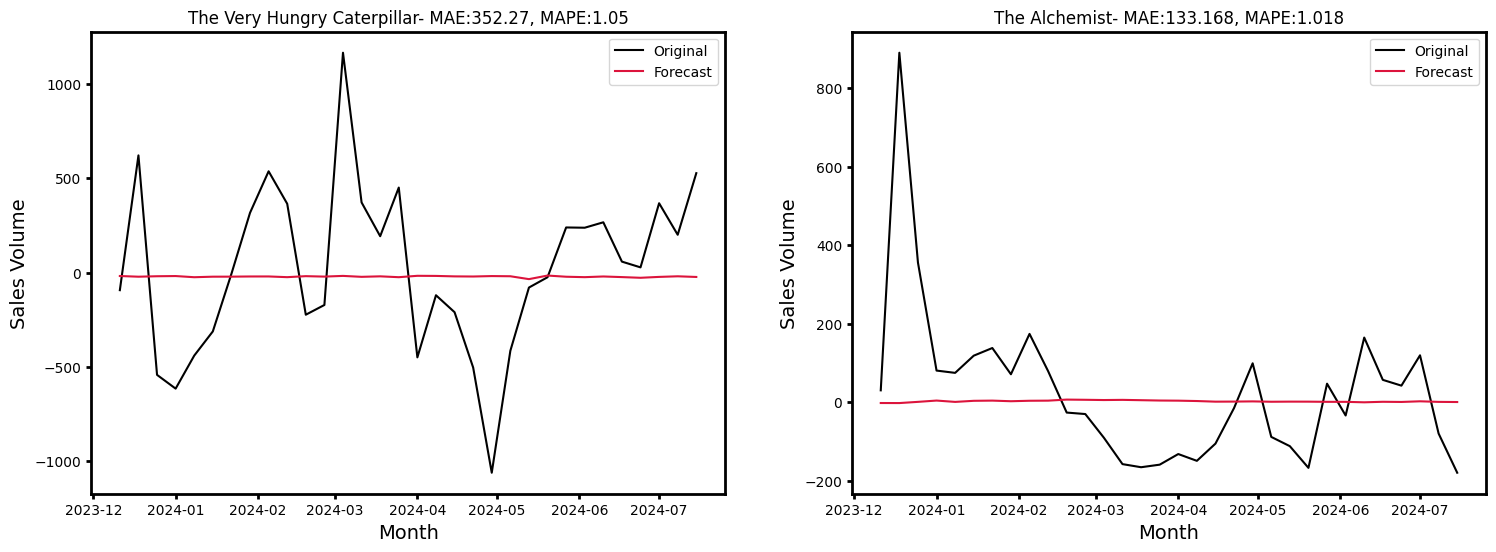

In [ ]:
# Preliminary checks:
fig, axes = plt.subplots(1,2, figsize=(18,6))

axes[0].plot(ts_caterpillar_test.index.to_timestamp(), residuals_test_caterpillar, c='black', label='Original')
axes[0].plot(ts_caterpillar_test.index.to_timestamp(), y_pred_caterpillar_resid_tuned,c='crimson', label='Forecast')

axes[1].plot(ts_alchemist_test.index.to_timestamp(), residuals_test_alchemist, c='black', label='Original')
axes[1].plot(ts_alchemist_test.index.to_timestamp(), y_pred_alchemist_resid_tuned, c='crimson', label='Forecast')

errors_list_final=[[MAE_caterpillar_resid_tuned, MAPE_caterpillar_resid_tuned],[MAE_alchemist_resid_tuned, MAPE_alchemist_resid_tuned]]

# titles
for i in range(2):
  axes[i].set_title(f"{titles[i]}- MAE:{round(errors_list_final[i][0],3)}, MAPE:{round(errors_list_final[i][1],3)}")
  axes[i].set_xlabel('Month',fontsize=14)
  axes[i].set_ylabel('Sales Volume',fontsize=14)
  axes[i].legend()

for i in range(2):
 axes[i].tick_params(width=2)
 for axs in ['top','bottom','left','right']:
    axes[i].spines[axs].set_linewidth(2)

 plt.savefig('Post_tuning_LSTM_checks_resid.svg')

**Determine the Best Models:**

Both the loss curves and the error scores have improved. Therefore, will use the tuned models.

In [ ]:
# Function to plot results
def plot_results_arima(title, series_train, series_test, arima_fitted_train,forecast, mae, mape, forecast_int,filename):
    fig=plt.figure(figsize=(12, 6))
    plt.title(f"{title} - MAE: {mae:.2f}, MAPE: {mape:.3f}", size=18)
    plt.plot(series_train.index.to_timestamp(),series_train.values,label="Train", color="blue")
    plt.plot(series_test.index.to_timestamp(),series_test.values,label="Test", color="coral")
    plt.plot(series_train.index.to_timestamp(),arima_fitted_train[:len(series_train)],color="cyan", linestyle='--', label='SARIMA fitted')
    plt.plot(series_test.index.to_timestamp(),forecast.flatten(),label="Forecast", color='green')

    plt.fill_between(
            series_test.index,
            forecast_int["lower"].flatten(),
            forecast_int["upper"].flatten(),
            alpha=0.3,
            color="lightgray",
            label="95% Prediction Interval"
        )

    plt.legend(prop={"size": 12})

    axes =fig.axes
    for ax in axes:
        ax.tick_params(width=2)
        # Change spine (axis line) thickness
        for edge in ['top', 'bottom', 'left', 'right']:
            ax.spines[edge].set_linewidth(2)

    plt.savefig(filename)
    plt.show()

In [ ]:
# Construct the final hybrid predictions
y_pred_hybrid_caterpillar = y_pred_arima_caterpillar + y_pred_caterpillar_resid_tuned.flatten()
y_pred_hybrid_alchemist = y_pred_arima_alchemist + y_pred_alchemist_resid_tuned.flatten()

In [ ]:
# Build the confidence intervals
hybrid_CI_caterpillar = build_CI(ts_caterpillar_test, y_pred_hybrid_caterpillar)
hybrid_CI_alchemist = build_CI(ts_alchemist_test, y_pred_hybrid_alchemist)

In [ ]:
# Compute errors
# Book 1
MAE_caterpillar_hybrid = mean_absolute_error(ts_caterpillar_test.values,y_pred_hybrid_caterpillar)
MAPE_caterpillar_hybrid = mean_absolute_percentage_error(ts_caterpillar_test.values,y_pred_hybrid_caterpillar)
# Book 2
MAE_alchemist_hybrid = mean_absolute_error(ts_alchemist_test.values,y_pred_hybrid_alchemist)
MAPE_alchemist_hybrid = mean_absolute_percentage_error(ts_alchemist_test.values,y_pred_hybrid_alchemist)


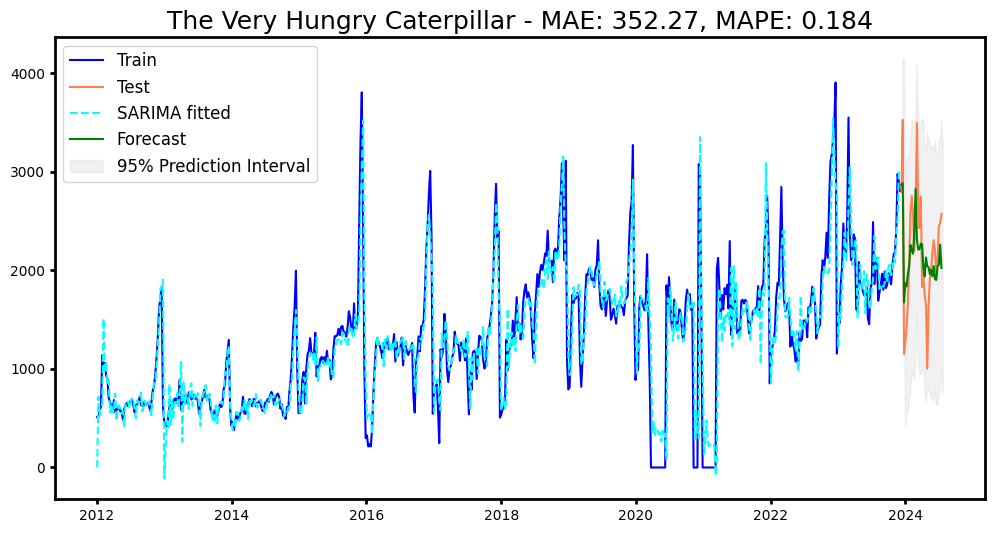

In [ ]:
# Book 1
plot_results_arima('The Very Hungry Caterpillar',
                  ts_caterpillar_train,
                  ts_caterpillar_test,
                  arima_fitted_caterpillar,
                  y_pred_hybrid_caterpillar,
                  MAE_caterpillar_hybrid,
                  MAPE_caterpillar_hybrid,
                  hybrid_CI_caterpillar,'hybrid_resid_forecast.svg')

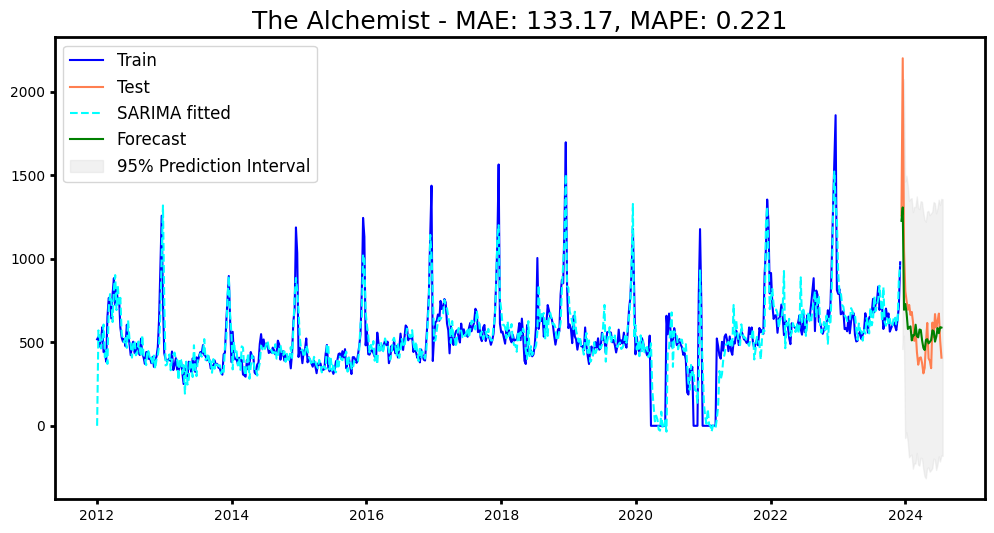

In [ ]:
# Book 2
plot_results_arima('The Alchemist',
                  ts_alchemist_train,
                  ts_alchemist_test,
                  arima_fitted_alchemist,
                  y_pred_hybrid_alchemist,
                  MAE_alchemist_hybrid,
                  MAPE_alchemist_hybrid,
                  hybrid_CI_alchemist,'hybrid_resid_forecast_alchemist.svg')

Given the fitted residuals have a nearly zero mean, adding them to the original SARIMA predictions is not likely to make a difference. Indeed both error scores remain similar to what was previously obtained with the SARIMA models in section $3.7$

### 5.2 Apply a hybrid model of SARIMA and LSTM in parallel combination wherein the predictions from SARIMA and the predictions from LSTM will be combined in the form of a weighted average. The final prediction will be the weighted sum of the predictions from SARIMA and LSTM. Both the SARIMA and the LSTM will be trained separately on the complete training set. The forecast horizon will be the final 32 weeks. Use KerasTuner to get the best model. Plot the results. Display the MAE and MAPE, and comment on the results.

For the two timeseries an optimal SARIMA model has been determined using an automated ARIMA search and applied to the final 32 weeks to make predictions in section $4.6$. Likewise, an LSTM model was trained, fitted and optimised (via hyperparameter tuning) on each timeseries for making predictions on the final 32 weeks in section $4.11$.

### 5.3 Modify the weightage in the parallel combination model to get different results. Find the weightage giving the best results, and comment on those results.

Therefore, for the parallel combination of the two models will be implemented as follows:

* Combination 1: [0.5 $\times$ ARIMA +  0.5 $\times$ LSTM ]
* Combination 2:[0.7 $\times$ ARIMA +  0.3 $\times$ LSTM ]
* Combination 3: [0.3 $\times$ ARIMA +  0.7 $\times$ LSTM ]


**BOOK 1: 'The Very Hungry Caterpillar'**

In [ ]:
# Get the arima predictions
y_pred_arima_caterpillar=arima_forecast_caterpillar.predicted_mean.values
y_pred_arima_caterpillar

array([2886.82124068, 2905.11371811, 1692.94759573, 1887.90027268,
       1860.79241452, 1990.53013977, 2068.26331961, 2277.81206583,
       2217.46070388, 2192.65279941, 2420.99192409, 2846.35556071,
       2329.74774452, 2232.61806093, 2233.75857574, 2294.71969933,
       2280.21242766, 2045.699142  , 1957.65226732, 2150.98418417,
       2062.81682603, 2049.35037254, 1995.93173262, 2021.29021474,
       1960.33055651, 2067.69176405, 1929.90137412, 1926.44300348,
       2068.94161159, 2079.81653831, 2281.08233799, 2046.35388718])

In [ ]:
# Forecast Combination 1:
forecast_c1_caterpillar= (y_pred_arima_caterpillar * 0.5) + (y_pred_caterpillar_tuned.flatten() * 0.5)
# Forecast Combination 2:
forecast_c2_caterpillar= (y_pred_arima_caterpillar * 0.7) + (y_pred_caterpillar_tuned.flatten() * 0.3)
# Forecast Combination 3:
forecast_c3_caterpillar = (y_pred_arima_caterpillar * 0.3) + (y_pred_caterpillar_tuned.flatten() * 0.7)

In [ ]:
# Calculate the errors
mae_scores_caterpillar=[]
mape_scores_caterpillar=[]
forecast_combos=[forecast_c1_caterpillar,forecast_c2_caterpillar,forecast_c3_caterpillar]
for combo in (forecast_combos):
  MAE= mean_absolute_error(ts_caterpillar_test.values,combo)
  MAPE= mean_absolute_percentage_error(ts_caterpillar_test.values,combo)
  mae_scores_caterpillar.append(MAE)
  mape_scores_caterpillar.append(MAPE)

In [ ]:
# Build the confidence intervals
c1_CI_caterpillar = build_CI(ts_caterpillar_test, forecast_c1_caterpillar)
c2_CI_caterpillar = build_CI(ts_caterpillar_test, forecast_c2_caterpillar)
c3_CI_caterpillar = build_CI(ts_caterpillar_test, forecast_c3_caterpillar)


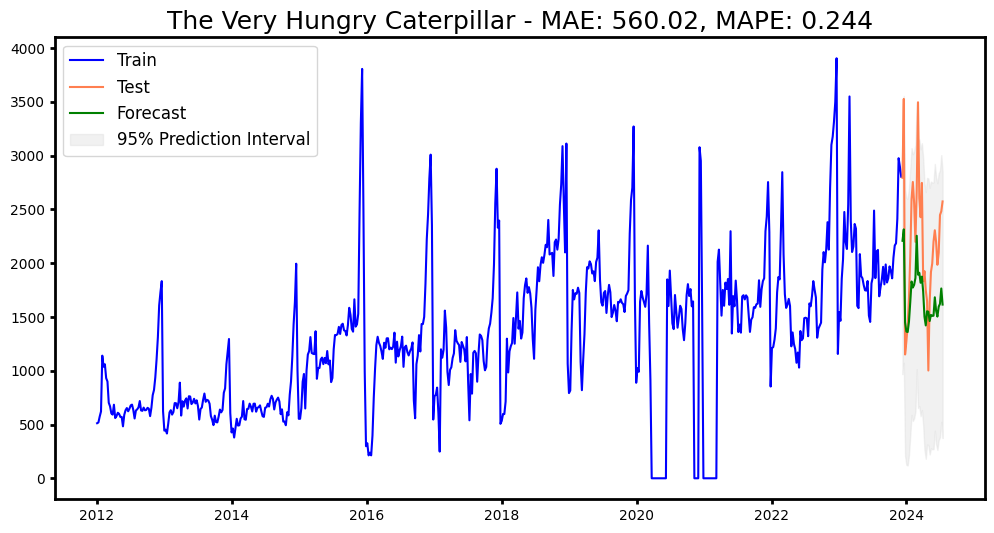

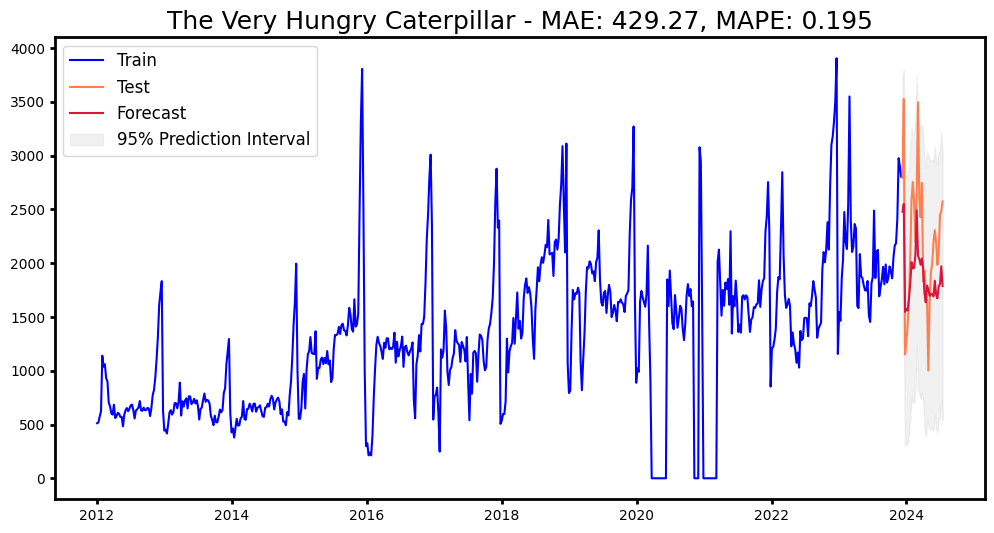

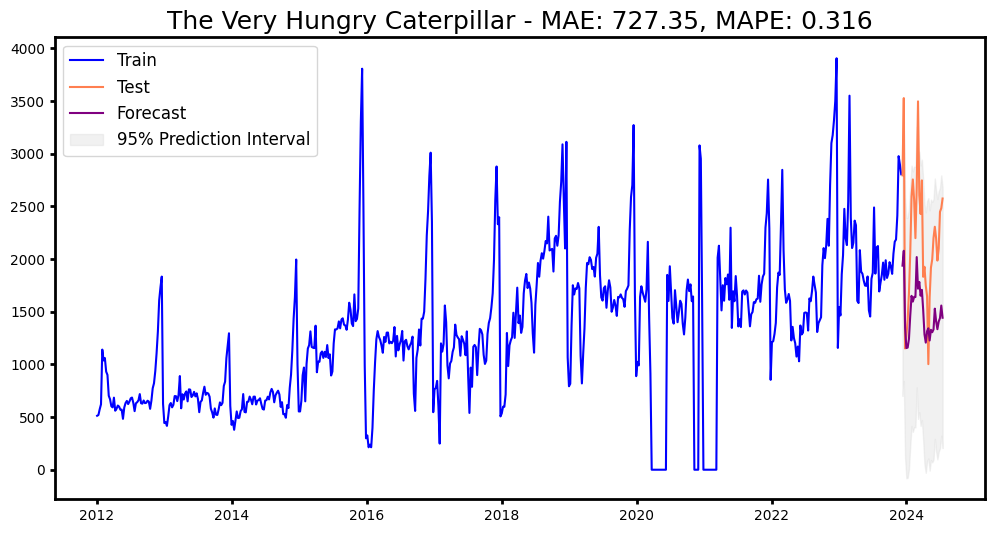

In [ ]:
# Book 1 - combo 1
plot_results('The Very Hungry Caterpillar',
                  ts_caterpillar_train,
                  ts_caterpillar_test,
                  forecast_c1_caterpillar,
                  mae_scores_caterpillar[0],
                  mape_scores_caterpillar[0],
                  c1_CI_caterpillar,'green','combo1_forecast.svg')
# Book 1 - combo 2
plot_results('The Very Hungry Caterpillar',
                  ts_caterpillar_train,
                  ts_caterpillar_test,
                  forecast_c2_caterpillar,
                  mae_scores_caterpillar[1],
                  mape_scores_caterpillar[1],
                  c2_CI_caterpillar,'crimson','combo2_forecast.svg')
# Book 1 - combo 3
plot_results('The Very Hungry Caterpillar',
                  ts_caterpillar_train,
                  ts_caterpillar_test,
                  forecast_c3_caterpillar,
                  mae_scores_caterpillar[2],
                  mape_scores_caterpillar[2],
                  c3_CI_caterpillar,'purple','combo3_forecast.svg')

Considering the predictions made by the LSTM model suffered issues with scaling whereby the forecasted sales volume consistently fell short of the actual volume recorded, combining the LSTM results with that of the SARIMA model significantly improves the error scores (LSTM forecast MAE: 1192.94, MAPE:0.515). Unsurprisingly, the best combination proves to be the combination in which the SARIMA forecast is given the highest weight followed by equal divide.

**BOOK 2: 'The Alchemist'**

In [ ]:
# # Get the arima predictions
y_pred_arima_alchemist=arima_forecast_alchemist.predicted_mean.values

# Forecast Combination 1:
forecast_c1_alchemist= (y_pred_arima_alchemist * 0.5) + (y_pred_alchemist_tuned.flatten() * 0.5)
# Forecast Combination 2:
forecast_c2_alchemist= (y_pred_arima_alchemist * 0.7) + (y_pred_alchemist_tuned.flatten() * 0.3)
# Forecast Combination 3:
forecast_c3_alchemist = (y_pred_arima_alchemist * 0.3) + (y_pred_alchemist_tuned.flatten() * 0.7)


# Calculate the errors
mae_scores_alchemist=[]
mape_scores_alchemist=[]
forecast_combos=[forecast_c1_alchemist,forecast_c2_alchemist,forecast_c3_alchemist]
for combo in (forecast_combos):
  MAE= mean_absolute_error(ts_alchemist_test.values,combo)
  MAPE= mean_absolute_percentage_error(ts_alchemist_test.values,combo)
  mae_scores_alchemist.append(MAE)
  mape_scores_alchemist.append(MAPE)

# Build the confidence intervals
c1_CI_alchemist = build_CI(ts_alchemist_test, forecast_c1_alchemist)
c2_CI_alchemist = build_CI(ts_alchemist_test, forecast_c2_alchemist)
c3_CI_alchemist = build_CI(ts_alchemist_test, forecast_c3_alchemist)


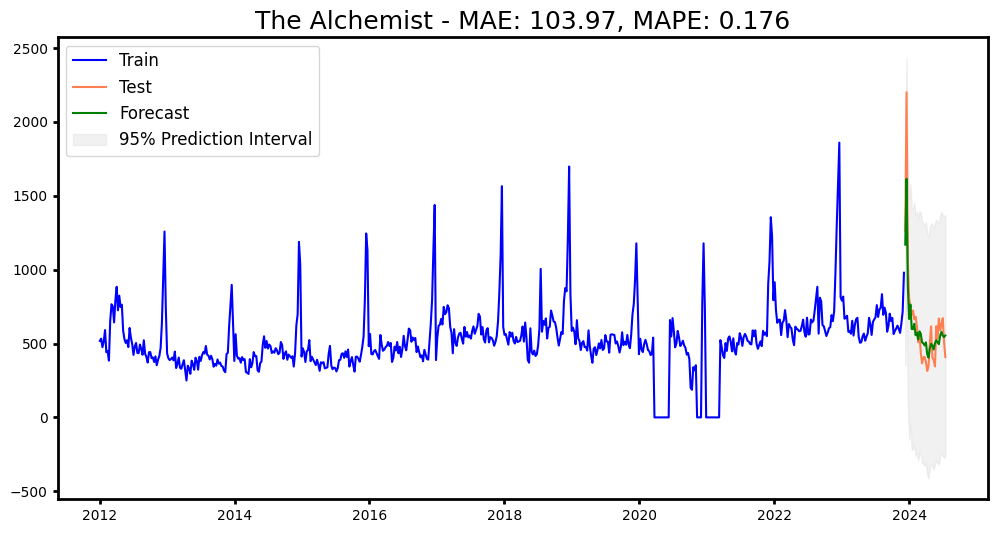

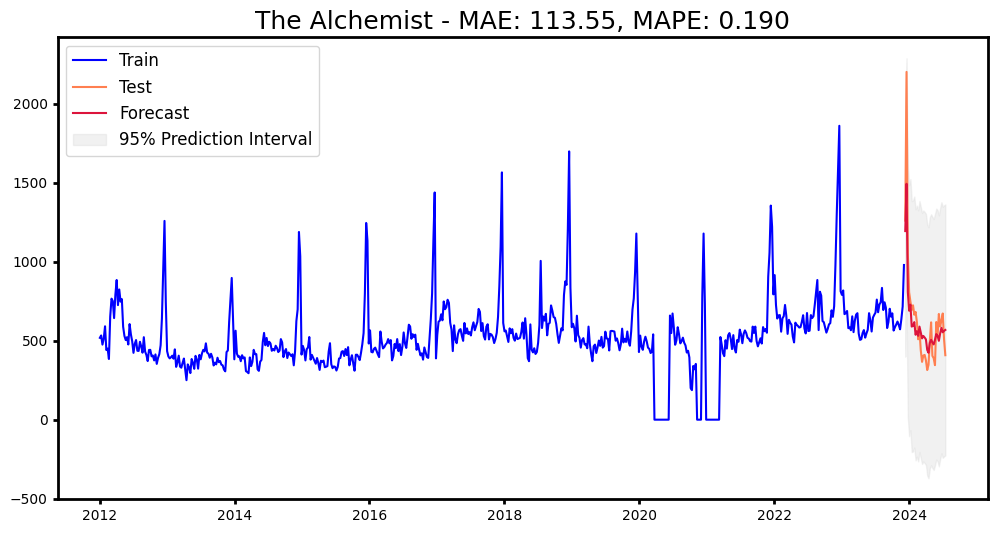

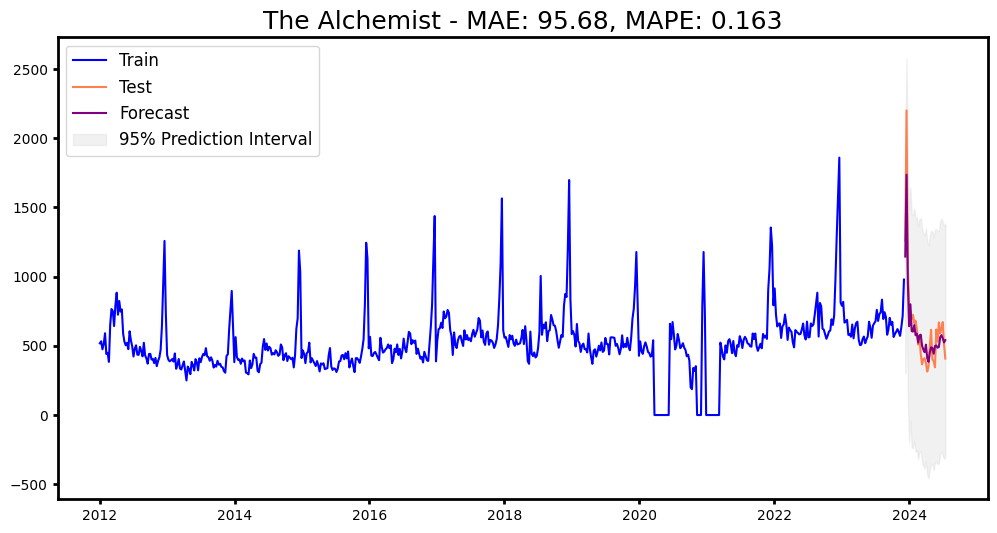

In [ ]:
# Book 2 - combo 1
plot_results('The Alchemist',
                  ts_alchemist_train,
                  ts_alchemist_test,
                  forecast_c1_alchemist,
                  mae_scores_alchemist[0],
                  mape_scores_alchemist[0],
                  c1_CI_alchemist,'green','combo1_forecast_alchemist.svg')

# Book 2 - combo 2
plot_results('The Alchemist',
                  ts_alchemist_train,
                  ts_alchemist_test,
                  forecast_c2_alchemist,
                  mae_scores_alchemist[1],
                  mape_scores_alchemist[1],
                  c2_CI_alchemist,'crimson','combo2_forecast_alchemist.svg')
# Book 2 - combo 3
plot_results('The Alchemist',
                  ts_alchemist_train,
                  ts_alchemist_test,
                  forecast_c3_alchemist,
                  mae_scores_alchemist[2],
                  mape_scores_alchemist[2],
                  c3_CI_alchemist,'purple','combo3_forecast_alchemist.svg')

In the case of 'The Alchemist', the combination that produces the smallest error scores is the one where the LSTM model predictions (MAE:106.60, MAPE:0.187) are given the highest weight followed by equal divide.This is because both the SARIMA (MAE:132.427, MAPE: 0.219) and the LSTM models predict a significantly shorter peak around 2024 with the discrepancy being larger for the SARIMA model. Also note that both models predict a small rise following the sharp peak when there is further decline due to the seasonal pattern.

## 6.Monthly Prediction

### 6.1 Instead of a weekly prediction, perform a monthly prediction. Aggregate the weekly sales data to monthly sales data for both books.


The montly sales volume would be the sum of all sales made each week within a given month:

In [ ]:
# Resample weekly book sales data to month sales data
book_data_caterpillar_monthly=book_data_caterpillar.resample('ME').sum()
book_data_alchemist_monthly=book_data_alchemist.resample('ME').sum()

In [ ]:
book_data_caterpillar_monthly

,Volume
End_Date,
2012-01-31,2226
2012-02-29,4168
2012-03-31,2874
2012-04-30,3023
2012-05-31,2223
...,...
2024-03-31,13949
2024-04-30,7153
2024-05-31,6551


In [ ]:
book_data_alchemist_monthly

,Volume
End_Date,
2012-01-31,2040
2012-02-29,1866
2012-03-31,2813
2012-04-30,3971
2012-05-31,2385
...,...
2024-03-31,2191
2024-04-30,1534
2024-05-31,1754


The number of samples/rows have been reduced by roughly a factor of ~4 as would be expected.

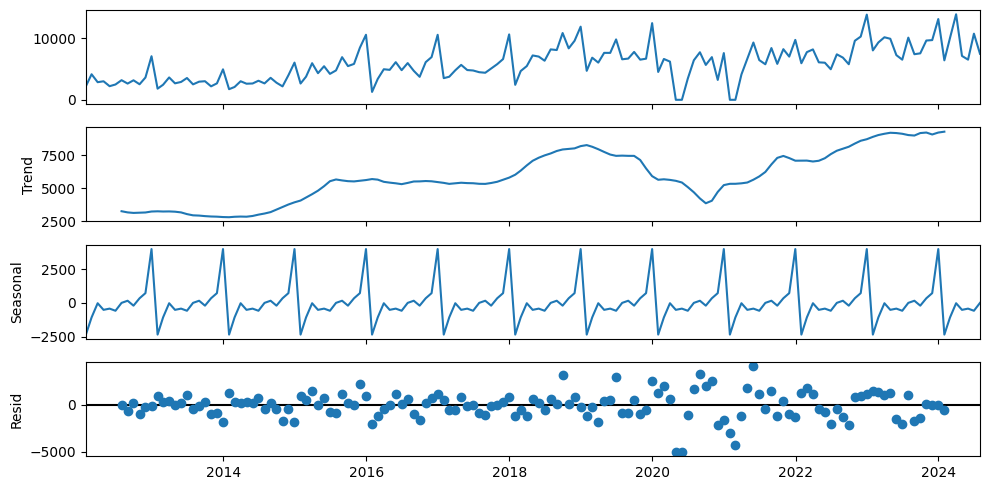

In [ ]:
# Decomposing 'The Very Hungry Caterpillar' timeseries
decomposition_caterpillar_additive_m = sm.tsa.seasonal_decompose(book_data_caterpillar_monthly, model='additive')
fig = decomposition_caterpillar_additive_m.plot()
plt.savefig('decomp_caterpillar_monthly.svg')
plt.show()

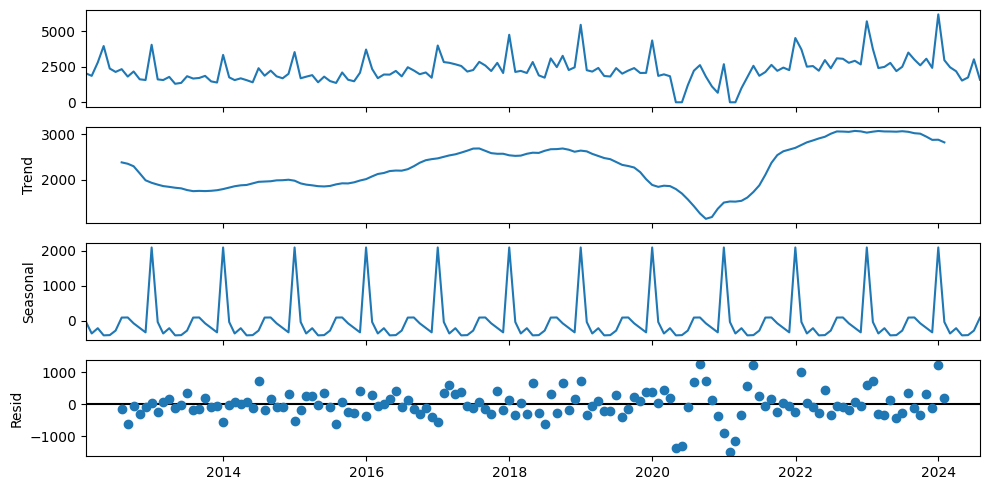

In [ ]:
# Decomposing 'The Alchemist' timeseries
decomposition_alchemist_additive_m = sm.tsa.seasonal_decompose(book_data_alchemist_monthly, model='additive')
fig = decomposition_alchemist_additive_m.plot()
plt.savefig('decomp_alchemist_monthly.svg')
plt.show()

The decomposition plots obtained for both titles indicate resampling the originally weekly data reduces the periodicity of the seasonal components from 52 to 12 which squeezes the peak patterns. The monthly series smooths the trend components due to integration of multiple weeks, while the Covid-related 'zero sales' window introduces deviations from what would normally be a non-linearly rising trend. For 'The Alchemist' timeseries there is a significant amplification in the residuals due to the sales volume being increased after summation to weekly sales,  possibly due to the very sharp weekly peaks being absorbed by the smaller monthly window.The effect is not as pronounced for 'The Hungry Caterpillar' timeseries residuals.

In [ ]:
# Perform a chronological train-test split as before:
# Book 1
y_train_caterpillar_monthly, y_test_caterpillar_monthly = book_data_caterpillar_monthly[:-8], book_data_caterpillar_monthly[-8:]
# Book 2
y_train_alchemist_monthly, y_test_alchemist_monthly = book_data_alchemist_monthly[:-8], book_data_alchemist_monthly[-8:]

In [ ]:
# Update the frequency layout on the training data before model fitting:

# Book 1
y_train_caterpillar_monthly.index.freq = 'ME'
y_test_caterpillar_monthly.index.freq = 'ME'

# Book 2
y_train_alchemist_monthly.index.freq = 'ME'
y_test_alchemist_monthly.index.freq = 'ME'

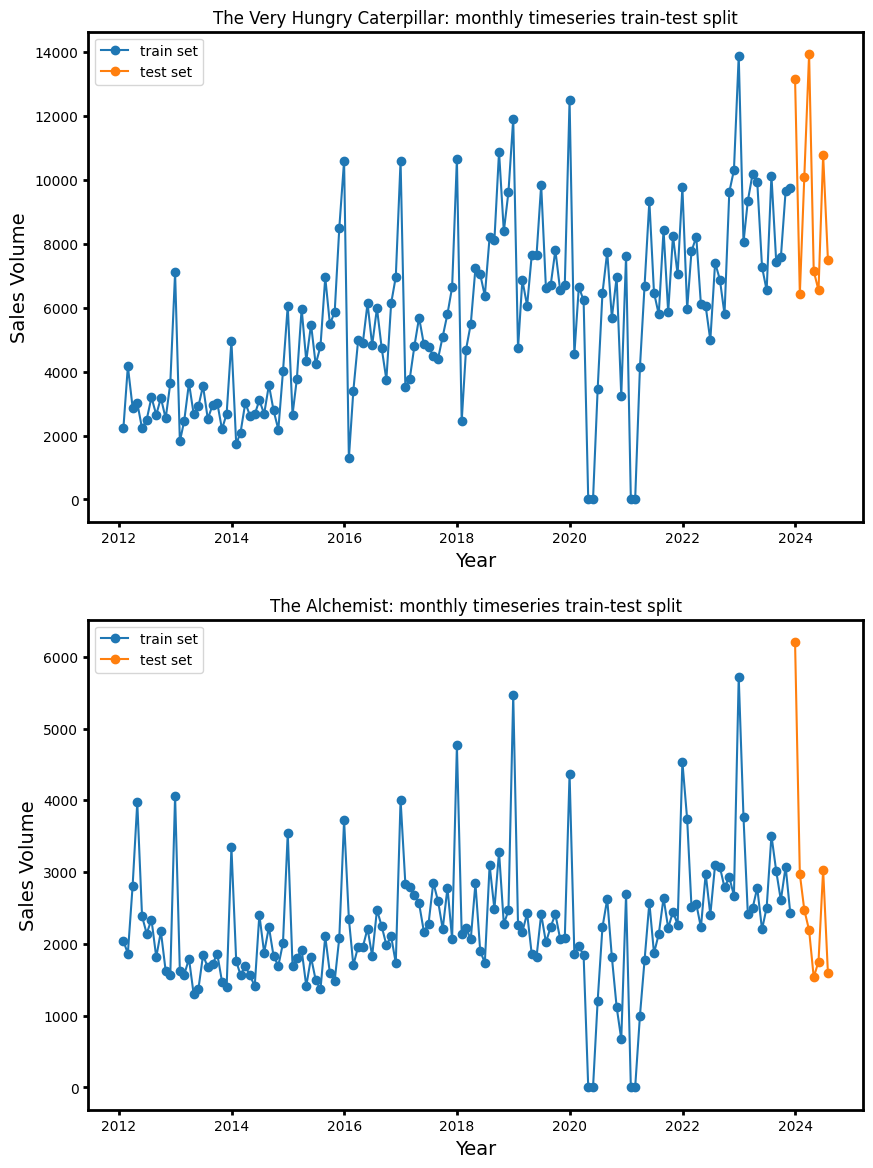

In [ ]:
# Visualise

fig, axes = plt.subplots(2, 1,figsize=(10,14))


axes[0].plot(y_train_caterpillar_monthly.index,y_train_caterpillar_monthly.values,'-o',label='train set')
axes[0].plot(y_test_caterpillar_monthly.index,y_test_caterpillar_monthly.values,'-o',label='test set')

axes[1].plot(y_train_alchemist_monthly.index,y_train_alchemist_monthly.values,'-o',label='train set')
axes[1].plot(y_test_alchemist_monthly.index,y_test_alchemist_monthly.values,'-o',label='test set')


# titles and labels
for i in range(2):
  axes[i].set_title(f"{titles[i]}: monthly timeseries train-test split")
  axes[i].set_xlabel('Year',fontsize=14)
  axes[i].set_ylabel('Sales Volume',fontsize=14)
  axes[i].legend(loc='upper left')

axes =fig.axes
for ax in axes:
    ax.tick_params(width=2)
    # Change spine (axis line) thickness
    for edge in ['top', 'bottom', 'left', 'right']:
        ax.spines[edge].set_linewidth(2)

plt.savefig('train_test_split_monthly.svg')
plt.show()

### 6.2 Train the XGBoost model on this data. Forecast using the trained model. The forecast horizon is 8 months. Plot the results, and calculate the MAE and MAPE.


In [ ]:
# Convert the exogenous variable X to a monthly series

X_xgb_caterpillar_monthly= (X_xgb_caterpillar.resample('ME').mean() > 0.5).astype(int)

X_xgb_alchemist_monthly=(X_xgb_alchemist.resample('ME').mean() > 0.5).astype(int)

In [ ]:
X_xgb_caterpillar_monthly['is_Covid'].value_counts()

,count
is_Covid,
0,139
1,12


<Axes: xlabel='End_Date'>

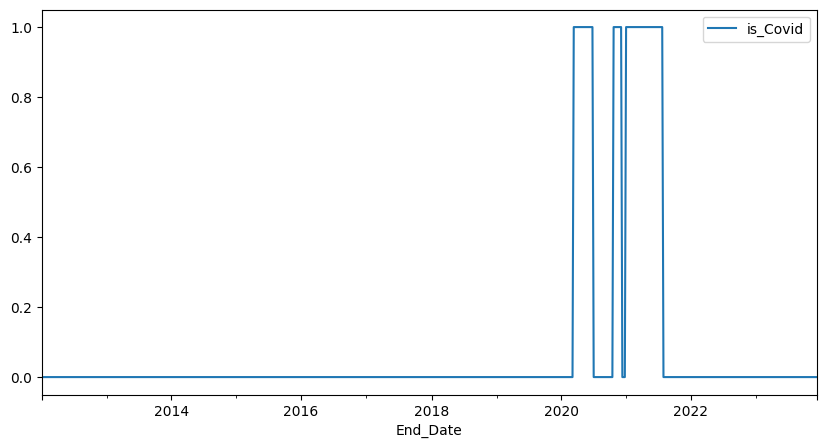

In [ ]:
X_train_alchemist.plot()

In [ ]:
# Perform train-test split on the exogenous input variable, X
# Book 1
X_train_caterpillar_monthly, X_test_caterpillar_monthly= X_xgb_caterpillar_monthly[:-8], X_xgb_caterpillar_monthly[-8:]
# Book 2
X_train_alchemist_monthly, X_test_alchemist_monthly= X_xgb_alchemist_monthly[:-8], X_xgb_alchemist_monthly[-8:]

To see the effect of the Covid period on the dataset training pattern will perfom cross validation again:

In [ ]:
cv_caterpillar_monthly=cross_validate_xgboost_forecaster(X_train_caterpillar_monthly.values,y_train_caterpillar_monthly.values,12,12,52,8)

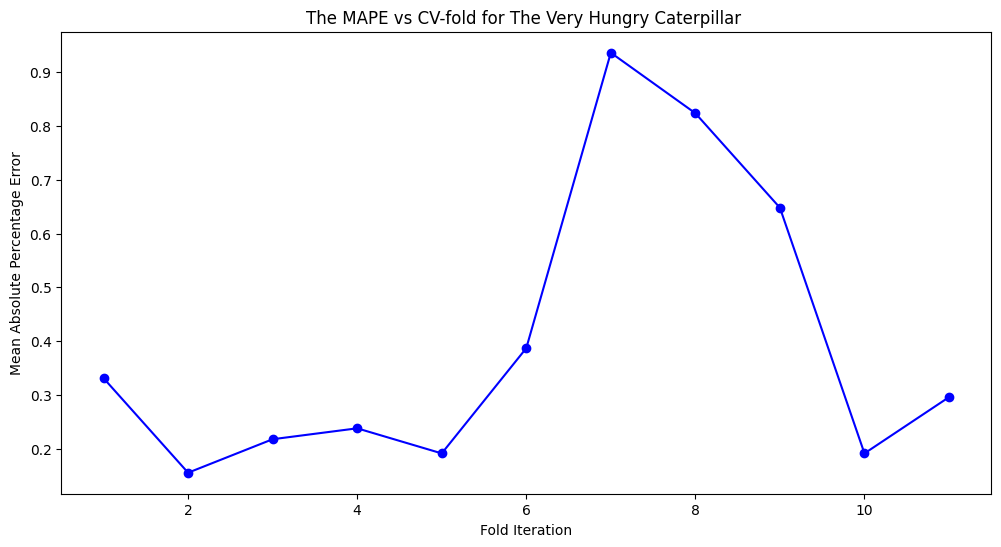

In [ ]:
# Visualise Results
plt.figure(figsize=(12, 6))
plt.plot(np.array(range(1,12,1)),cv_caterpillar_monthly['test_MeanAbsolutePercentageError'],'-ob')
plt.title('The MAPE vs CV-fold for The Very Hungry Caterpillar ')
plt.ylabel('Mean Absolute Percentage Error')
plt.xlabel('Fold Iteration')
plt.savefig('CV_caterpillar_monthly.svg')

In [ ]:
cv_alchemist_monthly=cross_validate_xgboost_forecaster(X_train_alchemist_monthly.values,y_train_alchemist_monthly.values,12,12,52,8)

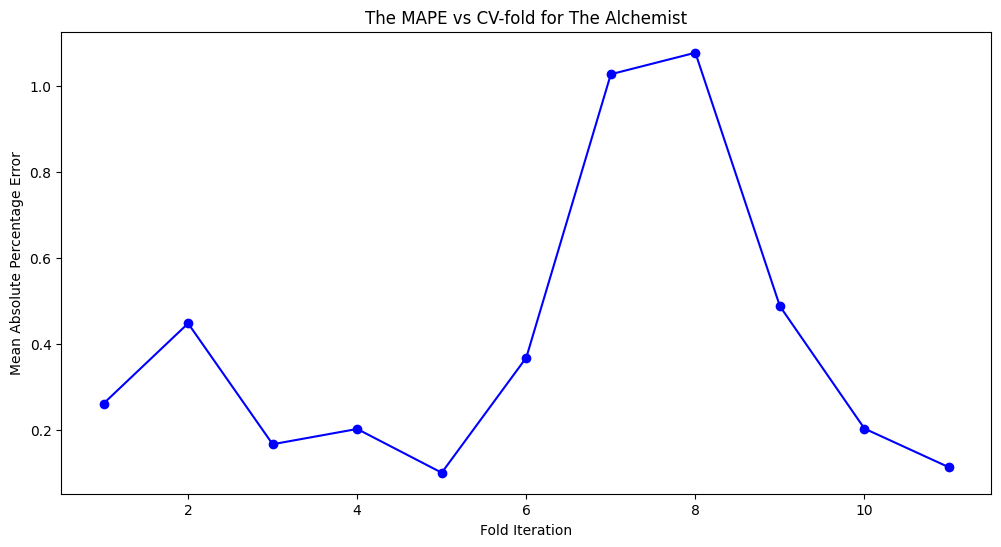

In [ ]:
# Visualise Results
plt.figure(figsize=(12, 6))
plt.plot(np.array(range(1,12,1)),cv_alchemist_monthly['test_MeanAbsolutePercentageError'],'-ob')
plt.title('The MAPE vs CV-fold for The Alchemist')
plt.ylabel('Mean Absolute Percentage Error')
plt.xlabel('Fold Iteration')
plt.savefig('CV_alchemist_monthly.svg')

In [ ]:
# Update the XGBoost pipeline with the new seasonality parameters:
# The Very Hungry Caterpillar
xgb_monthly_caterpillar=create_predictor_xgboost(seasonal_model='additive',sp=12,degree=1,window_length=12)
# The Alchemist
xgb_monthly_alchemist=create_predictor_xgboost(seasonal_model='additive',sp=12,degree=1,window_length=12)

Note that for a more direct comparison between the weekly and monthly data sets, will be sticking to an equivalent window_length of a full annual cycle (12 months ~ 52 weeks).

In [ ]:
# Fit the model on the monthly sales data
# Book 1
xgb_monthly_caterpillar_results=fit_xgboost_model(xgb_monthly_caterpillar,X_train_caterpillar_monthly.values,X_test_caterpillar_monthly.values,y_train_caterpillar_monthly.values,y_test_caterpillar_monthly.values,8)
# Book 2
xgb_monthly_alchemist_results=fit_xgboost_model(xgb_monthly_alchemist,X_train_alchemist_monthly.values,X_test_alchemist_monthly.values,y_train_alchemist_monthly.values,y_test_alchemist_monthly.values,8)

In [ ]:
# Make predictions for the 8 month (32 weeks) horizon
monthly_preds_xgb_caterpillar = xgb_monthly_caterpillar_results['predictions']
monthly_preds_xgb_alchemist = xgb_monthly_alchemist_results['predictions']

In [ ]:
# Build the CIs for plotting
monthly_forecast_int_caterpillar=build_CI(y_test_caterpillar_monthly,monthly_preds_xgb_caterpillar)
monthly_forecast_int_alchemist=build_CI(y_test_alchemist_monthly,monthly_preds_xgb_alchemist)

**Plots of the resulting forecast:**

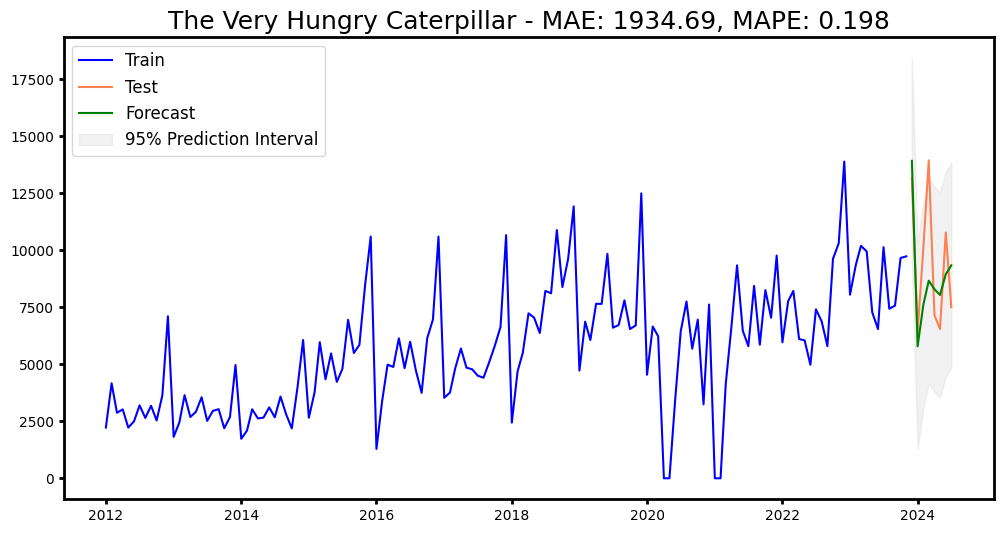

In [ ]:
# Book 1: 'The Very Hungry Caterpillar'
plot_results('The Very Hungry Caterpillar',
             y_train_caterpillar_monthly.to_period('M'),y_test_caterpillar_monthly.to_period('M'),
             monthly_preds_xgb_caterpillar,
             xgb_monthly_caterpillar_results['mae'], xgb_monthly_caterpillar_results['mape'],
             monthly_forecast_int_caterpillar,
             'green', 'XGBoost_monthly_forecast_caterpillar.svg')

Compare to prior error scores obtained for the weekly dataset:

In [ ]:
# Print model name and combination
print('\033[1m',titles[0], '\n', '-'*40,'\n')
print('\033[0m',f"Mean Absolute Error: {round(caterpillar_xgb_model_scores.loc[0,'MAE'],3)}", '\n')
print('\033[0m',f"Mean Absolute Percentage Error: {round(caterpillar_xgb_model_scores.loc[0,'MAPE'],3)}", '\n')

 The Very Hungry Caterpillar 
 ---------------------------------------- 

 Mean Absolute Error: 428.475 

 Mean Absolute Percentage Error: 0.196 



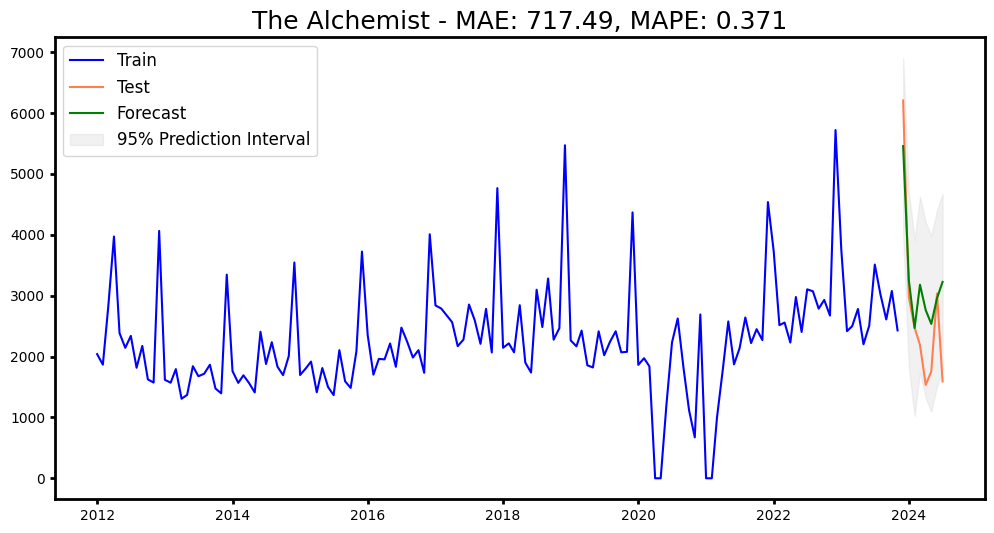

In [ ]:
# Book 2: 'The Alchemist'
plot_results('The Alchemist',
             y_train_alchemist_monthly.to_period('M'),y_test_alchemist_monthly.to_period('M'),
             monthly_preds_xgb_alchemist,
             xgb_monthly_alchemist_results['mae'], xgb_monthly_alchemist_results['mape'],
             monthly_forecast_int_alchemist,
             'green', 'XGBoost_monthly_forecast_alchemist.svg')

Compare to prior error scores obtained for the weekly dataset:

In [ ]:
# Print model name and combination
print('\033[1m',titles[1], '\n', '-'*40,'\n')
print('\033[0m',f"Mean Absolute Error: {round(alchemist_xgb_model_scores.loc[0,'MAE'],3)}", '\n')
print('\033[0m',f"Mean Absolute Percentage Error: {round(alchemist_xgb_model_scores.loc[0,'MAPE'],3)}", '\n')

 The Alchemist 
 ---------------------------------------- 

 Mean Absolute Error: 152.242 

 Mean Absolute Percentage Error: 0.216 



### 6.3 Train the SARIMA model (using Auto ARIMA) on this data. Forecast using the trained model. The forecast horizon is 8 months. Plot the results, and calculate the MAE and MAPE.


In [ ]:
set_random_seed(42)

In [ ]:
# Perform auto ARIMA on 'The Very Hungry Caterpillar' montly sales data
arima_caterpillar_monthly= auto_arima(y=y_train_caterpillar_monthly, X=None,
                              start_p=0, d=None, start_q=0, max_p=2, max_d=1, max_q=2,
                              start_P=0, D=None, start_Q=0, max_P=2, max_D=1, max_Q=2,
                              max_order=10, m=12, seasonal=True, stationary=False,
                              information_criterion='aic', alpha=0.05,
                              test='kpss', seasonal_test='ocsb',
                              stepwise=True, n_jobs=1, start_params=None, trend=None,
                              method='lbfgs', maxiter=50, offset_test_args=None, seasonal_test_args=None,
                              suppress_warnings=True, error_action='trace',
                              trace=False, random=False, random_state=None, n_fits=10,
                              return_valid_fits=False, out_of_sample_size=0, scoring='mse',
                              scoring_args=None, with_intercept='auto', sarimax_kwargs=None)

# Print model results.
arima_caterpillar_monthly.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                     SARIMAX Results                                      
==========================================================================================
Dep. Variable:                                  y   No. Observations:                  143
Model:             SARIMAX(1, 1, 1)x(1, 0, 1, 12)   Log Likelihood               -1262.329
Date:                            Fri, 23 Oct 2026   AIC                           2534.658
Time:                                    10:32:28   BIC                           2549.437
Sample:                                02-05-2012   HQIC                          2540.663
                                     - 12-03-2023                                         
Covariance Type:                              opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.5533      0.077      7.148      0.000       0.402       0.705
ma.L1         -0.9532      0.032    -30.120      0.000      -1.015      -0.891
ar.S.L12       0.9613      0.049     19.701      0.000       0.866       1.057
ma.S.L12      -0.7297      0.134     -5.461      0.000      -0.992      -0.468
sigma2      2.796e+06   2.59e+05     10.809      0.000    2.29e+06     3.3e+06
===================================================================================
Ljung-Box (L1) (Q):                   0.12   Jarque-Bera (JB):                48.96
Prob(Q):                              0.73   Prob(JB):                         0.00
Heteroskedasticity (H):               2.85   Skew:                            -0.82
Prob(H) (two-sided):                  0.00   Kurtosis:                         5.36
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [ ]:
# Check for Convergence
if arima_caterpillar_monthly.arima_res_.mle_retvals['converged']:
    print("Model converged successfully.")
else:
    print("Model did not converge.")

Model converged successfully.


**'The Very Hungry Caterpillar' Best Model**

Model:	SARIMAX(1, 1, 1)x(1, 0, 1, 12)

> Non-Seasonal Components
* AR(1): Uses one autoregressive lag meaning the current value is predicted based on the previous month.
* diff(1): Differences once to handle trend.
* MA(1): Uses one forecast error to capture residual noise patterns to help with short-term shock smoothing.
* No intercept.

> Seasonal Components
* AR(1): Uses one seasonal autoregressive lag meaning the current week's value is regressed on the value from exactly 52 weeks ago.
* diff(0): No seasonal differencing is applied meaning the seasonal pattern is assumed to be stable.
* MA(1): Includes the forecast errors from exactly 12 months ago (lag 1, $L^m$)
* m=12:  Owing to monthly time series - 12 periods per year.

> X: signifies the model can include external variables.


In [ ]:
# Perform auto ARIMA on 'The Very Hungry Caterpillar' montly sales data
arima_alchemist_monthly= auto_arima(y=y_train_alchemist_monthly, X=None,
                              start_p=0, d=None, start_q=0, max_p=2, max_d=1, max_q=2,
                              start_P=0, D=None, start_Q=0, max_P=2, max_D=1, max_Q=2,
                              max_order=10, m=12, seasonal=True, stationary=False,
                              information_criterion='aic', alpha=0.05,
                              test='kpss', seasonal_test='ocsb',
                              stepwise=True, n_jobs=1, start_params=None, trend=None,
                              method='lbfgs', maxiter=50, offset_test_args=None, seasonal_test_args=None,
                              suppress_warnings=True, error_action='trace',
                              trace=False, random=False, random_state=None, n_fits=10,
                              return_valid_fits=False, out_of_sample_size=0, scoring='mse',
                              scoring_args=None, with_intercept='auto', sarimax_kwargs=None)

# Print model results.
arima_alchemist_monthly.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                     SARIMAX Results                                      
==========================================================================================
Dep. Variable:                                  y   No. Observations:                  143
Model:             SARIMAX(0, 0, 1)x(1, 0, 1, 12)   Log Likelihood               -1132.140
Date:                            Fri, 23 Oct 2026   AIC                           2274.280
Time:                                    11:33:36   BIC                           2289.094
Sample:                                01-31-2012   HQIC                          2280.300
                                     - 11-30-2023                                         
Covariance Type:                              opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept    561.4894    202.086      2.778      0.005     165.407     957.571
ma.L1          0.4834      0.068      7.061      0.000       0.349       0.618
ar.S.L12       0.7739      0.078      9.881      0.000       0.620       0.927
ma.S.L12      -0.2912      0.136     -2.146      0.032      -0.557      -0.025
sigma2      3.973e+05   4.24e+04      9.371      0.000    3.14e+05     4.8e+05
===================================================================================
Ljung-Box (L1) (Q):                   2.76   Jarque-Bera (JB):                 6.05
Prob(Q):                              0.10   Prob(JB):                         0.05
Heteroskedasticity (H):               2.17   Skew:                             0.10
Prob(H) (two-sided):                  0.01   Kurtosis:                         3.99
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [ ]:
# Check for Convergence
if arima_alchemist_monthly.arima_res_.mle_retvals['converged']:
    print("Model converged successfully.")
else:
    print("Model did not converge.")

Model did not converge.


Note the model has not converged for a maximum of 50 iterations.

**'The Alchemist' Best Model**

Model:	SARIMAX(0, 0, 1)x(1, 0, 1, 12)

> Non-Seasonal Components
* AR(0): No autoregressive components are used.
* diff(0): No differecing is applied.
* MA(1): Uses one forecast error term from 1 month ago to capture residual noise patterns.
* An intercept is also added.

> Seasonal Components
* AR(1): Uses one seasonal autoregressive lag meaning the current month's value is regressed on the value from 12 months ago.
* diff(0): Once again no seasonal differencing is applied and the seasonal pattern is assumed to be stable.
* MA(1): Uses one seasonal forecast error term to adjust the current prediction.
* m=12:  Owing to monthly time series - 12 periods per year.

> X: signifies the model can include external variables.

In [ ]:
# Instantiate the model for 'The Very Hungry Caterpilar'
arima_caterpillar_monthly = SARIMAX(endog=y_train_caterpillar_monthly,
                            order=(1, 1, 1),
                            seasonal_order=(1, 0, 1, 12),
                            trend='n',
                            enforce_stationarity=False,
                            enforce_invertibility = True)

# Instantiate the model for 'The Alchemist'
arima_alchemist_monthly = SARIMAX(endog=y_train_alchemist_monthly,
                          order=(0, 0, 1),
                          seasonal_order=(1, 0, 1, 12),
                          trend='c',
                          enforce_stationarity=False,
                          enforce_invertibility = True)

In [ ]:
# Fit the models
# List to store result and AIC values
monthly_results=[]

models=[arima_caterpillar_monthly,arima_alchemist_monthly]
for i,model in enumerate(models):
  # Fit the model
  results = model.fit(maxiter=500, disp=False)

  # Store the results in a list
  monthly_results.append(results)
  titles=['The Very Hungry Caterpillar','The Alchemist']

  # Print the current combination and its AIC
  print(titles[i],'AIC:',results.aic)

The Very Hungry Caterpillar AIC: 2280.3687223713177
The Alchemist AIC: 2070.415242981911


In both cases, the AIC scores are significanly reduced. This is because the new models returned by the auto ARIMA search are much simpler which reduces the complexity penalty.

In [ ]:
counter=0
titles=['The Very Hungry Caterpillar','The Alchemist']
for title,results in zip(titles,monthly_results):
  # Print model name and combination
  print('\033[1m',title, '\n', '-'*90,'\n')
  print(f"Model {counter+1} converged? {results.mle_retvals['converged']}")
  print('\033[0m',results.summary(), '\n')
  counter+=1

 The Very Hungry Caterpillar 
 ------------------------------------------------------------------------------------------ 

Model 1 converged? True
                                      SARIMAX Results                                      
Dep. Variable:                             Volume   No. Observations:                  143
Model:             SARIMAX(1, 1, 1)x(1, 0, 1, 12)   Log Likelihood               -1135.184
Date:                            Fri, 23 Oct 2026   AIC                           2280.369
Time:                                    11:33:48   BIC                           2294.629
Sample:                                01-31-2012   HQIC                          2286.163
                                     - 11-30-2023                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------

**'The Very Hungry Caterpillar' Residual Diagnostics**

* Prob(Q) > 0.05, fail to reject the null hypothesis. There is no significant autocorrelation remaining.
* Prob(JB) < 0.05, rejects the null hypothesis that the distribution is normal.
* A skew of -0.96 and a kurtosis of 5.62 means the distribution is slightly left skewed and have a slightly heavier tail.
* Prob(H) < 0.05, can reject the null hypothesis. The variance is unstable.
* Checking for the 3 criterion : no autocorrelation, close to normal distribution, non-constant variance. Therefore, perfectly satisfies only 1.

**'The Alchemist' Residual Diagnostics**

* Prob(Q) > 0.05, fail to reject the null hypothesis. There is no significant autocorrelation remaining.
* Prob(JB) < 0.05, rejects the null hypothesis that the distribution is normal.
* A skew of 0.47 and a kurtosis of 4.32 means the distribution is very slightly right skewed and have a slightly heavier tail.
* Prob(H) < 0.05, can reject the null hypothesis. The variance is unstable.
* Checking for the 3 criterion: no autocorrelation, close to normal distribution, non-constant variance. Therefore, perfectly satisfies only 1.

In [ ]:
# Obtain ARIMA predictions and residuals on the training data
# The Very Hungry Caterpillar
arima_monthly_fitted_caterpillar=monthly_results[0].fittedvalues
arima_monthly_resid_caterpillar=monthly_results[0].resid

# The Alchemist
arima_monthly_fitted_alchemist=monthly_results[1].fittedvalues
arima_monthly_resid_alchemist=monthly_results[1].resid

In [ ]:
# Predict the Forecast and get the CI
# The Very Hungry Caterpillar
arima_monthly_forecast_caterpillar = monthly_results[0].get_forecast(steps=8)
arima_monthly_CI_caterpillar=arima_monthly_forecast_caterpillar.conf_int()

# The Alchemist
arima_monthly_forecast_alchemist = monthly_results[1].get_forecast(steps=8)
arima_monthly_CI_alchemist = arima_monthly_forecast_alchemist.conf_int()

Update the plotting function since we are now using PeriodIndex as opposed to DatetimeIndex:

In [ ]:
def plot_arima_results_monthly(title,original_data,y_train,arima_fitted,arima_forecast,arima_CI,filename):
  fig=plt.figure(figsize=(14, 4))
  n_split=len(y_train)
  # Standardise all indices to pure timestamps, ensuring there are no hidden Period conversions

  fitted_x = arima_fitted.index.to_timestamp() if hasattr(arima_fitted.index, 'to_timestamp') else arima_fitted.index
  forecast_x = arima_forecast.predicted_mean.index.to_timestamp() if hasattr(arima_forecast.predicted_mean.index, 'to_timestamp') else arima_forecast.predicted_mean.index
  ci_x = arima_CI.index.to_timestamp() if hasattr(arima_CI.index, 'to_timestamp') else arima_CI.index

  # Plot using explicit x and y arrays
  plt.plot(original_data, c='0')
  plt.plot(fitted_x[:n_split], arima_fitted.values[:n_split], '--', c='c')
  plt.plot(forecast_x, arima_forecast.predicted_mean.values, c='crimson')
  plt.plot(ci_x, arima_CI['lower Volume'], ':', c='grey', linewidth=3)
  plt.plot(ci_x, arima_CI['upper Volume'], ':', c='grey', linewidth=3)

  plt.title(f"Observed vs Predicted Sales Volume -- {title}", fontdict={'size':14, 'color':'navy', 'weight':'bold'})
  plt.xlabel('Time', fontsize=14)
  plt.ylabel('Sales Volume', fontsize=14)
  plt.legend(['Observed', 'Fitted', 'Forecast', '95% CI'])

  axes = fig.axes
  for ax in axes:
      ax.tick_params(width=2)
      for edge in ['top', 'bottom', 'left', 'right']:
          ax.spines[edge].set_linewidth(2)

  plt.savefig(filename)

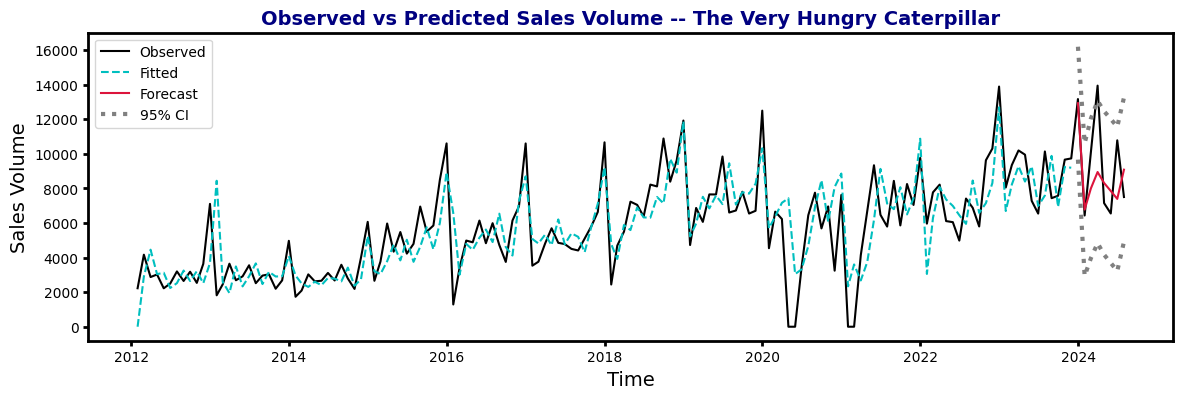

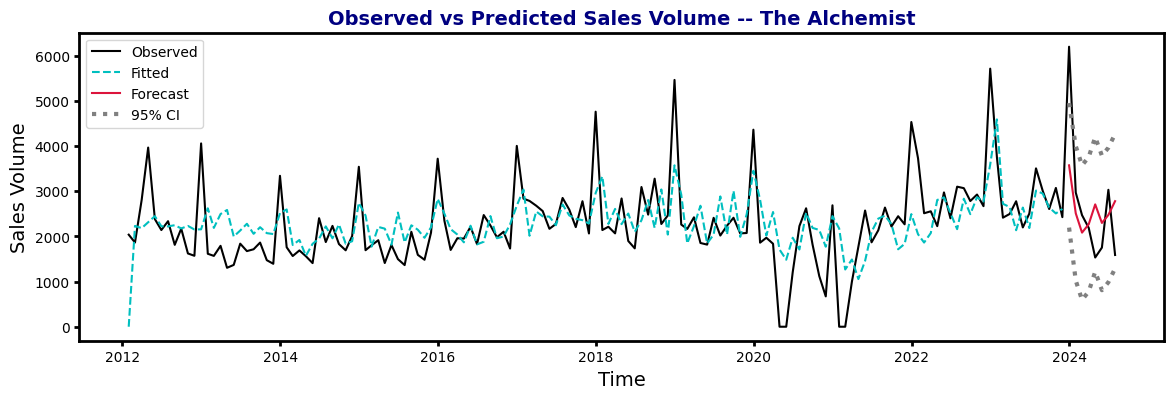

In [ ]:
# Plot the predictions for Book 1
plot_arima_results_monthly('The Very Hungry Caterpillar',
                   book_data_caterpillar_monthly,y_train_caterpillar_monthly,
                   arima_monthly_fitted_caterpillar,arima_monthly_forecast_caterpillar,
                   arima_monthly_CI_caterpillar,
                   'arima_caterpillar_monthly.svg')


# Plot the predictions for Book 2
plot_arima_results_monthly('The Alchemist',
                   book_data_alchemist_monthly,y_train_alchemist_monthly,
                   arima_monthly_fitted_alchemist,arima_monthly_forecast_alchemist,
                   arima_monthly_CI_alchemist,
                   'arima_alchemist_monthly.svg')

Upon converting to monthly data, the sampling grid becomes much coarser which is causing the SARIMA models to yield worse fits. For both time series, the 'burn' period where the model parameters suffer an initiation bias also lasts longer than before.

While the forecast produced for 'The Very Hungry Caterpillar' shows reasonable agreement with the actual sales volume within ~ 2 standard deviations, the predictions obtained for 'The Alchemist' time series significantly undershoots and completely misses the dip that follows the final sharp peak. This is because the SARIMA model is making predictions that are more in line with the seasonal pattern (and not the long-term trend).

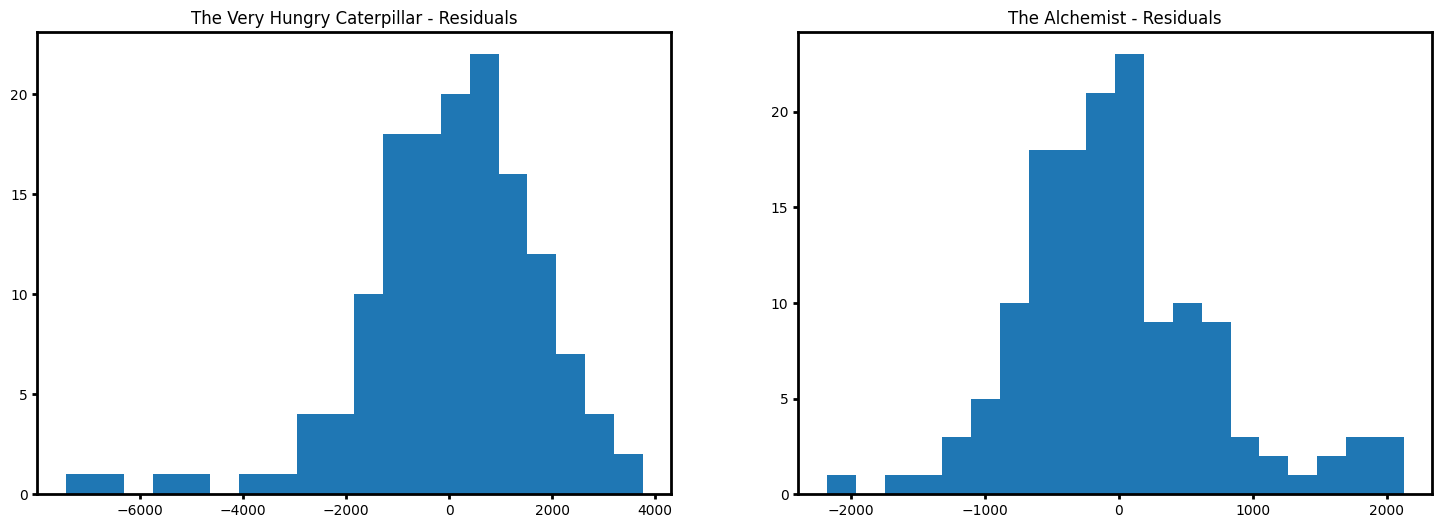

In [ ]:
# Preliminary checks:
fig, axes = plt.subplots(1,2, figsize=(18,6))

axes[0].hist(arima_monthly_resid_caterpillar, bins=20)

axes[1].hist(arima_monthly_resid_alchemist, bins=20)

# titles
for i in range(2):
  axes[i].set_title(f"{titles[i]} - Residuals")

for i in range(2):
 axes[i].tick_params(width=2)
 for axs in ['top','bottom','left','right']:
    axes[i].spines[axs].set_linewidth(2)

plt.savefig('arima_monthly_resids.svg')

In [ ]:
# Calculate MSE
titles=['The Very Hungry Caterpillar','The Alchemist']
arima_predictions=[arima_monthly_forecast_caterpillar.predicted_mean,arima_monthly_forecast_alchemist.predicted_mean]
test_data=[y_test_caterpillar_monthly,y_test_alchemist_monthly]

for title,test,forecast in zip(titles, test_data, arima_predictions):
  # mse = mean_squared_error(test, forecast)
  mae = mean_absolute_error(test,forecast)
  mape = mean_absolute_percentage_error(test,forecast)
  # Print model name and combination
  print('\033[1m',title, '\n', '-'*40,'\n')
  print('\033[0m',f"Mean Absolute Error: {round(mae,3)}", '\n')
  print('\033[0m',f"Mean Absolute Percentage Error: {round(mape,3)}", '\n')

 The Very Hungry Caterpillar 
 ---------------------------------------- 

 Mean Absolute Error: 1889.7 

 Mean Absolute Percentage Error: 0.191 

 The Alchemist 
 ---------------------------------------- 

 Mean Absolute Error: 878.759 

 Mean Absolute Percentage Error: 0.348 



### 6.4 Compare and contrast the monthly predictions of both books against the weekly predictions. Comment on which one is more accurate or if they are the same.

* Upon converting the weekly timeseries into a monthly one, the data has been down sampled by 3/4. While before there were 52 time units per cycle, there are now 12 time units which reduces the sampling frequency.

* As can be seen from the decompositon plots, the coarser resolution has the effect of compressing the seasonal trend while smoothing the long-term trend.

* Based on the central limit theorem, the error of the sample mean scales with the inverse square root of the number of observations. So based on the number of observations decreasing alone, an increase in error would be expected.

* In the case of both the XGBoost forecast and the SARIMA forecast, an increase in error scores is observed for 'The Alchemist' timeseries whereas a decrease is observed for 'The Very Hungry Caterpillar'.

* Stepping back, while a week is fixed at 7 days, the number of days within each month changes (28-31 days). Thus, aggregating the weekly data squeezes fractional weeks into the shorter monthly intervals which:

<ul type="none">

<ol type="number">
<li> causes some of the sharper weekly peaks being absorbed by the monthly window which slightly smooths the seasonal pattern.</li>

<li> increases the intra-grid (inter-window) variance.</li>
</ol>
</ul>

* Since 'The Very Hungry Caterpillar' time series presents with broader shorter peaks, the compressed distribution across the monthly grid helps close the gap between the actual monthly volume sales and the forecast predictions.

* For 'The Alchemist' time series which presents with much sharper peaks, the compressing effect is counteracted by the increased variance and the over-smoothing, which causes the error on the predictions to increase slightly.